# Stock Market Analytics & Trend Prediction on NIFTY-50 Stocks

Machine Learning course project covering all five units. Every number below comes from a code cell in this notebook. Each is written to `results/results.json`, and each figure to `figures/`.

| Unit | Assigned title |
|---|---|
| 1 | Distribution analysis of daily log-returns of NIFTY-50 stocks; quantiles (Value-at-Risk), volatility & covariance |
| 2 | Next-day closing price prediction with ridge & Bayesian linear regression; up/down movement classification with Bayesian logistic regression & SVM |
| 3 | Clustering NIFTY-50 stocks by return–volatility behaviour using K-means, GMM & hierarchical clustering; PCA market factors |
| 4 | HMM for detecting hidden market regimes (bull / bear / sideways) with Viterbi decoding; Kalman filter for price trend |
| 5 | Ensemble prediction of daily price direction using CART, Random Forest, AdaBoost & Gradient Boosting |

Dataset: Kaggle "NIFTY-50 Stock Market Data (2000–2021)". The archive is unzipped into `data/`.

## 0. Setup

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"]:
    os.environ[_v] = "1"
import glob, json, math, warnings, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, optimize, linalg
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
DATA_DIR, FIG_DIR, RES_DIR, WEB_DATA = "data", "figures", "results", os.path.join("web", "public", "data")
for _d in [FIG_DIR, RES_DIR, WEB_DATA]:
    os.makedirs(_d, exist_ok=True)
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 70)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 140, "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
                     "legend.fontsize": 10, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

R = {}        # every reported number
CHARTS = {}   # one compact JSON per chart for the results explorer

def savefig(name):
    # PNG metadata is cleared so that no software or author tag is stored in the file
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight", metadata={"Software": None})

def obs(text):
    # observations are rendered from computed values, so they cannot drift from the results
    display(Markdown("**Observations.** " + text))

def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, np.ndarray): return _clean(o.tolist())
    if isinstance(o, (bool, np.bool_)): return bool(o)
    if isinstance(o, (int, np.integer)): return int(o)
    if isinstance(o, (float, np.floating)):
        f = float(o)
        if not math.isfinite(f): return None
        return float(f"{f:.10g}")   # 10 significant digits: removes round-off noise between runs
    if isinstance(o, (pd.Timestamp, np.datetime64)): return str(pd.Timestamp(o).date())
    if o is None or isinstance(o, str): return o
    return str(o)

def save_results():
    with open(os.path.join(RES_DIR, "results.json"), "w") as f:
        json.dump(_clean(R), f, indent=1, sort_keys=True, ensure_ascii=False)

def chart(name, obj):
    CHARTS[name] = obj

def fmt_p(p):
    return f"{p:.2e}" if p < 1e-3 else f"{p:.4f}"

# Preprocessing and data audit

## Unit 1, Practice 1: import, load & view the dataset

The per-stock file name is used as the ticker. The `Symbol` column holds the symbol in force on each date, so a renamed company would otherwise split in two.

In [2]:
all_df = pd.read_csv(os.path.join(DATA_DIR, "NIFTY50_all.csv"))
meta = pd.read_csv(os.path.join(DATA_DIR, "stock_metadata.csv"))
files = sorted(f for f in glob.glob(os.path.join(DATA_DIR, "*.csv")) if os.path.basename(f) not in ("NIFTY50_all.csv", "stock_metadata.csv"))
per, empty = [], []
for f in files:
    s = pd.read_csv(f); t = os.path.basename(f)[:-4]
    if len(s) == 0:
        empty.append(t); continue
    s["Ticker"] = "M&M" if t == "MM" else t
    per.append(s)
ps = pd.concat(per, ignore_index=True)
ps["Date"] = pd.to_datetime(ps["Date"])
print("NIFTY50_all.csv shape:", all_df.shape)
print("Columns:", list(all_df.columns))
print("Per-stock files:", len(files), "| empty:", empty, "| tickers with data:", ps.Ticker.nunique())
print("Date range:", ps.Date.min().date(), "to", ps.Date.max().date())
display(all_df.head(3)); display(all_df.tail(3))

# the combined file must equal the per-stock files stacked together
_key = ["Symbol", "Date"]
_a = all_df.sort_values(_key).reset_index(drop=True)
_b = ps.drop(columns="Ticker").assign(Date=lambda d: d.Date.dt.strftime("%Y-%m-%d")).sort_values(_key).reset_index(drop=True)
same_stack = all(np.allclose(_a[c], _b[c], rtol=1e-12, atol=0, equal_nan=True) if _a[c].dtype.kind == "f" else _a[c].equals(_b[c]) for c in _a.columns)
print("NIFTY50_all.csv equals the stacked per-stock files:", same_stack)

ren = ps.groupby("Ticker").Symbol.nunique()
renamed = ren[ren > 1]
rename_examples = (ps[ps.Ticker.isin(["ADANIPORTS", "AXISBANK"])].groupby(["Ticker", "Symbol"]).Date.agg(["min", "max", "count"]).reset_index())
display(rename_examples)
miss = ps.drop(columns="Ticker").isna().sum()
first_trades = ps.loc[ps.Trades.notna(), "Date"].min()
dup_pairs = int(ps.duplicated(["Ticker", "Date"]).sum())
ohlc_bad = int(((ps.High < ps.Low) | (ps.Close > ps.High + 1e-9) | (ps.Close < ps.Low - 1e-9) | (ps.Open > ps.High + 1e-9) | (ps.Open < ps.Low - 1e-9)).sum())
print("Missing values:", miss[miss > 0].to_dict(), "| first Trades value:", first_trades.date())
print("Duplicate (ticker, date) pairs:", dup_pairs, "| OHLC inconsistencies:", ohlc_bad)
print("Raw symbols:", all_df.Symbol.nunique(), "| companies renamed:", len(renamed))
display(meta.groupby("Industry").Symbol.count().sort_values(ascending=False).rename("companies").to_frame().T)

assert all_df.shape == (235192, 15)
assert same_stack and empty == ["INFRATEL"] and ps.Ticker.nunique() == 49
assert str(ps.Date.min().date()) == "2000-01-03" and str(ps.Date.max().date()) == "2021-04-30"
assert all_df.Symbol.nunique() == 65 and len(renamed) == 15
assert miss[miss > 0].to_dict() == {"Trades": 114848, "Deliverable Volume": 16077, "%Deliverble": 16077}
assert str(first_trades.date()) == "2011-06-01"
assert dup_pairs == 0 and ohlc_bad == 0

NIFTY50_all.csv shape: (235192, 15)
Columns: ['Date', 'Symbol', 'Series', 'Prev Close', 'Open', 'High', 'Low', 'Last', 'Close', 'VWAP', 'Volume', 'Turnover', 'Trades', 'Deliverable Volume', '%Deliverble']
Per-stock files: 50 | empty: ['INFRATEL'] | tickers with data: 49
Date range: 2000-01-03 to 2021-04-30


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble
0,2007-11-27,MUNDRAPORT,EQ,440.0,770.0,1050.00,770.0,959.0,962.9,984.72,27294366,2.687719e+15,NaN,9859619.0,0.3612
1,2007-11-28,MUNDRAPORT,EQ,962.9,984.0,990.00,874.0,885.0,893.9,941.38,4581338,4.312765e+14,NaN,1453278.0,0.3172
2,2007-11-29,MUNDRAPORT,EQ,893.9,909.0,914.75,841.0,887.0,884.2,888.09,5124121,4.550658e+14,NaN,1069678.0,0.2088


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble
235189,2021-04-28,ZEEL,EQ,188.15,188.8,190.60,187.10,188.95,189.10,188.85,8429439,1.591917e+14,44056.0,2413974.0,0.2864
235190,2021-04-29,ZEEL,EQ,189.10,190.8,191.65,186.00,186.60,186.55,187.44,9483009,1.777471e+14,60932.0,2744472.0,0.2894
235191,2021-04-30,ZEEL,EQ,186.55,185.3,190.95,183.65,185.00,185.60,187.53,11435285,2.144440e+14,62607.0,3323909.0,0.2907


NIFTY50_all.csv equals the stacked per-stock files: True


,Ticker,Symbol,min,max,count
0,ADANIPORTS,ADANIPORTS,2012-01-17,2021-04-30,2299
1,ADANIPORTS,MUNDRAPORT,2007-11-27,2012-01-16,1023
2,AXISBANK,AXISBANK,2007-08-16,2021-04-30,3394
3,AXISBANK,UTIBANK,2000-01-03,2007-08-14,1912


Missing values: {'Trades': 114848, 'Deliverable Volume': 16077, '%Deliverble': 16077} | first Trades value: 2011-06-01
Duplicate (ticker, date) pairs: 0 | OHLC inconsistencies: 0
Raw symbols: 65 | companies renamed: 15


Industry,FINANCIAL SERVICES,ENERGY,AUTOMOBILE,CONSUMER GOODS,IT,METALS,CEMENT & CEMENT PRODUCTS,PHARMA,TELECOM,CONSTRUCTION,FERTILISERS & PESTICIDES,MEDIA & ENTERTAINMENT,SERVICES
companies,9,7,6,6,5,5,3,3,2,1,1,1,1


## Corporate actions and adjusted prices

`Prev Close` equals the previous row's raw Close, so the prices are not split-adjusted. A split or bonus therefore looks like a crash. A day is flagged as a corporate action, using only day t and t−1, when:

- the whole trading range lies outside a ±20% band around the previous close (`High < 0.80·C` or `Low > 1.25·C`, where 1.25 = 1/0.80 is the same band on the log scale), or
- the open gaps by more than 25% (`Open < 0.75·C` or `Open > 1.333·C`, where 1.333 = 1/0.75).

Genuine crashes trade through the band during the day, so they are not flagged. Returns that span a data hole of more than 20 calendar days are also removed. Back-adjustment sets each removed return to 0 and rebuilds `Adj` backwards from the last quoted Close.

Prev Close differs from the previous raw Close by >2% on 5 rows (all on 2001-07-02, after a data hole)
Corporate-action days: 94 | data-hole returns: 4 | flagged by both: 2
Returns: 235143 raw consecutive pairs − 94 − 4 + 2 overlap = 235047
Zero-return days: 1047 (coded 'not up')
Max |ln(Adj_t/Adj_(t-1)) − r_t| on kept days: 1.36e-15


,Ticker,Date,r
111608,INDUSINDBK,2020-03-26,0.369306
13659,AXISBANK,2020-03-23,-0.327266
234633,ZEEL,2019-01-25,-0.309390
112698,INFY,2003-04-10,-0.308518
20062,BAJAJFINSV,2020-03-23,-0.299244
128699,JSWSTEEL,2008-10-31,0.290509
60243,GAIL,2004-05-18,0.277691
111602,INDUSINDBK,2020-03-18,-0.270858


RELIANCE corporate-action dates: ['2006-01-18', '2009-11-26', '2017-09-07']
Highest median turnover: {'RELIANCE': 366299913387500.0, 'SBIN': 311659610682500.0, 'ICICIBANK': 292300970825000.0}


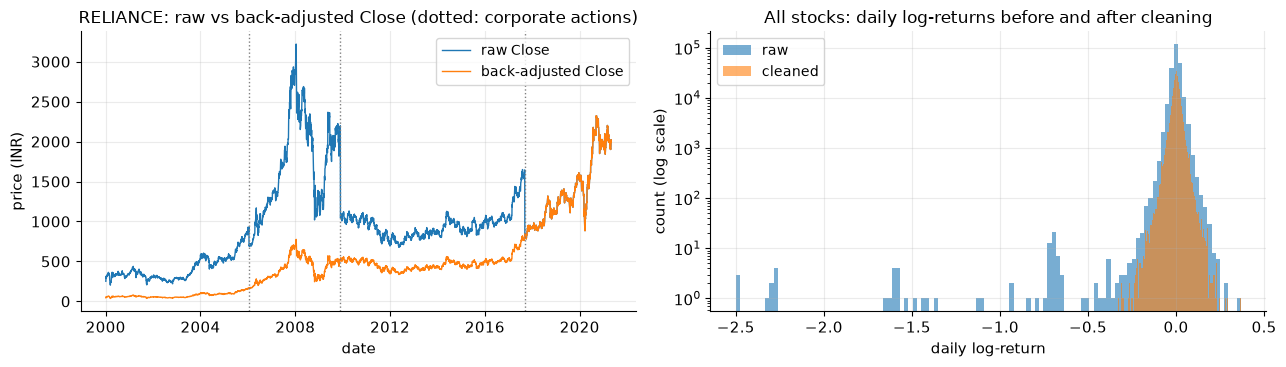

**Observations.** The audit reproduces: 235,192 rows × 15 columns, 49 tickers, 65 raw symbols from 15 renames, no duplicates and no OHLC errors. 94 corporate-action days and 4 hole-spanning returns (2 flagged by both) reduce 235,143 consecutive pairs to **235,047 daily log-returns**. The largest remaining move is +0.369 (INDUSINDBK, 2020-03-26), a genuine market event. One real daily move is lost per flagged event, so the adjustment slightly understates tail events.

In [3]:
RAW_COLS = ["Ticker", "Date", "Open", "High", "Low", "Close", "Volume"]

def clean_panel(raw):
    d = raw[RAW_COLS].sort_values(["Ticker", "Date"]).reset_index(drop=True).copy()
    g = d.groupby("Ticker"); cp = g.Close.shift(1); gap = g.Date.diff().dt.days
    ca = (d.High < 0.80 * cp) | (d.Low > 1.25 * cp) | (d.Open < 0.75 * cp) | (d.Open > 1.333 * cp)
    hole = gap > 20
    d["ca"], d["hole"] = ca, hole
    d["r_raw"] = np.log(d.Close / cp)
    d["r"] = d.r_raw.where(~(ca | hole))
    cum = d.r.fillna(0).groupby(d.Ticker).cumsum()
    d["Adj"] = d.groupby("Ticker").Close.transform("last") * np.exp(cum - cum.groupby(d.Ticker).transform("last"))
    fac = d.Adj / d.Close
    d["AdjOpen"], d["AdjHigh"], d["AdjLow"], d["AdjVolume"] = d.Open * fac, d.High * fac, d.Low * fac, d.Volume / fac
    return d

panel = clean_panel(ps)
panel = panel.merge(meta[["Symbol", "Industry"]].rename(columns={"Symbol": "Ticker"}), on="Ticker", how="left")
assert panel.Industry.notna().all()

_prev = ps.sort_values(["Ticker", "Date"]).groupby("Ticker").Close.shift(1)
_pc = ps.sort_values(["Ticker", "Date"])["Prev Close"]
pc_mismatch = int(((_pc / _prev - 1).abs() > 0.02).sum())
n_ca, n_hole, n_overlap = int(panel.ca.sum()), int(panel.hole.sum()), int((panel.ca & panel.hole).sum())
n_raw_returns = int(panel.r_raw.notna().sum()); n_returns = int(panel.r.notna().sum())
n_zero = int((panel.r == 0).sum())
print(f"Prev Close differs from the previous raw Close by >2% on {pc_mismatch} rows (all on 2001-07-02, after a data hole)")
print(f"Corporate-action days: {n_ca} | data-hole returns: {n_hole} | flagged by both: {n_overlap}")
print(f"Returns: {n_raw_returns} raw consecutive pairs − {n_ca} − {n_hole} + {n_overlap} overlap = {n_returns}")
print(f"Zero-return days: {n_zero} (coded 'not up')")
assert n_ca == 94 and n_hole == 4 and n_returns == 235047
assert n_raw_returns - n_ca - n_hole + n_overlap == n_returns
_chk = panel.groupby("Ticker", group_keys=False).apply(lambda d: np.nanmax(np.abs(np.log(d.Adj / d.Adj.shift(1)) - d.r)), include_groups=False).max()
print(f"Max |ln(Adj_t/Adj_(t-1)) − r_t| on kept days: {_chk:.2e}")
big = panel.loc[panel.r.abs().sort_values(ascending=False).index[:8], ["Ticker", "Date", "r"]]
display(big)

ca_table = panel[panel.ca][["Ticker", "Date", "Close", "r_raw"]].assign(ratio=lambda d: np.exp(d.r_raw))
rel = panel[panel.Ticker == "RELIANCE"].set_index("Date")
rel_ca = list(rel.index[rel.ca])
print("RELIANCE corporate-action dates:", [str(d.date()) for d in rel_ca])
assert str(rel_ca[-1].date()) == "2017-09-07"
_turn = ps.groupby("Ticker").Turnover.median().sort_values(ascending=False)
print("Highest median turnover:", _turn.head(3).round(0).to_dict())
assert _turn.index[0] == "RELIANCE"

R["audit"] = dict(rule=dict(high=0.80, low=1.25, open_lo=0.75, open_hi=1.333, hole_days=20), rows_all=all_df.shape[0], cols_all=all_df.shape[1], n_files=len(files), empty_files=empty, tickers=ps.Ticker.nunique(), date_start=ps.Date.min(), date_end=ps.Date.max(),
    raw_symbols=all_df.Symbol.nunique(), renamed=len(renamed), rename_multi=renamed.to_dict(), missing_trades=miss["Trades"], missing_deliverable=miss["Deliverable Volume"], first_trades=first_trades,
    dup_pairs=dup_pairs, ohlc_bad=ohlc_bad, prev_close_mismatch=pc_mismatch, n_ca=n_ca, n_hole=n_hole, n_overlap=n_overlap, n_raw_returns=n_raw_returns, n_returns=n_returns, n_zero=n_zero,
    industries=meta[meta.Symbol != "INFRATEL"].Industry.nunique(), rel_ca=rel_ca, rel_last_ca=rel_ca[-1], top_turnover=_turn.index[0],
    max_abs_r=panel.r.abs().max(), max_abs_r_row=dict(ticker=big.iloc[0].Ticker, date=big.iloc[0].Date), adj_check=_chk,
    rename_rows=[dict(ticker=r.Ticker, symbol=r.Symbol, first=r["min"], last=r["max"], rows=r["count"]) for _, r in rename_examples.iterrows()])

# before/after adjustment chart on RELIANCE (the first split date lies in the sample)
_w = rel.loc[rel_ca[1] - pd.Timedelta(days=45): rel_ca[1] + pd.Timedelta(days=45)]
chart("adjust_before_after", dict(ticker="RELIANCE", full=dict(), ca_dates=rel_ca, window_event=rel_ca[1],
    window=dict(date=[str(d.date()) for d in _w.index], raw=_w.Close.round(2).tolist(), adj=_w.Adj.round(2).tolist(),
                r_raw=_w.r_raw.round(5).tolist(), r=[None if pd.isna(x) else round(x, 5) for x in _w.r])))
_every = rel.iloc[::5]
CHARTS["adjust_before_after"]["full"] = dict(date=[str(d.date()) for d in _every.index], raw=_every.Close.round(2).tolist(), adj=_every.Adj.round(2).tolist())
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(rel.index, rel.Close, label="raw Close", lw=1); ax[0].plot(rel.index, rel.Adj, label="back-adjusted Close", lw=1)
for d_ in rel_ca: ax[0].axvline(d_, color="grey", ls=":", lw=1)
ax[0].set_ylabel("price (INR)"); ax[0].set_xlabel("date"); ax[0].set_title("RELIANCE: raw vs back-adjusted Close (dotted: corporate actions)"); ax[0].legend()
ax[1].hist(panel.r_raw.dropna().clip(-2.5, .5), bins=120, log=True, alpha=.6, label="raw"); ax[1].hist(panel.r.dropna(), bins=120, log=True, alpha=.6, label="cleaned")
ax[1].set_xlabel("daily log-return"); ax[1].set_ylabel("count (log scale)"); ax[1].set_title("All stocks: daily log-returns before and after cleaning"); ax[1].legend()
plt.tight_layout(); savefig("p0_adjustment"); plt.show()

obs(f"The audit reproduces: {all_df.shape[0]:,} rows × {all_df.shape[1]} columns, {ps.Ticker.nunique()} tickers, {all_df.Symbol.nunique()} raw symbols from {len(renamed)} renames, no duplicates and no OHLC errors. "
    f"{n_ca} corporate-action days and {n_hole} hole-spanning returns ({n_overlap} flagged by both) reduce {n_raw_returns:,} consecutive pairs to **{n_returns:,} daily log-returns**. "
    f"The largest remaining move is {big.iloc[0].r:+.3f} ({big.iloc[0].Ticker}, {big.iloc[0].Date.date()}), a genuine market event. One real daily move is lost per flagged event, so the adjustment slightly understates tail events.")

## Features and the chronological split

**Focus stock:** RELIANCE, the most liquid full-history stock. **21 engineered features** use day t only, and targets use day t+1. A 5-day rolling mean is left out because it equals the average of the five lagged returns, which would make ΦᵀΦ singular.

A random split would be wrong: future days would enter the training set (look-ahead bias) and test days would be surrounded by training days from the same week, while returns are not i.i.d. (volatility clusters). So we train on the past, test on the future, tune with `TimeSeriesSplit(5)` on training rows only, and fit scalers on training rows only.

In [4]:
def build_features(pan, tk):
    d = pan[pan.Ticker == tk].set_index("Date").sort_index()
    mkt_r = pan.groupby("Date").r.mean()
    r = d.r; F = pd.DataFrame(index=d.index)
    for k in range(5): F[f"r_lag{k}"] = r.shift(k)
    for w in (10, 20): F[f"rmean_{w}"] = r.rolling(w, min_periods=int(0.8 * w)).mean()
    for w in (5, 10, 20): F[f"rstd_{w}"] = r.rolling(w, min_periods=int(0.8 * w)).std()
    F["mom_60"] = np.log(d.Adj / d.Adj.shift(60))
    F["dist_sma50"] = np.log(d.Adj / d.Adj.rolling(50).mean())
    F["hl_range"] = np.log(d.AdjHigh / d.AdjLow)
    F["oc_ret"] = np.log(d.Adj / d.AdjOpen)
    F["vol_ratio20"] = d.AdjVolume / d.AdjVolume.rolling(20).mean()
    F["dlog_volume"] = np.log(d.AdjVolume / d.AdjVolume.shift(1))
    F["mkt_r"] = mkt_r.reindex(d.index)
    for i, nm in zip(range(1, 5), ["tue", "wed", "thu", "fri"]):
        F[f"dow_{nm}"] = (d.index.dayofweek == i).astype(float)
    RAW = pd.DataFrame(index=d.index)
    for k in range(5): RAW[f"close_lag{k}"] = d.Adj.shift(k)
    RAW["log_volume"] = np.log(d.AdjVolume)
    T = pd.DataFrame(index=d.index)
    T["close_t"] = d.Adj; T["close_next"] = d.Adj.shift(-1); T["r_next"] = r.shift(-1)
    T["y_dir"] = np.where(T.r_next.isna(), np.nan, (T.r_next > 0).astype(float))
    T["quoted_close_t"] = d.Close
    return F, RAW, T

TEST_START = pd.Timestamp("2018-01-01")
F, RAW, T = build_features(panel, "RELIANCE")
ENG = list(F.columns); RAWC = list(RAW.columns); RAWRET = ["r_lag0", "r_lag1", "r_lag2", "r_lag3", "r_lag4", "dlog_volume"]
D = pd.concat([F, RAW, T], axis=1).dropna(subset=ENG + RAWC + ["close_next", "r_next"])
Dtr, Dte = D[D.index < TEST_START], D[D.index >= TEST_START]
print(f"{len(ENG)} features: {ENG}")
print(f"Train {Dtr.index.min().date()} → {Dtr.index.max().date()} ({len(Dtr)} rows) | Test {Dte.index.min().date()} → {Dte.index.max().date()} ({len(Dte)} rows)")
_rel_rows_test = int((rel.index >= TEST_START).sum())
print(f"RELIANCE has {_rel_rows_test} price days from {TEST_START.date()}; the last has no t+1 target, so there are {len(Dte)} target rows. Feature t = last day of history for target t+1.")
assert len(ENG) == 21 and len(Dtr) == 4405 and len(Dte) == 822
assert str(Dtr.index.min().date()) == "2000-03-30" and str(Dtr.index.max().date()) == "2017-12-29"
assert str(Dte.index.min().date()) == "2018-01-01" and str(Dte.index.max().date()) == "2021-04-29"
assert rel_ca[-1] < TEST_START and (Dte.close_t - Dte.quoted_close_t).abs().max() < 1e-8
from sklearn.model_selection import TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)
_folds = [dict(fold=i + 1, train_end=Dtr.index[a[-1]], val_start=Dtr.index[b[0]], val_end=Dtr.index[b[-1]], n_train=len(a), n_val=len(b)) for i, (a, b) in enumerate(tscv.split(Dtr))]
display(pd.DataFrame(_folds))

21 features: ['r_lag0', 'r_lag1', 'r_lag2', 'r_lag3', 'r_lag4', 'rmean_10', 'rmean_20', 'rstd_5', 'rstd_10', 'rstd_20', 'mom_60', 'dist_sma50', 'hl_range', 'oc_ret', 'vol_ratio20', 'dlog_volume', 'mkt_r', 'dow_tue', 'dow_wed', 'dow_thu', 'dow_fri']
Train 2000-03-30 → 2017-12-29 (4405 rows) | Test 2018-01-01 → 2021-04-29 (822 rows)
RELIANCE has 823 price days from 2018-01-01; the last has no t+1 target, so there are 822 target rows. Feature t = last day of history for target t+1.


,fold,train_end,val_start,val_end,n_train,n_val
0,1,2003-03-06,2003-03-07,2006-02-10,735,734
1,2,2006-02-10,2006-02-13,2009-01-23,1469,734
2,3,2009-01-23,2009-01-27,2012-01-18,2203,734
3,4,2012-01-18,2012-01-19,2015-01-05,2937,734
4,5,2015-01-05,2015-01-06,2017-12-29,3671,734


### Leakage test

For 25 random dates t, the entire pipeline (cleaning, adjustment, market return and features) is rebuilt from raw data truncated at t, and row t is compared with the full-data result. Any feature using t+1 or later would differ. A future split does rescale past adjusted prices, but the engineered features are ratios of prices, so they must match to machine precision.

In [5]:
_rng = np.random.default_rng(SEED)
_dates = sorted(_rng.choice(D.index.values, 25, replace=False))
_rows = []
for t in _dates:
    Ft, RAWt, _ = build_features(clean_panel(ps[ps.Date <= t]), "RELIANCE")
    _rows.append(dict(date=pd.Timestamp(t), max_abs_diff=float(np.nanmax(np.abs(Ft.loc[t].values - F.loc[t].values)))))
leak = pd.DataFrame(_rows); display(leak.head(6))
leak_max = leak.max_abs_diff.max()
print(f"Max |feature difference| over {len(leak)} truncation dates: {leak_max:.2e}")
assert leak_max < 1e-12
assert not set(T.columns) & set(ENG + RAWC)
R["split"] = dict(focus="RELIANCE", train_start=Dtr.index.min(), train_end=Dtr.index.max(), test_start=Dte.index.min(), test_end=Dte.index.max(), n_train=len(Dtr), n_test=len(Dte), n_features=len(ENG), features=ENG,
    n_rel_price_days_test=_rel_rows_test, leak_n=len(leak), leak_max=leak_max, folds=_folds, n_rel_rows=len(rel))
chart("leakage", dict(rows=[dict(date=str(a.date), max_abs_diff=float(f"{a.max_abs_diff:.3g}")) for a in leak.itertuples()]))
save_results()
obs(f"Train has {len(Dtr)} rows and test has {len(Dte)}. Across {len(leak)} truncation dates the largest feature difference is {leak_max:.1e}, so no feature looks ahead. "
    f"RELIANCE has {_rel_rows_test} price days in the test period but {len(Dte)} target rows, because the last day has no next-day target. The test period starts after its last corporate action ({rel_ca[-1].date()}), so every test price is an actual quoted Close.")

,date,max_abs_diff
0,2002-01-14,1.942890e-16
1,2002-02-06,6.661338e-16
2,2002-03-14,2.185752e-16
3,2002-12-02,2.220446e-16
4,2004-01-15,2.220446e-16
5,2004-06-04,2.220446e-16


Max |feature difference| over 25 truncation dates: 6.66e-16


**Observations.** Train has 4405 rows and test has 822. Across 25 truncation dates the largest feature difference is 6.7e-16, so no feature looks ahead. RELIANCE has 823 price days in the test period but 822 target rows, because the last day has no next-day target. The test period starts after its last corporate action (2017-09-07), so every test price is an actual quoted Close.

In [6]:
def ds_idx(y, n=1500):
    """Indices for display downsampling: the min and max of each bucket are kept, so crash extremes survive."""
    y = np.asarray(y, float); N = len(y)
    if N <= n: return np.arange(N)
    idx = {0, N - 1}
    for b in np.array_split(np.arange(N), n // 2):
        v = y[b]
        if np.all(np.isnan(v)): continue
        idx.add(int(b[np.nanargmin(v)])); idx.add(int(b[np.nanargmax(v)]))
    return np.array(sorted(idx))

def rnd(a, k=4):
    return [None if (x is None or (isinstance(x, float) and not math.isfinite(x))) else round(float(x), k) for x in a]

def dstr(ix):
    return [str(pd.Timestamp(d).date()) for d in ix]

# UNIT 1
**Assigned title:** Distribution analysis of daily log-returns of NIFTY-50 stocks; quantiles (Value-at-Risk), volatility & covariance

**Syllabus mapping:** ML – what & why; supervised vs unsupervised view of the data; polynomial curve fitting (price trend); discrete RVs, fundamental rules & Bayes rule (P(up-day | previous up-day)); independence & conditional independence; continuous RVs – quantiles, mean, variance; probability densities, expectation & covariance.

## ML: what and why, and two views of this dataset

Machine learning means estimating a mapping or a structure from data rather than coding rules by hand. A probabilistic treatment also says how uncertain that estimate is. On this dataset:

- **Supervised view:** each day t has inputs (past returns, volatility, volume) and a label known one day later. Next-day Close is regression, and next-day up/down is classification (Units 2 and 5).
- **Unsupervised view:** there is no label, so we look for structure, such as groups of stocks that behave alike, common market factors (Unit 3) or hidden market regimes (Unit 4).

Unit 1 describes the data with probability first, since those properties decide which models are reasonable. Log-returns `r_t = ln(Adj_t / Adj_{t−1})` are used instead of prices because they are scale-free, roughly stationary and additive over time.

## Unit 1, Practice 2: summary & statistics

,Pooled,RELIANCE
n,235047.000000,5302.000000
mean,0.000614,0.000714
variance,0.000599,0.000466
std,0.024478,0.021598
min,-0.327266,-0.177610
q25,-0.011182,-0.010658
median,0.000196,0.000565
q75,0.012130,0.011828
max,0.369306,0.193667
skew,0.003120,-0.063297


,industry,first,last,n,mean,std,ann_vol,ann_mean,skew,ex_kurt,jb_p,t_df,var99,up_rate,tail4_ratio
ticker,,,,,,,,,,,,,,,
ADANIPORTS,SERVICES,2007-11-28,2021-04-30,3320,0.00040,0.02692,0.42739,0.10197,0.02530,5.64588,0.0,3.57374,0.07304,0.49518,80.83804
ASIANPAINT,CONSUMER GOODS,2000-01-04,2021-04-30,5302,0.00097,0.01712,0.27184,0.24365,0.01885,5.32488,0.0,3.39161,0.04409,0.50811,86.35017
AXISBANK,FINANCIAL SERVICES,2000-01-04,2021-04-30,5304,0.00092,0.02842,0.45114,0.23287,-0.05523,7.61173,0.0,3.21423,0.07648,0.49604,65.48232
BAJAJ-AUTO,AUTOMOBILE,2008-05-27,2021-04-30,3200,0.00080,0.01938,0.30769,0.20098,-0.22720,6.83379,0.0,3.42186,0.05086,0.50562,93.73646
BAJAJFINSV,FINANCIAL SERVICES,2008-05-27,2021-04-30,3200,0.00096,0.02536,0.40256,0.24230,-0.59455,11.95928,0.0,2.97824,0.06677,0.50156,78.93596
BAJFINANCE,FINANCIAL SERVICES,2000-01-04,2021-04-30,5233,0.00133,0.02781,0.44146,0.33512,0.27868,8.00921,0.0,2.66398,0.07428,0.50430,102.57301
BHARTIARTL,TELECOM,2002-02-19,2021-04-30,4772,0.00066,0.02401,0.38113,0.16713,0.41901,4.42616,0.0,4.03330,0.06234,0.49246,56.24105
BPCL,ENERGY,2000-01-04,2021-04-30,5301,0.00048,0.02654,0.42123,0.12220,-0.13559,5.22638,0.0,3.74177,0.07324,0.49859,83.38830
BRITANNIA,CONSUMER GOODS,2000-01-04,2021-04-30,5302,0.00069,0.01691,0.26850,0.17461,0.40436,5.72924,0.0,3.20483,0.04247,0.49302,77.41739


Per-stock: annualised volatility from 0.241 (NESTLEIND) to 0.516 (VEDL)
Stocks that reject normality at 5% by Jarque–Bera: 49 of 49. Excess kurtosis min 3.21, median 5.71, max 12.69.
Student-t ν: pooled 3.059, RELIANCE 3.754; log-lik Normal 12811.2 vs t 13283.7 (RELIANCE)
4σ days RELIANCE: 29 seen vs 0.336 expected (86.4× Gaussian); pooled: 1299 vs 14.9 (87.2×)


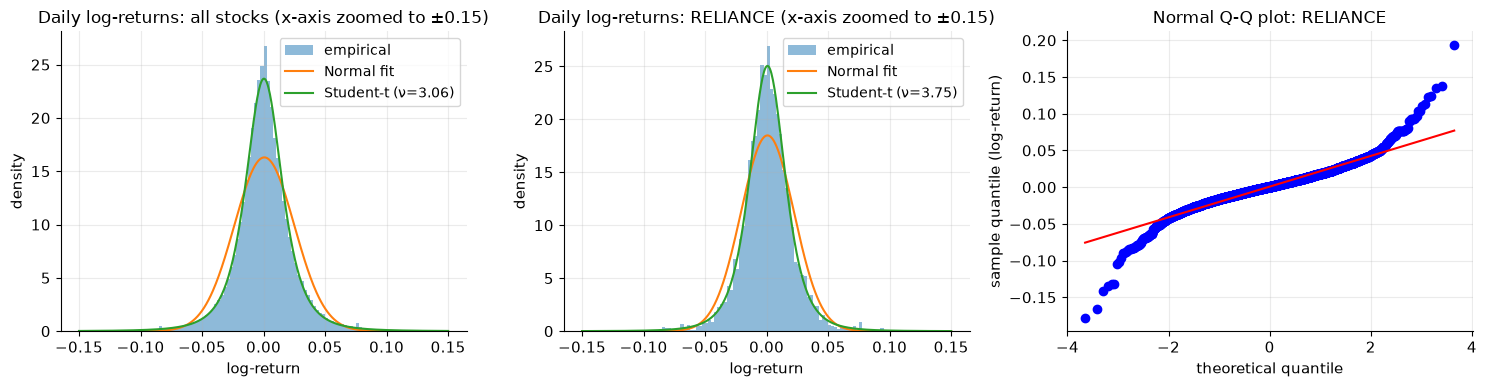

**Observations.** Mean daily log-returns are close to zero (0.00061 pooled, 0.00071 RELIANCE), but the tails are heavy: excess kurtosis is 7.40 pooled and 6.81 for RELIANCE, against 0 for a Gaussian. Jarque–Bera rejects normality for 49 of 49 stocks. A Student-t fit has ν = 3.75 for RELIANCE and a higher log-likelihood (13283.7 vs 12811.2). Moves beyond 4σ occur 86 times more often on RELIANCE than a Gaussian predicts (29 days seen, 0.34 expected).

In [7]:
ret = panel[["Ticker", "Industry", "Date", "Adj", "r"]].copy()
r_all = ret.r.dropna().values
r_rel = ret.loc[ret.Ticker == "RELIANCE", "r"].dropna().values

def describe(x):
    x = np.asarray(x); jb = stats.jarque_bera(x)
    m, s = x.mean(), x.std(ddof=1)
    return dict(n=len(x), mean=m, variance=x.var(ddof=1), std=s, min=x.min(), q25=np.quantile(x, .25), median=np.median(x), q75=np.quantile(x, .75), max=x.max(),
                skew=stats.skew(x), ex_kurt=stats.kurtosis(x), jb=jb.statistic, jb_p=jb.pvalue, ann_vol=s * np.sqrt(252), ann_mean=m * 252)

desc = pd.DataFrame({"Pooled": describe(r_all), "RELIANCE": describe(r_rel)})
display(desc)

def tail4(x):
    m, s = x.mean(), x.std(ddof=1)
    emp = np.mean(np.abs(x - m) > 4 * s); gau = 2 * stats.norm.sf(4)
    return dict(k=int((np.abs(x - m) > 4 * s).sum()), emp=emp, gauss=gau, ratio=emp / gau, expected=gau * len(x))

def fit_dists(x):
    tdf, tloc, tscale = stats.t.fit(x)
    m, s0 = x.mean(), x.std(ddof=0)
    lln = stats.norm.logpdf(x, m, s0).sum(); llt = stats.t.logpdf(x, tdf, tloc, tscale).sum()
    return dict(t_df=tdf, t_loc=tloc, t_scale=tscale, ll_norm=lln, ll_t=llt, aic_norm=2 * 2 - 2 * lln, aic_t=2 * 3 - 2 * llt)

def var_es(x):
    m, s = x.mean(), x.std(ddof=1); out = {}
    for a in (95, 99):
        q = np.quantile(x, 1 - a / 100)
        out[f"hist_var{a}"] = -q
        out[f"gauss_var{a}"] = -(m + stats.norm.ppf(1 - a / 100) * s)
        out[f"es{a}"] = -x[x <= q].mean()
        out[f"gauss_es{a}"] = -(m - s * stats.norm.pdf(stats.norm.ppf(1 - a / 100)) / (1 - a / 100))
    for p in (1, 5, 25, 50, 75, 95, 99):
        out[f"q{p}"] = np.quantile(x, p / 100)
    return out

per_stock_rows = []
_edges = np.linspace(-0.2, 0.2, 81)
_qq_p = np.r_[np.array([0.0002, 0.0005, 0.001, 0.002, 0.005]), np.linspace(0.01, 0.99, 99), 1 - np.array([0.005, 0.002, 0.001, 0.0005, 0.0002])]
dist_chart = {}
def dist_block(name, x):
    d = describe(x); f = fit_dists(x); v = var_es(x); t4 = tail4(x)
    h, _ = np.histogram(x, bins=_edges, density=False)
    width = _edges[1] - _edges[0]
    grid = np.linspace(-0.2, 0.2, 161)
    outside = int(((x < _edges[0]) | (x > _edges[-1])).sum())
    q_emp = np.quantile(x, _qq_p); z = stats.norm.ppf(_qq_p)
    dist_chart[name] = dict(stats=d, fit=f, var=v, tail4=t4, bin_centers=rnd((_edges[:-1] + _edges[1:]) / 2, 4), density=rnd(h / (len(x) * width), 3), outside=outside,
        grid=rnd(grid, 4), pdf_norm=rnd(stats.norm.pdf(grid, d["mean"], d["std"]), 3), pdf_t=rnd(stats.t.pdf(grid, f["t_df"], f["t_loc"], f["t_scale"]), 3),
        qq_z=rnd(z, 3), qq_r=rnd(q_emp, 5), qq_line=rnd(d["mean"] + d["std"] * z, 5))
    return d, f, v, t4

for tk, grp in ret.dropna(subset=["r"]).groupby("Ticker"):
    d, f, v, t4 = dist_block(tk, grp.r.values)
    per_stock_rows.append(dict(ticker=tk, industry=grp.Industry.iloc[0], first=grp.Date.min(), last=grp.Date.max(), n=d["n"], mean=d["mean"], std=d["std"], ann_vol=d["ann_vol"], ann_mean=d["ann_mean"],
                               skew=d["skew"], ex_kurt=d["ex_kurt"], jb_p=d["jb_p"], t_df=f["t_df"], var99=v["hist_var99"], up_rate=np.mean(grp.r.values > 0), tail4_ratio=t4["ratio"]))
pooled_d, pooled_f, pooled_v, pooled_t4 = dist_block("Pooled (all stocks)", r_all)
rel_d, rel_f, rel_v, rel_t4 = (dist_chart["RELIANCE"][k] for k in ("stats", "fit", "var", "tail4"))
stock_tab = pd.DataFrame(per_stock_rows).set_index("ticker")
assert stock_tab.n.sum() == n_returns
display(stock_tab.round(5).head(10))
print(f"Per-stock: annualised volatility from {stock_tab.ann_vol.min():.3f} ({stock_tab.ann_vol.idxmin()}) to {stock_tab.ann_vol.max():.3f} ({stock_tab.ann_vol.idxmax()})")
print(f"Stocks that reject normality at 5% by Jarque–Bera: {(stock_tab.jb_p < .05).sum()} of {len(stock_tab)}. Excess kurtosis min {stock_tab.ex_kurt.min():.2f}, median {stock_tab.ex_kurt.median():.2f}, max {stock_tab.ex_kurt.max():.2f}.")
print(f"Student-t ν: pooled {pooled_f['t_df']:.3f}, RELIANCE {rel_f['t_df']:.3f}; log-lik Normal {rel_f['ll_norm']:.1f} vs t {rel_f['ll_t']:.1f} (RELIANCE)")
print(f"4σ days RELIANCE: {rel_t4['k']} seen vs {rel_t4['expected']:.3f} expected ({rel_t4['ratio']:.1f}× Gaussian); pooled: {pooled_t4['k']} vs {pooled_t4['expected']:.1f} ({pooled_t4['ratio']:.1f}×)")

R["u1_dist"] = dict(pooled={**pooled_d, **pooled_f, **pooled_v, "tail4": pooled_t4}, reliance={**rel_d, **rel_f, **rel_v, "tail4": rel_t4},
    stocks_jb_reject=int((stock_tab.jb_p < .05).sum()), n_stocks=len(stock_tab), kurt_min=stock_tab.ex_kurt.min(), kurt_median=stock_tab.ex_kurt.median(), kurt_max=stock_tab.ex_kurt.max(),
    vol_min=stock_tab.ann_vol.min(), vol_min_t=stock_tab.ann_vol.idxmin(), vol_max=stock_tab.ann_vol.max(), vol_max_t=stock_tab.ann_vol.idxmax(), n_t_better_aic=int(sum(dist_chart[t]["fit"]["aic_t"] < dist_chart[t]["fit"]["aic_norm"] for t in stock_tab.index)))
chart("u1_distributions", dict(names=["Pooled (all stocks)"] + sorted(stock_tab.index), stocks=dist_chart))
chart("u1_stock_table", dict(rows=[dict(ticker=i, **{k: (str(v.date()) if hasattr(v, "date") else v) for k, v in r.items()}) for i, r in stock_tab.iterrows()]))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
grid = np.linspace(-.15, .15, 500)
for a, x, name, f in [(ax[0], r_all, "all stocks", pooled_f), (ax[1], r_rel, "RELIANCE", rel_f)]:
    a.hist(x, bins=np.linspace(-.15, .15, 121), density=True, alpha=.5, label="empirical")
    a.plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), label="Normal fit"); a.plot(grid, stats.t.pdf(grid, f["t_df"], f["t_loc"], f["t_scale"]), label=f"Student-t (ν={f['t_df']:.2f})")
    a.set_title(f"Daily log-returns: {name} (x-axis zoomed to ±0.15)"); a.set_xlabel("log-return"); a.set_ylabel("density"); a.legend()
stats.probplot(r_rel, dist="norm", plot=ax[2]); ax[2].set_title("Normal Q-Q plot: RELIANCE"); ax[2].set_xlabel("theoretical quantile"); ax[2].set_ylabel("sample quantile (log-return)")
plt.tight_layout(); savefig("u1_distributions"); plt.show()
obs(f"Mean daily log-returns are close to zero ({pooled_d['mean']:.5f} pooled, {rel_d['mean']:.5f} RELIANCE), but the tails are heavy: excess kurtosis is {pooled_d['ex_kurt']:.2f} pooled and {rel_d['ex_kurt']:.2f} for RELIANCE, against 0 for a Gaussian. "
    f"Jarque–Bera rejects normality for {(stock_tab.jb_p < .05).sum()} of {len(stock_tab)} stocks. A Student-t fit has ν = {rel_f['t_df']:.2f} for RELIANCE and a higher log-likelihood ({rel_f['ll_t']:.1f} vs {rel_f['ll_norm']:.1f}). "
    f"Moves beyond 4σ occur {rel_t4['ratio']:.0f} times more often on RELIANCE than a Gaussian predicts ({rel_t4['k']} days seen, {rel_t4['expected']:.2f} expected).")

## Quantiles: Value-at-Risk and Expected Shortfall

VaR at level a is the loss that is exceeded on a fraction 1−a of days, reported as a positive log-return. **Historical** VaR is the empirical quantile, and **Gaussian** VaR is −(μ + zσ). Expected Shortfall (ES) is the mean loss beyond VaR.

**Back-test.** VaR is estimated on RELIANCE's training returns only, then exceedances are counted in the test period. Under a correct model the count is Binomial(n, 1−a), and Kupiec's proportion-of-failures test compares the observed rate to 1−a with a likelihood ratio ~ χ²(1).

**Day count.** The back-test uses return days on or after 2018-01-01, one more than the 822 target rows of Units 2 and 5, because a return exists for the last day but a next-day target does not.

In [8]:
def kupiec(k, n, p):
    phat = k / n
    ll0 = (n - k) * np.log(1 - p) + k * np.log(p)
    ll1 = ((n - k) * np.log(1 - phat) if k < n else 0) + (k * np.log(phat) if k > 0 else 0)
    lr = -2 * (ll0 - ll1)
    return lr, stats.chi2.sf(lr, 1)

_rr = ret[(ret.Ticker == "RELIANCE") & ret.r.notna()]
rtr, rte = _rr.loc[_rr.Date < TEST_START, "r"].values, _rr.loc[_rr.Date >= TEST_START, "r"].values
print(f"Train returns: {len(rtr)} | test returns: {len(rte)}")
bt_rows = []
for a in (95, 99):
    p = 1 - a / 100
    for meth, v in [("Historical", -np.quantile(rtr, p)), ("Gaussian", -(rtr.mean() + stats.norm.ppf(p) * rtr.std(ddof=1)))]:
        k = int((rte < -v).sum()); lr, pv = kupiec(k, len(rte), p)
        bt_rows.append(dict(level=a, method=meth, var_train=v, n_test=len(rte), exceedances=k, expected=len(rte) * p, rate=k / len(rte), kupiec_lr=lr, kupiec_p=pv, binom_p=stats.binomtest(k, len(rte), p).pvalue))
bt = pd.DataFrame(bt_rows); display(bt.round(5))
_rd = _rr.loc[_rr.Date >= TEST_START, ["Date", "r"]]
_v99 = bt_rows[2]["var_train"]; _ex = _rd[_rd.r < -_v99]
_ex_mar = int(((_ex.Date >= "2020-03-01") & (_ex.Date <= "2020-03-31")).sum())
print("Historical 99% exceedance dates:", [str(d.date()) for d in _ex.Date], f"| in March 2020: {_ex_mar} of {len(_ex)}")
var_tab = pd.DataFrame({"Pooled": pooled_v, "RELIANCE": rel_v}); display(var_tab.round(5))
R["u1_var"] = dict(backtest=bt_rows, n_train_returns=len(rtr), n_test_returns=len(rte), exceed99_dates=list(_ex.Date), exceed99_march2020=_ex_mar, any_rejected_5=bool((bt.kupiec_p < .05).any()), rejected=[f"{r['method']} {r['level']}" for r in bt_rows if r["kupiec_p"] < .05])
obs(f"At 99%, Gaussian VaR ({rel_v['gauss_var99']:.4f}) understates the historical figure ({rel_v['hist_var99']:.4f}) on RELIANCE, because of the fat tails. At 95% the order flips ({rel_v['gauss_var95']:.4f} vs {rel_v['hist_var95']:.4f}), because a t-like distribution puts more mass in the centre and far tails and less in the shoulders. "
    f"ES 99% is {rel_v['es99']:.4f}. In the back-test on {len(rte)} test days, historical 99% VaR has {bt_rows[2]['exceedances']} exceedances vs {bt_rows[2]['expected']:.2f} expected (Kupiec p = {bt_rows[2]['kupiec_p']:.3f}), and Gaussian 99% has {bt_rows[3]['exceedances']} (p = {bt_rows[3]['kupiec_p']:.3f}). "
    f"At 95%, the test period had fewer exceedances than expected: historical {bt_rows[0]['exceedances']} (p = {bt_rows[0]['kupiec_p']:.3f}), Gaussian {bt_rows[1]['exceedances']} (p = {bt_rows[1]['kupiec_p']:.3f}). The Kupiec test only checks the overall rate, not whether exceedances cluster, and here {_ex_mar} of the {len(_ex)} historical 99% exceedances fall in March 2020.")

Train returns: 4479 | test returns: 823


,level,method,var_train,n_test,exceedances,expected,rate,kupiec_lr,kupiec_p,binom_p
0,95,Historical,0.03169,823,32,41.15,0.03888,2.31143,0.12843,0.15028
1,95,Gaussian,0.03487,823,26,41.15,0.03159,6.71706,0.00955,0.01296
2,99,Historical,0.06317,823,8,8.23,0.00972,0.00655,0.93548,1.00000
3,99,Gaussian,0.04960,823,10,8.23,0.01215,0.35983,0.54860,0.48150


Historical 99% exceedance dates: ['2018-10-04', '2018-10-05', '2020-03-09', '2020-03-12', '2020-03-16', '2020-03-23', '2020-05-12', '2020-11-02'] | in March 2020: 4 of 8


,Pooled,RELIANCE
hist_var95,0.03576,0.03120
gauss_var95,0.03965,0.03481
es95,0.05600,0.04891
gauss_es95,0.04988,0.04384
hist_var99,0.06787,0.06311
gauss_var99,0.05633,0.04953
es99,0.09357,0.08369
gauss_es99,0.06462,0.05685
q1,-0.06787,-0.06311
q5,-0.03576,-0.03120


**Observations.** At 99%, Gaussian VaR (0.0495) understates the historical figure (0.0631) on RELIANCE, because of the fat tails. At 95% the order flips (0.0348 vs 0.0312), because a t-like distribution puts more mass in the centre and far tails and less in the shoulders. ES 99% is 0.0837. In the back-test on 823 test days, historical 99% VaR has 8 exceedances vs 8.23 expected (Kupiec p = 0.935), and Gaussian 99% has 10 (p = 0.549). At 95%, the test period had fewer exceedances than expected: historical 32 (p = 0.128), Gaussian 26 (p = 0.010). The Kupiec test only checks the overall rate, not whether exceedances cluster, and here 4 of the 8 historical 99% exceedances fall in March 2020.

## Discrete random variables and Bayes rule: P(up | previous up)

`U_t = 1[r_t > 0]`, so a zero return counts as "not up". Pairs (U_{t−1}, U_t) are formed within each stock on consecutive valid returns.

- Sum rule: P(U_t=1) = Σ_u P(U_t=1, U_{t−1}=u)
- Product rule: P(U_t=1, U_{t−1}=1) = P(U_t=1 | U_{t−1}=1)·P(U_{t−1}=1)
- Bayes rule: P(U_t=1 | U_{t−1}=1) = P(U_{t−1}=1 | U_t=1)·P(U_t=1) / P(U_{t−1}=1)

The counts are printed, so the arithmetic can be reproduced by hand.

Counts (prev,today): n00=58039  n01=58530  n10=58539  n11=59794  N=234902
P(U_t=1)                   = (n01+n11)/N       = 118324/234902 = 0.50371644
P(U_t-1=1)                 = (n10+n11)/N       = 118333/234902 = 0.50375476
P(U_t-1=1 | U_t=1)         = n11/(n01+n11)     = 59794/118324 = 0.50534127
Bayes rule:  0.50534127 × 0.50371644 / 0.50375476 = 0.50530283
Direct count: n11/(n10+n11) = 59794/118333 = 0.50530283
P(up | prev down) = 58530/116569 = 0.50210605
Test against 0.5: binomial p = 0.000267 (looks significant). Test vs P(up) = 0.50372: p = 0.2756
χ² independence: χ² = 2.4006, p = 0.1213, Cramér's V = 0.00320, marginal odds ratio = 1.01287


,n,p_up,p_up_up,p_up_dn,chi2,p,V,diff,sig5,sig_bonf
Ticker,,,,,,,,,,
BAJAJFINSV,3199.0,0.50141,0.53209,0.47051,12.12803,0.00050,0.06157,0.06157,True,True
ICICIBANK,5302.0,0.49887,0.51815,0.47968,7.84677,0.00509,0.03847,0.03847,True,False
NTPC,4086.0,0.49046,0.46906,0.51105,7.20262,0.00728,0.04199,-0.04199,True,False
BHARTIARTL,4770.0,0.49245,0.47319,0.51116,6.87548,0.00874,0.03797,-0.03797,True,False
LT,4174.0,0.50096,0.52008,0.48175,6.13179,0.01328,0.03833,0.03833,True,False
EICHERMOT,5297.0,0.49368,0.50956,0.47818,5.21496,0.02239,0.03138,0.03138,True,False
SHREECEM,4981.0,0.50873,0.52388,0.49306,4.73419,0.02957,0.03083,0.03083,True,False
HINDUNILVR,5302.0,0.49698,0.48216,0.51162,4.60241,0.03193,0.02946,-0.02946,True,False
VEDL,5299.0,0.49217,0.50710,0.47771,4.57537,0.03243,0.02938,0.02938,True,False


Stocks significant at 5%: 10 of 49 (chance alone would give about 2.45); after Bonferroni (α = 0.001020): 1 → ['BAJAJFINSV']
Stocks with positive diff: 28 of 49. RELIANCE: {'p_up': 0.51623, 'p_up_up': 0.51609, 'p_up_dn': 0.51638, 'p': 0.98333, 'V': 0.00029}


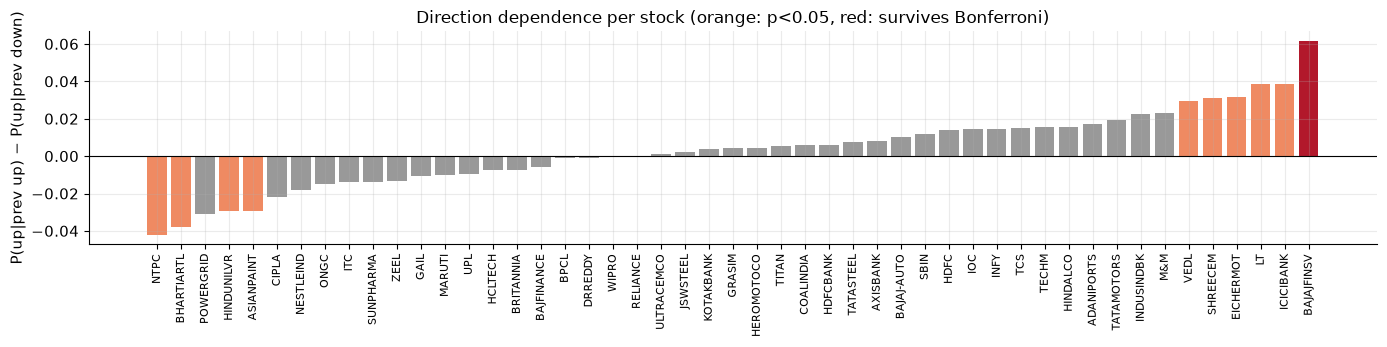

**Observations.** Bayes rule and the direct count agree: 0.50534127 × 0.50371644 / 0.50375476 = 0.50530283. The test against 0.5 looks significant (p = 0.000267), but this is misleading because P(up) = 0.50372 is already above 0.5. The right question is whether U_t and U_(t−1) are independent, and the χ² test does not reject that (p = 0.121, Cramér's V = 0.0032). Per stock, 10 of 49 are significant at 5% and 1 after Bonferroni (BAJAJFINSV). So there is no general day-to-day momentum in direction.

In [9]:
ret["up"] = np.where(ret.r.isna(), np.nan, (ret.r > 0).astype(float))
ret["up_prev"] = ret.groupby("Ticker").up.shift(1)
ret["r_prev"] = ret.groupby("Ticker").r.shift(1)
pairs = ret.dropna(subset=["up", "up_prev"]).copy()
n00, n01 = int(((pairs.up_prev == 0) & (pairs.up == 0)).sum()), int(((pairs.up_prev == 0) & (pairs.up == 1)).sum())
n10, n11 = int(((pairs.up_prev == 1) & (pairs.up == 0)).sum()), int(((pairs.up_prev == 1) & (pairs.up == 1)).sum())
N = n00 + n01 + n10 + n11
P_up, P_prev = (n01 + n11) / N, (n10 + n11) / N
P_prev_given_up = n11 / (n01 + n11)
bayes = P_prev_given_up * P_up / P_prev
direct = n11 / (n10 + n11); direct_dn = n01 / (n00 + n01)
print(f"Counts (prev,today): n00={n00}  n01={n01}  n10={n10}  n11={n11}  N={N}")
print(f"P(U_t=1)                   = (n01+n11)/N       = {n01+n11}/{N} = {P_up:.8f}")
print(f"P(U_t-1=1)                 = (n10+n11)/N       = {n10+n11}/{N} = {P_prev:.8f}")
print(f"P(U_t-1=1 | U_t=1)         = n11/(n01+n11)     = {n11}/{n01+n11} = {P_prev_given_up:.8f}")
print(f"Bayes rule:  {P_prev_given_up:.8f} × {P_up:.8f} / {P_prev:.8f} = {round(P_prev_given_up,8)*round(P_up,8)/round(P_prev,8):.8f}")
print(f"Direct count: n11/(n10+n11) = {n11}/{n10+n11} = {direct:.8f}")
print(f"P(up | prev down) = {n01}/{n00+n01} = {direct_dn:.8f}")
assert abs(round(P_prev_given_up, 8) * round(P_up, 8) / round(P_prev, 8) - direct) < 2e-8 and abs(bayes - direct) < 1e-14
bt05 = stats.binomtest(n11, n10 + n11, 0.5)
bt_pup = stats.binomtest(n11, n10 + n11, P_up)
tab_pool = np.array([[n00, n01], [n10, n11]])
chi2_p, pv_p, _, exp_p = stats.chi2_contingency(tab_pool, correction=False)
V_p = np.sqrt(chi2_p / N)
OR_marg = n11 * n00 / (n10 * n01)
print(f"Test against 0.5: binomial p = {bt05.pvalue:.6f} (looks significant). Test vs P(up) = {P_up:.5f}: p = {bt_pup.pvalue:.4f}")
print(f"χ² independence: χ² = {chi2_p:.4f}, p = {pv_p:.4f}, Cramér's V = {V_p:.5f}, marginal odds ratio = {OR_marg:.5f}")

def stock_bayes(d):
    a = np.array([[((d.up_prev == 0) & (d.up == 0)).sum(), ((d.up_prev == 0) & (d.up == 1)).sum()], [((d.up_prev == 1) & (d.up == 0)).sum(), ((d.up_prev == 1) & (d.up == 1)).sum()]])
    c, p, _, _ = stats.chi2_contingency(a, correction=False)
    return pd.Series(dict(n=a.sum(), p_up=(a[0, 1] + a[1, 1]) / a.sum(), p_up_up=a[1, 1] / a[1].sum(), p_up_dn=a[0, 1] / a[0].sum(), chi2=c, p=p, V=np.sqrt(c / a.sum())))
pb = pairs.groupby("Ticker")[["up", "up_prev"]].apply(stock_bayes); pb["diff"] = pb.p_up_up - pb.p_up_dn
m = len(pb); bonf = 0.05 / m
pb["sig5"] = pb.p < .05; pb["sig_bonf"] = pb.p < bonf
display(pb.sort_values("p").round(5).head(12))
print(f"Stocks significant at 5%: {pb.sig5.sum()} of {m} (chance alone would give about {0.05*m:.2f}); after Bonferroni (α = {bonf:.6f}): {pb.sig_bonf.sum()} → {list(pb.index[pb.sig_bonf])}")
print(f"Stocks with positive diff: {(pb['diff']>0).sum()} of {m}. RELIANCE: {pb.loc['RELIANCE'][['p_up','p_up_up','p_up_dn','p','V']].astype(float).round(5).to_dict()}")
R["u1_bayes"] = dict(n00=n00, n01=n01, n10=n10, n11=n11, N=N, P_up=P_up, P_prev=P_prev, P_prev_given_up=P_prev_given_up, bayes=bayes, direct=direct, direct_dn=direct_dn, p_vs_half=bt05.pvalue, p_vs_pup=bt_pup.pvalue,
    chi2=chi2_p, chi2_p=pv_p, V=V_p, or_marginal=OR_marg, exp=exp_p, n_stocks=m, n_sig5=pb.sig5.sum(), n_bonf=pb.sig_bonf.sum(), bonf_stocks=list(pb.index[pb.sig_bonf]), bonf_alpha=bonf, chance_sig=0.05 * m, n_pos_diff=(pb["diff"] > 0).sum(), reliance=pb.loc["RELIANCE"][["n", "p_up", "p_up_up", "p_up_dn", "chi2", "p", "V"]].astype(float).to_dict(), v_max=pb.V.max(), v_max_t=pb.V.idxmax())
chart("u1_per_stock_bayes", dict(rows=[dict(ticker=i, n=r.n, p_up=round(r.p_up, 5), p_up_up=round(r.p_up_up, 5), p_up_dn=round(r.p_up_dn, 5), diff=round(r["diff"], 5), chi2=round(r.chi2, 4), p=float(f"{r.p:.4g}"), V=round(r.V, 5), sig5=bool(r.sig5), sig_bonf=bool(r.sig_bonf)) for i, r in pb.sort_values("diff").iterrows()]))
fig, ax = plt.subplots(figsize=(14, 3.6)); o = pb.sort_values("diff")
ax.bar(o.index, o["diff"], color=np.where(o.sig_bonf, "#b2182b", np.where(o.sig5, "#ef8a62", "#999999"))); ax.axhline(0, color="k", lw=.8); plt.xticks(rotation=90, fontsize=8)
ax.set_ylabel("P(up|prev up) − P(up|prev down)"); ax.set_title("Direction dependence per stock (orange: p<0.05, red: survives Bonferroni)"); plt.tight_layout(); savefig("u1_bayes_per_stock"); plt.show()
obs(f"Bayes rule and the direct count agree: {P_prev_given_up:.8f} × {P_up:.8f} / {P_prev:.8f} = {direct:.8f}. The test against 0.5 looks significant (p = {bt05.pvalue:.6f}), but this is misleading because P(up) = {P_up:.5f} is already above 0.5. "
    f"The right question is whether U_t and U_(t−1) are independent, and the χ² test does not reject that (p = {pv_p:.3f}, Cramér's V = {V_p:.4f}). Per stock, {pb.sig5.sum()} of {m} are significant at 5% and {pb.sig_bonf.sum()} after Bonferroni ({', '.join(pb.index[pb.sig_bonf])}). So there is no general day-to-day momentum in direction.")

## Independence and conditional independence

U_t ⫫ U_{t−1} | Z means the joint factorises within every level of Z. We condition on three variables known at t−1: **industry**, **volatility regime** (the stock's 20-day rolling std up to t−1, split at that stock's median) and **yesterday's market direction** (sign of the cross-sectional median return on t−1).

- **Cochran–Mantel–Haenszel (CMH)** tests whether a common odds ratio equals 1 across strata.
- **Breslow–Day** tests whether the odds ratios are equal across strata.

In [10]:
from statsmodels.stats.contingency_tables import StratifiedTable
ret["vol20_prev"] = ret.groupby("Ticker").r.transform(lambda s: s.shift(1).rolling(20, min_periods=15).std())
ret["vol_regime"] = np.where(ret.vol20_prev > ret.groupby("Ticker").vol20_prev.transform("median"), "high vol", "low vol")
ret.loc[ret.vol20_prev.isna(), "vol_regime"] = None
_mkt = ret.groupby("Date").r.median().shift(1).rename("mkt_prev")
ret = ret.merge(_mkt, left_on="Date", right_index=True, how="left")
ret["mkt_dir"] = np.where(ret.mkt_prev > 0, "market up yesterday", "market not up yesterday")
ret.loc[ret.mkt_prev.isna(), "mkt_dir"] = None
pairs = ret.dropna(subset=["up", "up_prev"]).copy()

ci_rows, cmh_rows = [], []
for Z, label in [("Industry", "Industry"), ("vol_regime", "Volatility regime"), ("mkt_dir", "Yesterday's market direction")]:
    d = pairs.dropna(subset=[Z]); tables = []
    for lvl, dz in d.groupby(Z):
        t_ = pd.crosstab(dz.up_prev, dz.up).values.astype(float)
        c_, p_, _, _ = stats.chi2_contingency(t_, correction=False)
        tables.append(t_)
        ci_rows.append(dict(Z=label, stratum=lvl, n=len(dz), p_up_up=t_[1, 1] / t_[1].sum(), p_up_dn=t_[0, 1] / t_[0].sum(), odds_ratio=t_[1, 1] * t_[0, 0] / (t_[1, 0] * t_[0, 1]), chi2=c_, p=p_, V=np.sqrt(c_ / t_.sum())))
    st = StratifiedTable(tables)
    cmh = st.test_null_odds(correction=False); bd = st.test_equal_odds()
    pool = pd.crosstab(d.up_prev, d.up).values.astype(float)
    cmh_rows.append(dict(Z=label, n_strata=len(tables), strata_sig=sum(r["p"] < .05 for r in ci_rows if r["Z"] == label), or_marginal=pool[1, 1] * pool[0, 0] / (pool[1, 0] * pool[0, 1]), or_common=st.oddsratio_pooled, cmh=cmh.statistic, cmh_p=cmh.pvalue, bd=bd.statistic, bd_p=bd.pvalue))
ci_df, cmh_df = pd.DataFrame(ci_rows), pd.DataFrame(cmh_rows)
display(ci_df.round(5)); display(cmh_df.round(5))
_m = cmh_df.set_index("Z").loc["Yesterday's market direction"]; _i = cmh_df.set_index("Z").loc["Industry"]; _v = cmh_df.set_index("Z").loc["Volatility regime"]
_md = ci_df[ci_df.Z == "Yesterday's market direction"].set_index("stratum")
# Why the reversal: market direction links U_{t-1} to itself (stocks co-move) and to U_t
_gm = pairs.dropna(subset=["mkt_dir"])
p_prev_up_by_m = _gm.groupby("mkt_dir").up_prev.mean(); p_up_by_m = _gm.groupby("mkt_dir").up.mean()
print("P(U_(t-1)=1 | market direction):", p_prev_up_by_m.round(5).to_dict()); print("P(U_t=1 | market direction):", p_up_by_m.round(5).to_dict())
R["u1_cond"] = dict(strata=ci_rows, summary=cmh_rows, max_V=ci_df.V.max(), p_prev_up_by_m=p_prev_up_by_m.to_dict(), p_up_by_m=p_up_by_m.to_dict())
obs(f"**Industry:** {_i.strata_sig:.0f} of {_i.n_strata:.0f} industries are significant on their own, but with opposite signs. CMH does not reject a common odds ratio of 1 (p = {_i.cmh_p:.3f}), yet Breslow–Day rejects equal odds ratios (p = {fmt_p(_i.bd_p)}), so the industry effects largely cancel when pooled. "
    f"**Volatility regime:** {_v.strata_sig:.0f} of {_v.n_strata:.0f} strata are significant (CMH p = {_v.cmh_p:.3f}), so the data are consistent with conditional independence. "
    f"**Market direction:** the marginal odds ratio is {OR_marg:.4f}, above 1, while the common odds ratio given yesterday's market is {_m.or_common:.4f}, below 1 (CMH p = {fmt_p(_m.cmh_p)}). That is a Simpson-type reversal. "
    f"The reason is that stocks co-move: a stock rising yesterday usually means the market rose ({p_prev_up_by_m['market up yesterday']:.3f} vs {p_prev_up_by_m['market not up yesterday']:.3f}), and today's rise rate also depends on yesterday's market ({p_up_by_m['market up yesterday']:.3f} vs {p_up_by_m['market not up yesterday']:.3f}). This shared factor creates the positive marginal association. Holding the market fixed, a stock that rose yesterday is slightly less likely to rise today. "
    f"All effects are tiny (largest Cramér's V = {ci_df.V.max():.3f}). Same-day pairs across stocks are not independent, so pooled p-values are optimistic.")

,Z,stratum,n,p_up_up,p_up_dn,odds_ratio,chi2,p,V
0,Industry,AUTOMOBILE,28822,0.51051,0.49640,1.05806,5.73575,0.01662,0.01411
1,Industry,CEMENT & CEMENT PRODUCTS,14421,0.51380,0.50120,1.05173,2.29128,0.13010,0.01260
2,Industry,CONSTRUCTION,4174,0.52008,0.48175,1.16578,6.13179,0.01328,0.03833
3,Industry,CONSUMER GOODS,29303,0.49515,0.51022,0.94146,6.66197,0.00985,0.01508
4,Industry,ENERGY,33604,0.49638,0.50620,0.96146,3.24475,0.07165,0.00983
5,Industry,FERTILISERS & PESTICIDES,4279,0.50618,0.51576,0.96238,0.39279,0.53084,0.00958
6,Industry,FINANCIAL SERVICES,44890,0.51150,0.49551,1.06604,11.47230,0.00071,0.01599
7,Industry,IT,23638,0.51748,0.51093,1.02654,1.01219,0.31438,0.00654
8,Industry,MEDIA & ENTERTAINMENT,5300,0.49032,0.50356,0.94840,0.92938,0.33502,0.01324
9,Industry,METALS,22489,0.50790,0.49416,1.05649,4.24324,0.03941,0.01374


,Z,n_strata,strata_sig,or_marginal,or_common,cmh,cmh_p,bd,bd_p
0,Industry,13,6,1.01287,1.01255,2.28444,0.13068,49.99145,0.00000
1,Volatility regime,2,0,1.01318,1.01318,2.50959,0.11316,0.65388,0.41873
2,Yesterday's market direction,2,1,1.01287,0.96721,14.16290,0.00017,1.90089,0.16798


P(U_(t-1)=1 | market direction): {'market not up yesterday': 0.31943, 'market up yesterday': 0.68163}
P(U_t=1 | market direction): {'market not up yesterday': 0.48906, 'market up yesterday': 0.51786}


**Observations.** **Industry:** 6 of 13 industries are significant on their own, but with opposite signs. CMH does not reject a common odds ratio of 1 (p = 0.131), yet Breslow–Day rejects equal odds ratios (p = 1.40e-06), so the industry effects largely cancel when pooled. **Volatility regime:** 0 of 2 strata are significant (CMH p = 0.113), so the data are consistent with conditional independence. **Market direction:** the marginal odds ratio is 1.0129, above 1, while the common odds ratio given yesterday's market is 0.9672, below 1 (CMH p = 1.68e-04). That is a Simpson-type reversal. The reason is that stocks co-move: a stock rising yesterday usually means the market rose (0.682 vs 0.319), and today's rise rate also depends on yesterday's market (0.518 vs 0.489). This shared factor creates the positive marginal association. Holding the market fixed, a stock that rose yesterday is slightly less likely to rise today. All effects are tiny (largest Cramér's V = 0.038). Same-day pairs across stocks are not independent, so pooled p-values are optimistic.

## Expectation: the law of total expectation

E[r] = Σ_z E[r | Z=z]·P(Z=z). We verify this numerically on one consistent sample, the valid pairs, with Z as the previous day's direction, the weekday and the industry.

In [11]:
E = pairs.r.mean()
lte_rows = []
pairs["weekday"] = pairs.Date.dt.day_name()
for z, name in [("up_prev", "previous direction"), ("weekday", "weekday"), ("Industry", "industry")]:
    g_ = pairs.groupby(z).r.agg(["mean", "size"]); w_ = g_["size"] / g_["size"].sum(); recon = (g_["mean"] * w_).sum()
    lte_rows.append(dict(z=name, levels=len(g_), reconstructed=recon, diff=abs(recon - E)))
    print(f"\nE[r | {name}]:"); print(g_.round(7).to_string()); print(f"Σ E[r|z]P(z) = {recon:.10f}  vs E[r] = {E:.10f}")
    assert abs(recon - E) < 1e-13
e_u, e_d = pairs.loc[pairs.up_prev == 1, "r"].mean(), pairs.loc[pairs.up_prev == 0, "r"].mean()
_pw = pairs.groupby("weekday").r.agg(["mean", "size"])
R["u1_expect"] = dict(E=E, e_prev_up=e_u, e_prev_dn=e_d, p_prev=pairs.up_prev.mean(), n=len(pairs), rows=lte_rows, max_diff=max(r["diff"] for r in lte_rows), weekday={k: dict(mean=v["mean"], n=v["size"]) for k, v in _pw.to_dict("index").items()})
obs(f"E[r] = {E:.10f}. Using the previous day's direction: {e_u:.7f} × {pairs.up_prev.mean():.7f} + {e_d:.7f} × {1-pairs.up_prev.mean():.7f} reproduces it. The largest reconstruction gap across the three conditioning variables is {max(r['diff'] for r in lte_rows):.1e}. "
    f"Note that a positive mean after up days ({e_u:.5f}) and a near-zero mean after down days ({e_d:.5f}) is an association in pooled data, not a tradable rule.")


E[r | previous direction]:
             mean    size
up_prev                  
0.0     -0.000128  116569
1.0      0.001343  118333
Σ E[r|z]P(z) = 0.0006131142  vs E[r] = 0.0006131142

E[r | weekday]:
               mean   size
weekday                   
Friday     0.000747  46167
Monday    -0.000050  46724
Saturday   0.002984    889
Sunday     0.003523    189
Thursday   0.000458  46826
Tuesday    0.000551  47026
Wednesday  0.001299  47081
Σ E[r|z]P(z) = 0.0006131142  vs E[r] = 0.0006131142

E[r | industry]:
                              mean   size
Industry                                 
AUTOMOBILE                0.000674  28822
CEMENT & CEMENT PRODUCTS  0.000847  14421
CONSTRUCTION              0.000714   4174
CONSUMER GOODS            0.000709  29303
ENERGY                    0.000387  33604
FERTILISERS & PESTICIDES  0.000573   4279
FINANCIAL SERVICES        0.000882  44890
IT                        0.000478  23638
MEDIA & ENTERTAINMENT    -0.000169   5300
METALS                  

**Observations.** E[r] = 0.0006131142. Using the previous day's direction: 0.0013431 × 0.5037548 + -0.0001279 × 0.4962452 reproduces it. The largest reconstruction gap across the three conditioning variables is 2.2e-19. Note that a positive mean after up days (0.00134) and a near-zero mean after down days (-0.00013) is an association in pooled data, not a tradable rule.

## Covariance and correlation

Cov(X,Y) has units of (return)² and changes with scale. Corr(X,Y) is unit-free and lies in [−1, 1]. A 10-stock panel on common dates shows the scale effect, and then all 49 stocks (pairs with at least 250 common days) compare within-industry and cross-industry correlation.

10-stock panel: 2004-08-26 → 2021-04-30 days: 4116


Ticker,RELIANCE,TCS,HDFCBANK,INFY,ICICIBANK,HDFC,ITC,SBIN,HINDUNILVR,LT
Ticker,,,,,,,,,,
RELIANCE,4.360,1.578,1.892,1.390,2.781,2.149,1.260,2.337,1.106,2.293
TCS,1.578,3.770,1.250,2.260,1.759,1.441,1.020,1.300,0.866,1.437
HDFCBANK,1.892,1.250,3.508,1.185,2.943,2.546,1.209,2.266,0.929,2.141
INFY,1.390,2.260,1.185,3.746,1.695,1.453,0.822,1.176,0.742,1.342
ICICIBANK,2.781,1.759,2.943,1.695,6.615,3.299,1.589,4.004,1.275,3.342
HDFC,2.149,1.441,2.546,1.453,3.299,4.945,1.484,2.538,1.154,2.490
ITC,1.260,1.020,1.209,0.822,1.589,1.484,3.256,1.454,1.143,1.349
SBIN,2.337,1.300,2.266,1.176,4.004,2.538,1.454,5.544,1.023,2.893
HINDUNILVR,1.106,0.866,0.929,0.742,1.275,1.154,1.143,1.023,3.041,1.084


Ticker,RELIANCE,TCS,HDFCBANK,INFY,ICICIBANK,HDFC,ITC,SBIN,HINDUNILVR,LT
Ticker,,,,,,,,,,
RELIANCE,1.000,0.389,0.484,0.344,0.518,0.463,0.335,0.475,0.304,0.498
TCS,0.389,1.000,0.344,0.601,0.352,0.334,0.291,0.284,0.256,0.336
HDFCBANK,0.484,0.344,1.000,0.327,0.611,0.611,0.358,0.514,0.284,0.518
INFY,0.344,0.601,0.327,1.000,0.341,0.338,0.235,0.258,0.220,0.314
ICICIBANK,0.518,0.352,0.611,0.341,1.000,0.577,0.342,0.661,0.284,0.589
HDFC,0.463,0.334,0.611,0.338,0.577,1.000,0.370,0.485,0.298,0.508
ITC,0.335,0.291,0.358,0.235,0.342,0.370,1.000,0.342,0.363,0.339
SBIN,0.475,0.284,0.514,0.258,0.661,0.485,0.342,1.000,0.249,0.557
HINDUNILVR,0.304,0.256,0.284,0.220,0.284,0.298,0.363,0.249,1.000,0.282


Cov(RELIANCE,TCS) = 1.577884e-04 (log-return²); in % returns = 1.57788 (×10⁴). Corr = 0.389188 in both.
Pairs: 1176 (113 within, 1063 cross). Mean corr within = 0.3893, cross = 0.2752. Min 0.0911, max 0.6675; negative pairs: 0


,mean,size
i,,
AUTOMOBILE,0.3707,15
CEMENT & CEMENT PRODUCTS,0.4329,3
CONSUMER GOODS,0.2310,15
ENERGY,0.3935,21
FINANCIAL SERVICES,0.4063,36
IT,0.5111,10
METALS,0.4630,10
PHARMA,0.3432,3


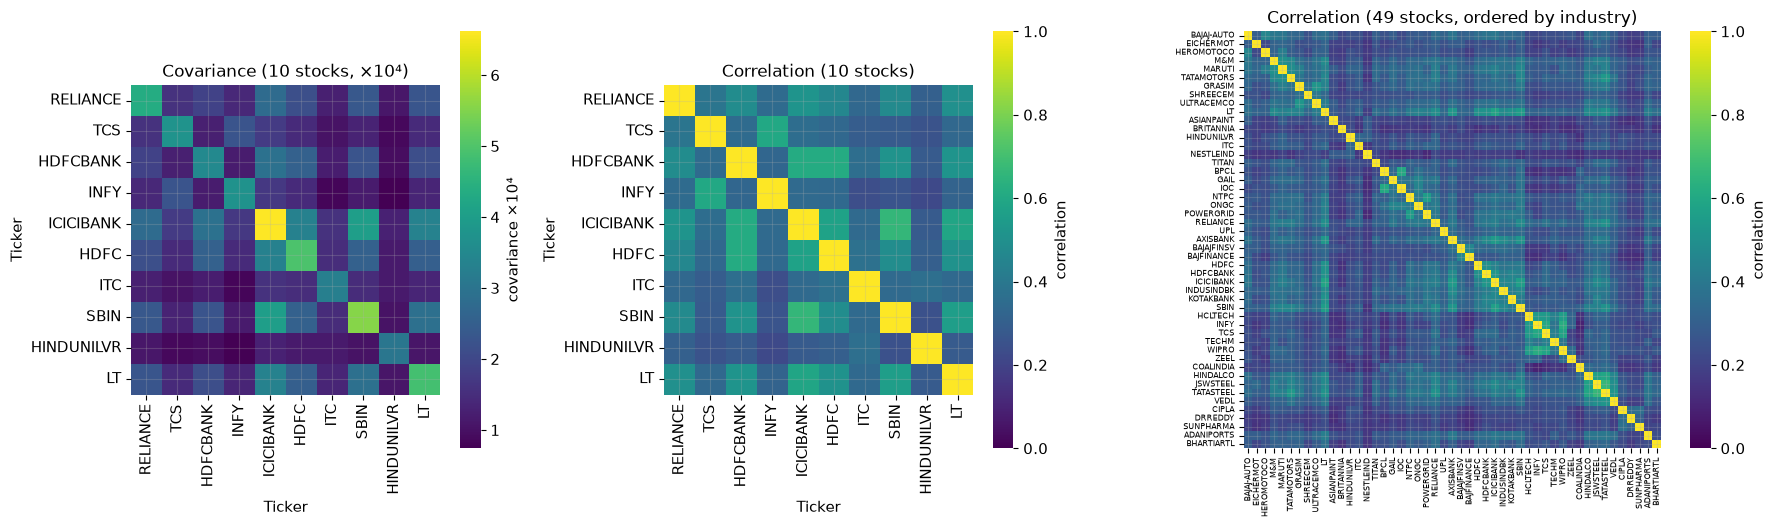

**Observations.** Measuring returns in percent multiplies Cov(RELIANCE, TCS) by 10⁴ (1.578e-04 → 1.5779), while the correlation stays at 0.3892, showing scale invariance. Mean correlation is 0.389 within an industry and 0.275 across industries. Every pair is positive (minimum 0.091), which points to a common market factor; Unit 3's PCA tests that directly.

In [12]:
COV_SET = ["RELIANCE", "TCS", "HDFCBANK", "INFY", "ICICIBANK", "HDFC", "ITC", "SBIN", "HINDUNILVR", "LT"]
Wall = ret.pivot(index="Date", columns="Ticker", values="r")
W10 = Wall[COV_SET].dropna()
C10, R10 = W10.cov(), W10.corr()
print("10-stock panel:", W10.index.min().date(), "→", W10.index.max().date(), "days:", len(W10))
display((C10 * 1e4).round(3)); display(R10.round(3))
c_rt, r_rt = C10.loc["RELIANCE", "TCS"], R10.loc["RELIANCE", "TCS"]
Wp = W10 * 100
c_pct, r_pct = Wp.cov().loc["RELIANCE", "TCS"], Wp.corr().loc["RELIANCE", "TCS"]
assert abs(r_pct - r_rt) < 1e-12 and abs(c_pct / c_rt - 1e4) < 1e-6
print(f"Cov(RELIANCE,TCS) = {c_rt:.6e} (log-return²); in % returns = {c_pct:.5f} (×10⁴). Corr = {r_rt:.6f} in both.")
Rall = Wall.corr(min_periods=250)
ind_of = meta.set_index("Symbol").Industry
order = sorted(Rall.columns, key=lambda t: (ind_of[t], t))
Rord = Rall.loc[order, order]
_iu = np.triu_indices(len(order), 1)
_a = np.array(order)[_iu[0]]; _b = np.array(order)[_iu[1]]; _v2 = Rord.values[_iu]
_ok = ~np.isnan(_v2); same = ind_of[_a].values == ind_of[_b].values
within, cross = _v2[_ok & same], _v2[_ok & ~same]
ttest = stats.ttest_ind(within, cross, equal_var=False)
_within_by = pd.DataFrame(dict(i=ind_of[_a].values, s=same, v=_v2))[lambda d: d.s].groupby("i").v.agg(["mean", "size"])
print(f"Pairs: {_ok.sum()} ({len(within)} within, {len(cross)} cross). Mean corr within = {within.mean():.4f}, cross = {cross.mean():.4f}. Min {_v2[_ok].min():.4f}, max {_v2[_ok].max():.4f}; negative pairs: {(_v2[_ok] < 0).sum()}")
display(_within_by.round(4))
_imax = np.nanargmax(_v2); _imin = np.nanargmin(_v2)
R["u1_cov"] = dict(n_days=len(W10), start=W10.index.min(), end=W10.index.max(), cov_rt=c_rt, cov_rt_pct=c_pct, corr_rt=r_rt, corr_rt_pct=r_pct, mean_within=within.mean(), mean_cross=cross.mean(), n_within=len(within), n_cross=len(cross), n_pairs=int(_ok.sum()), n_negative=int((_v2[_ok] < 0).sum()), corr_min=_v2[_ok].min(), corr_max=_v2[_ok].max(),
    max_pair=[_a[_imax], _b[_imax]], min_pair=[_a[_imin], _b[_imin]], welch_p=ttest.pvalue, by_industry=_within_by.reset_index().to_dict("records"))
chart("u1_heatmaps", dict(tickers10=COV_SET, cov10=np.round(C10.values * 1e4, 3), corr10=np.round(R10.values, 3), tickers49=order, industry49=[ind_of[t] for t in order], corr49=np.round(Rord.values, 3)))
fig, ax = plt.subplots(1, 3, figsize=(18, 5.4), gridspec_kw=dict(width_ratios=[1, 1, 1.5]))
sns.heatmap(C10 * 1e4, ax=ax[0], cmap="viridis", square=True, cbar_kws=dict(label="covariance ×10⁴")); ax[0].set_title("Covariance (10 stocks, ×10⁴)")
sns.heatmap(R10, ax=ax[1], vmin=0, vmax=1, cmap="viridis", square=True, cbar_kws=dict(label="correlation")); ax[1].set_title("Correlation (10 stocks)")
sns.heatmap(Rord, ax=ax[2], vmin=0, vmax=1, cmap="viridis", square=True, xticklabels=True, yticklabels=True, cbar_kws=dict(label="correlation")); ax[2].tick_params(labelsize=5.5); ax[2].set_title("Correlation (49 stocks, ordered by industry)"); ax[2].set_xlabel(""); ax[2].set_ylabel("")
plt.tight_layout(); savefig("u1_heatmaps"); plt.show()
obs(f"Measuring returns in percent multiplies Cov(RELIANCE, TCS) by 10⁴ ({c_rt:.3e} → {c_pct:.4f}), while the correlation stays at {r_rt:.4f}, showing scale invariance. Mean correlation is {within.mean():.3f} within an industry and {cross.mean():.3f} across industries. "
    f"{'Every pair is positive' if (_v2[_ok] < 0).sum() == 0 else str((_v2[_ok] < 0).sum()) + ' pairs are negative'} (minimum {_v2[_ok].min():.3f}), which points to a common market factor; Unit 3's PCA tests that directly.")

## Polynomial curve fitting of the price trend

We fit `Adj ≈ Σ_k w_k x^k` for degree M = 1…12 on RELIANCE, where x is the trading-day index scaled to [0, 1] over the training period. Each degree is evaluated three ways:

- training RMSE,
- **future hold-out** RMSE on the test period (x > 1, an extrapolation),
- **random hold-out** RMSE, with 20% of training days held out at random and refitted on the rest (interpolation).

,train_rmse,future_rmse,random_rmse
degree,,,
1,112.01,815.31,114.64
2,108.92,908.87,110.69
3,108.75,867.77,110.36
4,73.61,322.07,74.07
5,71.01,842.25,72.24
6,67.77,479.13,69.21
7,64.59,2176.92,65.61
8,57.27,10354.65,59.06
9,57.22,8902.38,58.98


Best degree: train = 12, future hold-out = 4, random hold-out = 12
Random hold-out's choice M = 12 has future RMSE 20429.4; the future-best M = 4 has 322.1


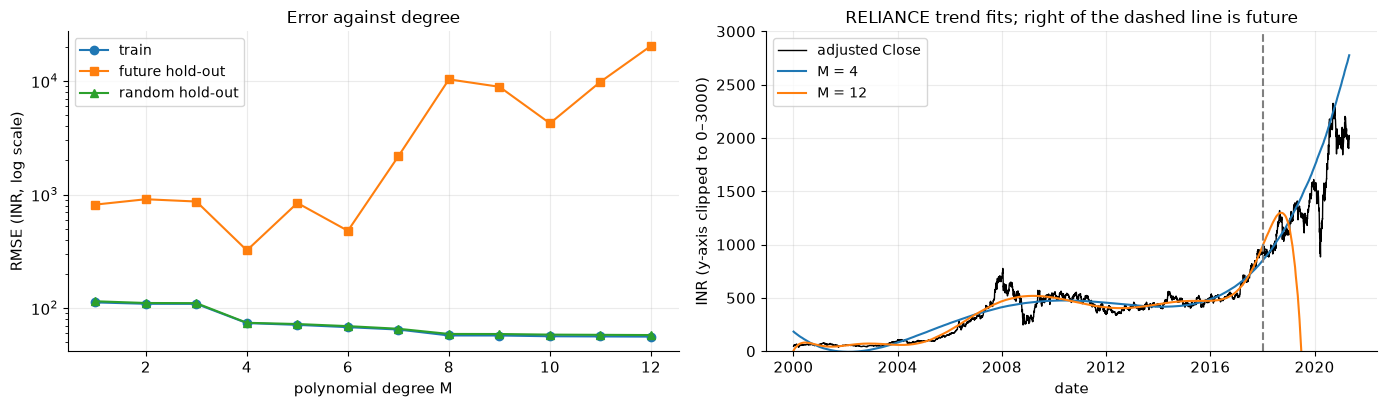

**Observations.** Training RMSE falls with every added degree, to 55.9 at M = 12. The future hold-out is lowest at M = 4 (RMSE 322) and reaches 20,429 at M = 12, because polynomials explode outside [0, 1]. A random hold-out picks M = 12, which is the wrong answer: it only tests interpolation, since held-out days sit between training days. Its pick has a future RMSE of 20,429. A polynomial can describe past prices, but it is not a forecasting model.

In [13]:
_rp = rel[["Adj"]].copy(); _rp["i"] = np.arange(len(_rp))
_tr = _rp[_rp.index < TEST_START]; _te = _rp[_rp.index >= TEST_START]
scale = _tr.i.max()
xtr, ytr, xte, yte = _tr.i.values / scale, _tr.Adj.values, _te.i.values / scale, _te.Adj.values
_prng = np.random.default_rng(SEED)
_perm = _prng.permutation(len(xtr)); _hold, _fit = _perm[: len(xtr) // 5], _perm[len(xtr) // 5:]
poly_rows = []; curves = {}
xplot_i = np.r_[np.arange(0, len(_rp), 8), len(_rp) - 1]; xplot = _rp.i.values[xplot_i] / scale
for M in range(1, 13):
    w = np.linalg.lstsq(np.vander(xtr, M + 1, increasing=True), ytr, rcond=None)[0]
    wr = np.linalg.lstsq(np.vander(xtr[_fit], M + 1, increasing=True), ytr[_fit], rcond=None)[0]
    pf = lambda x, c=w: np.vander(x, M + 1, increasing=True) @ c
    poly_rows.append(dict(degree=M, train_rmse=np.sqrt(np.mean((ytr - pf(xtr)) ** 2)), future_rmse=np.sqrt(np.mean((yte - pf(xte)) ** 2)), random_rmse=np.sqrt(np.mean((ytr[_hold] - pf(xtr[_hold], wr)) ** 2))))
    curves[M] = rnd(pf(xplot), 1)
poly = pd.DataFrame(poly_rows).set_index("degree"); display(poly.round(2))
assert (poly.train_rmse.diff().dropna() <= 1e-6).all()
best_f, best_r, best_t = int(poly.future_rmse.idxmin()), int(poly.random_rmse.idxmin()), int(poly.train_rmse.idxmin())
print(f"Best degree: train = {best_t}, future hold-out = {best_f}, random hold-out = {best_r}")
print(f"Random hold-out's choice M = {best_r} has future RMSE {poly.loc[best_r,'future_rmse']:.1f}; the future-best M = {best_f} has {poly.loc[best_f,'future_rmse']:.1f}")
R["u1_poly"] = dict(table=poly_rows, best_future=best_f, best_random=best_r, best_train=best_t, future_at_best_future=poly.loc[best_f, "future_rmse"], future_at_best_random=poly.loc[best_r, "future_rmse"], future_at_12=poly.loc[12, "future_rmse"], train_at_12=poly.loc[12, "train_rmse"], n_holdout=len(_hold))
chart("u1_poly", dict(table=poly_rows, date=dstr(_rp.index[xplot_i]), actual=rnd(_rp.Adj.values[xplot_i], 1), curves=curves, split_date=str(TEST_START.date()), best_future=best_f, best_random=best_r))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].semilogy(poly.index, poly.train_rmse, "o-", label="train"); ax[0].semilogy(poly.index, poly.future_rmse, "s-", label="future hold-out"); ax[0].semilogy(poly.index, poly.random_rmse, "^-", label="random hold-out")
ax[0].set_xlabel("polynomial degree M"); ax[0].set_ylabel("RMSE (INR, log scale)"); ax[0].legend(); ax[0].set_title("Error against degree")
ax[1].plot(_rp.index, _rp.Adj, "k", lw=1, label="adjusted Close")
for M in (best_f, 12): ax[1].plot(_rp.index[xplot_i], curves[M], label=f"M = {M}")
ax[1].axvline(TEST_START, color="grey", ls="--"); ax[1].set_ylim(0, 3000); ax[1].set_ylabel("INR (y-axis clipped to 0–3000)"); ax[1].set_xlabel("date"); ax[1].legend(); ax[1].set_title("RELIANCE trend fits; right of the dashed line is future")
plt.tight_layout(); savefig("u1_polynomial"); plt.show()
save_results()
obs(f"Training RMSE falls with every added degree, to {poly.loc[12,'train_rmse']:.1f} at M = 12. The future hold-out is lowest at M = {best_f} (RMSE {poly.loc[best_f,'future_rmse']:.0f}) and reaches {poly.loc[12,'future_rmse']:,.0f} at M = 12, because polynomials explode outside [0, 1]. "
    f"A random hold-out picks M = {best_r}, which is the wrong answer: it only tests interpolation, since held-out days sit between training days. Its pick has a future RMSE of {poly.loc[best_r,'future_rmse']:,.0f}. A polynomial can describe past prices, but it is not a forecasting model.")

# UNIT 2
**Assigned title:** Next-day closing price prediction with ridge & Bayesian linear regression; up/down movement classification with Bayesian logistic regression & SVM

**Syllabus mapping:** MLE / least squares, robust linear regression, ridge & Bayesian linear regression → next-day Close; discriminant functions, probabilistic generative & discriminative models, Laplace approximation & Bayesian logistic regression, kernel functions / kernel trick, SVM → up/down direction.

## Unit 2, Practice 1: linear regression for prediction

- **Target A (price level):** `Close_{t+1}` from raw lags (adjusted Close at lags 0–4 and log volume).
- **Target B (return):** `r_{t+1}`, converted back as `Ĉ_{t+1} = C_t·exp(r̂)`, from the 21 engineered features or from a small raw-return set.
- **Baseline:** persistence, `Ĉ_{t+1} = C_t`.

Metrics are on the price scale over the same test rows. **Out-of-sample R² on returns** is `1 − Σ(r − r̂)² / Σ(r − b)²`. Its main benchmark is **b = 0, the zero-return forecast, which is exactly persistence**, so it is negative when a model does worse than persistence. A second column uses b = training mean return.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, HuberRegressor, Ridge, BayesianRidge, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, log_loss, confusion_matrix

y_true = Dte.close_next.values; c_t = Dte.close_t.values; r_true = Dte.r_next.values
r_train_mean = Dtr.r_next.mean()
yB = Dtr.r_next.values; yA = Dtr.close_next.values

def tune(make, param, grid, X, y, scoring, cv=tscv, max_ext=4, factor=100.0, rel_tol=1e-4):
    """TimeSeriesSplit grid search. While the winner sits on an edge the grid is extended; extension stops when the
    CV score has flattened (relative gain below rel_tol), and the plateau is reported rather than chased."""
    grid = list(grid); notes = []; prev = None; plateau = False
    for _ in range(max_ext + 1):
        gs = GridSearchCV(make(), {param: grid}, cv=cv, scoring=scoring).fit(X, y)
        best = gs.best_params_[param]
        if best not in (grid[0], grid[-1]): break
        if prev is not None and abs(gs.best_score_ - prev[0].best_score_) <= rel_tol * abs(prev[0].best_score_):
            gs, best = prev; plateau = True; notes.append(f"flat beyond {best:g}"); break
        prev = (gs, best); notes.append(f"edge at {best:g}")
        grid = grid + [grid[-1] * factor] if best == grid[-1] else [grid[0] / factor] + grid
    used = [float(g) for g in gs.param_grid[param]]
    at_edge = best in (used[0], used[-1])
    curve = dict(grid=used, score=(-gs.cv_results_["mean_test_score"] if scoring.startswith("neg") else gs.cv_results_["mean_test_score"]).tolist())
    return gs, dict(best=best, at_edge=at_edge, plateau=plateau, extended=notes, curve=curve)

def dm_test(e1, e0, lags=5):
    """Diebold–Mariano on squared-error loss, with a Newey–West long-run variance."""
    d = e1 ** 2 - e0 ** 2; n = len(d); dc = d - d.mean()
    v = dc @ dc / n + 2 * sum((1 - l / (lags + 1)) * (dc[l:] @ dc[:-l]) / n for l in range(1, lags + 1))
    t_ = d.mean() / np.sqrt(v / n)
    return t_, 2 * stats.norm.sf(abs(t_))

REG, PRED = {}, {}
def rec(key, label, target, feats, price_hat):
    price_hat = np.asarray(price_hat)
    rhat = np.log(price_hat / c_t)
    e, e0 = y_true - price_hat, y_true - c_t
    dmt, dmp = (None, None) if key == "persistence" else dm_test(e, e0)
    REG[key] = dict(key=key, model=label, target=target, features=feats, rmse=np.sqrt(np.mean(e ** 2)), mae=np.mean(np.abs(e)), mape=100 * np.mean(np.abs(e / y_true)),
                    r2_price=1 - np.sum(e ** 2) / np.sum((y_true - y_true.mean()) ** 2), r2_ret_zero=1 - np.sum((r_true - rhat) ** 2) / np.sum(r_true ** 2), r2_ret_mean=1 - np.sum((r_true - rhat) ** 2) / np.sum((r_true - r_train_mean) ** 2), dm_t=dmt, dm_p=dmp)
    PRED[key] = price_hat

rec("persistence", "Persistence", "baseline", "none", c_t)
print({k: round(v, 5) for k, v in REG["persistence"].items() if isinstance(v, float)})
print(f"Train mean return used by the second benchmark: {r_train_mean:.6f}")

{'rmse': np.float64(30.30508), 'mae': np.float64(20.81551), 'mape': np.float64(1.46929), 'r2_price': np.float64(0.9943), 'r2_ret_zero': np.float64(0.0), 'r2_ret_mean': np.float64(-0.00174)}
Train mean return used by the second benchmark: 0.000634


### Least squares = maximum likelihood under Gaussian noise

For `t = wᵀφ(x) + ε`, ε ~ N(0, β⁻¹), the log-likelihood is `(N/2)ln β − (N/2)ln 2π − (β/2)Σ(t_n − wᵀφ_n)²`. Maximising it over w is the same as minimising the sum of squares. We compare the closed form, scikit-learn, and a numerical optimiser that maximises the full likelihood over both w and ln β.

In [15]:
scA = StandardScaler().fit(Dtr[RAWC]); XA, XAte = scA.transform(Dtr[RAWC]), scA.transform(Dte[RAWC])
scB = StandardScaler().fit(Dtr[ENG]); XB, XBte = scB.transform(Dtr[ENG]), scB.transform(Dte[ENG])
scC = StandardScaler().fit(Dtr[RAWRET]); XC, XCte = scC.transform(Dtr[RAWRET]), scC.transform(Dte[RAWRET])
PhiB = np.c_[np.ones(len(XB)), XB]
w_cf = np.linalg.lstsq(PhiB, yB, rcond=None)[0]
_lr = LinearRegression().fit(XB, yB)
def _nll(theta):
    w, lb = theta[:-1], theta[-1]; res = yB - PhiB @ w
    return -(0.5 * len(yB) * (lb - np.log(2 * np.pi)) - 0.5 * np.exp(lb) * res @ res) / len(yB)
def _gnll(theta):
    w, lb = theta[:-1], theta[-1]; res = yB - PhiB @ w
    return np.r_[-np.exp(lb) * PhiB.T @ res, -(0.5 * len(yB) - 0.5 * np.exp(lb) * res @ res)] / len(yB)
_opt = optimize.minimize(_nll, np.r_[np.zeros(PhiB.shape[1]), np.log(1 / yB.var())], jac=_gnll, method="L-BFGS-B", options=dict(maxiter=20000, ftol=1e-15, gtol=1e-11))
w_mle, beta_mle = _opt.x[:-1], np.exp(_opt.x[-1])
beta_cf = 1 / np.mean((yB - PhiB @ w_cf) ** 2)
ols_mle_diff, ols_sk_diff = np.max(np.abs(w_mle - w_cf)), np.max(np.abs(np.r_[_lr.intercept_, _lr.coef_] - w_cf))
print(f"max |w_closed − w_MLE| = {ols_mle_diff:.2e} | max |w_closed − w_sklearn| = {ols_sk_diff:.2e} | β closed {beta_cf:.3f} vs β MLE {beta_mle:.3f}")
R_u2_ols = dict(mle_diff=ols_mle_diff, sk_diff=ols_sk_diff, beta_closed=beta_cf, beta_mle=beta_mle, sigma_ml=1 / np.sqrt(beta_cf), cond_A=np.linalg.cond(np.c_[np.ones(len(XA)), XA].T @ np.c_[np.ones(len(XA)), XA]), cond_B=np.linalg.cond(PhiB.T @ PhiB))

for key, lab, X, Xte, tgt, feats in [("ols_a", "OLS", XA, XAte, "A", "RAW"), ("ols_b_raw", "OLS", XC, XCte, "B", "RAW-returns"), ("ols_b_eng", "OLS", XB, XBte, "B", "ENGINEERED")]:
    y = yA if tgt == "A" else yB
    p = LinearRegression().fit(X, y).predict(Xte)
    rec(key, lab, tgt, feats, p if tgt == "A" else c_t * np.exp(p))
obs(f"OLS equals MLE: the closed form and the numerical maximiser differ by at most {ols_mle_diff:.1e} in any weight, and β differs only in the rounding ({beta_cf:.3f} vs {beta_mle:.3f}).")

max |w_closed − w_MLE| = 1.25e-09 | max |w_closed − w_sklearn| = 3.90e-18 | β closed 2239.345 vs β MLE 2239.345


**Observations.** OLS equals MLE: the closed form and the numerical maximiser differ by at most 1.2e-09 in any weight, and β differs only in the rounding (2239.345 vs 2239.345).

### Robust regression (Huber) and ridge

**Huber** uses squared loss for small residuals and absolute loss for large ones, which limits the pull of fat-tailed days. Its ε is tuned on `TimeSeriesSplit`. Returns are standardised before fitting so the optimiser is well scaled, and predictions are scaled back with training statistics only.

**Ridge** minimises `Σ(t − wᵀφ)² + α‖w‖²`, the MAP estimate under a Gaussian prior. α is tuned on `TimeSeriesSplit`, and if CV picks a grid edge the grid is extended.

Huber: {'huber_a': (2.5, 225), 'huber_b_eng': (1.35, 1629)}
ridge_a α = 1e-05 | at edge after extension: True | flat: True | extended: ['edge at 0.001', 'edge at 1e-05', 'flat beyond 1e-05'] | ‖w‖ ridge vs OLS: 223.583079 223.583474


ridge_b_raw α = 3162.2776601683795 | at edge after extension: False | flat: False | extended: [] | ‖w‖ ridge vs OLS: 0.001032 0.001741
ridge_b_eng α = 10000.0 | at edge after extension: False | flat: False | extended: [] | ‖w‖ ridge vs OLS: 0.000649 0.002844


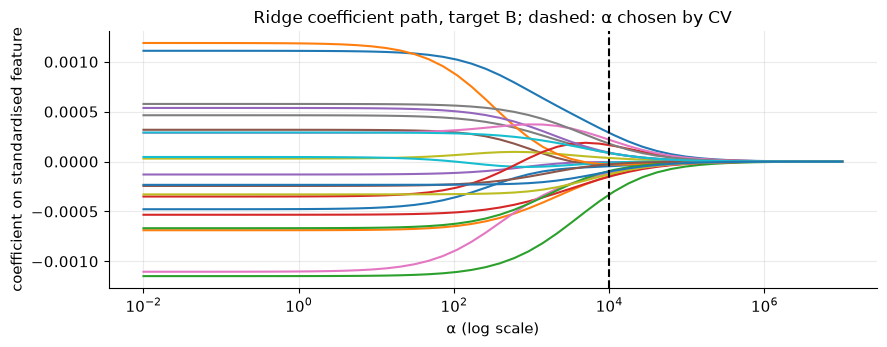

**Observations.** Huber treats 1629 of 4405 training days as outliers on target B (ε = 1.35). CV ridge on engineered features picks α = 10000; this is inside the grid, so no extension was needed. On target A, CV's preference is flat towards OLS (α → 0), so ridge and OLS give the same forecast there. Its coefficient norm shrinks from 0.00284 to 0.00065, so CV prefers little signal over noisy signal.

In [16]:
class ScaledY:
    def __init__(self, base): self.base = base
    def fit(self, X, y):
        self.m, self.s = y.mean(), y.std(); self.base.fit(X, (y - self.m) / self.s); return self
    def predict(self, X): return self.base.predict(X) * self.s + self.m

def tune_huber(X, y, grid=(1.05, 1.15, 1.35, 1.75, 2.5, 5.0)):
    cvm = {}
    for e in grid:
        ls = []
        for a, b in tscv.split(X):
            ls.append(np.mean((y[b] - ScaledY(HuberRegressor(epsilon=e, alpha=1e-4, max_iter=5000)).fit(X[a], y[a]).predict(X[b])) ** 2))
        cvm[e] = np.mean(ls)
    best = min(cvm, key=cvm.get); return best, cvm

huber_info = {}
for key, X, Xte, tgt, feats in [("huber_a", XA, XAte, "A", "RAW"), ("huber_b_eng", XB, XBte, "B", "ENGINEERED")]:
    y = yA if tgt == "A" else yB
    eps, cvm = tune_huber(X, y)
    m_ = ScaledY(HuberRegressor(epsilon=eps, alpha=1e-4, max_iter=5000)).fit(X, y)
    p = m_.predict(Xte)
    rec(key, "Huber", tgt, feats, p if tgt == "A" else c_t * np.exp(p))
    huber_info[key] = dict(epsilon=eps, outliers=int(m_.base.outliers_.sum()), n=len(y), at_edge=eps in (1.05, 5.0), cv=cvm)
print("Huber:", {k: (v["epsilon"], v["outliers"]) for k, v in huber_info.items()})

ridge_info = {}
for key, X, Xte, tgt, feats in [("ridge_a", XA, XAte, "A", "RAW"), ("ridge_b_raw", XC, XCte, "B", "RAW-returns"), ("ridge_b_eng", XB, XBte, "B", "ENGINEERED")]:
    y = yA if tgt == "A" else yB
    gs, info = tune(lambda: Ridge(), "alpha", np.logspace(-3, 5, 17), X, y, "neg_mean_squared_error")
    p = gs.predict(Xte); rec(key, "Ridge", tgt, feats, p if tgt == "A" else c_t * np.exp(p))
    info["coef_norm"] = float(np.linalg.norm(gs.best_estimator_.coef_)); info["ols_coef_norm"] = float(np.linalg.norm(LinearRegression().fit(X, y).coef_))
    ridge_info[key] = info
    print(key, "α =", info["best"], "| at edge after extension:", info["at_edge"], "| flat:", info["plateau"], "| extended:", info["extended"], "| ‖w‖ ridge vs OLS:", round(info["coef_norm"], 6), round(info["ols_coef_norm"], 6))
_alphas = np.logspace(-2, 7, 50)
_path = np.array([Ridge(alpha=a).fit(XB, yB).coef_ for a in _alphas])
chart("u2_ridge", dict(alphas=rnd(_alphas, 4), path=np.round(_path, 6), features=ENG, chosen=ridge_info["ridge_b_eng"]["best"], cv_grid=ridge_info["ridge_b_eng"]["curve"]["grid"], cv_mse=[float(f"{x:.6g}") for x in ridge_info["ridge_b_eng"]["curve"]["score"]]))
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.semilogx(_alphas, _path); ax.axvline(ridge_info["ridge_b_eng"]["best"], color="k", ls="--"); ax.set_xlabel("α (log scale)"); ax.set_ylabel("coefficient on standardised feature"); ax.set_title("Ridge coefficient path, target B; dashed: α chosen by CV"); plt.tight_layout(); savefig("u2_ridge_path"); plt.show()
obs(f"Huber treats {huber_info['huber_b_eng']['outliers']} of {huber_info['huber_b_eng']['n']} training days as outliers on target B (ε = {huber_info['huber_b_eng']['epsilon']}). "
    f"CV ridge on engineered features picks α = {ridge_info['ridge_b_eng']['best']:g}; this is inside the grid, so no extension was needed. On target A, CV's preference is flat towards OLS (α → 0), so ridge and OLS give the same forecast there. Its coefficient norm shrinks from {ridge_info['ridge_b_eng']['ols_coef_norm']:.5f} to {ridge_info['ridge_b_eng']['coef_norm']:.5f}, so CV prefers little signal over noisy signal.")

### Bayesian linear regression from scratch

Prior `w ~ N(0, α⁻¹I)`, likelihood `t ~ N(wᵀφ, β⁻¹)`. The posterior is `N(m_N, S_N)` with `S_N⁻¹ = αI + βΦᵀΦ` and `m_N = βS_NΦᵀt`. The evidence is maximised by the fixed-point updates, where λ_i are the eigenvalues of βΦᵀΦ:

`γ = Σ λ_i/(α+λ_i)`, `α = γ / m_Nᵀm_N`, `1/β = ‖t − Φm_N‖² / (N − γ)`.

γ is the **effective number of parameters**. Features are standardised and t centred, so the bias is ȳ, which matches scikit-learn's `BayesianRidge` when its hyperpriors are switched off. The predictive distribution is `N(m_Nᵀφ, 1/β + φᵀS_Nφ)`.

Target B: α = 7797370.267, β = 2229.338, γ = 9.534 of 21 parameters, 31 iterations
Target A: α = 0.000120, β = 0.015947, γ = 5.990 of 6 parameters
Against sklearn BayesianRidge: max |Δw| = 3.32e-14, relative Δα = 1.27e-10, relative Δβ = 2.75e-13
{'b_all': 0.9562, 'b_high': 0.8882, 'b_low': 0.9728, 'a_all': 0.5158, 'a_high': 0.4161, 'a_low': 0.5401, 'n_high': 161, 'n_low': 661, 'vol_thr': np.float64(0.0215), 'sd_daily': 0.0212, 'sd_price_a': 8.0094}


,model,target,features,rmse,mae,mape,r2_price,r2_ret_zero,r2_ret_mean,dm_t,dm_p
ridge_b_eng,Ridge,B,ENGINEERED,30.282182,20.785715,1.468819,0.994309,-0.002232,-0.003978,-0.347939,0.727886
blr_b_eng,Bayesian LR,B,ENGINEERED,30.291522,20.792137,1.469816,0.994306,-0.005359,-0.007111,-0.144617,0.885013
persistence,Persistence,baseline,none,30.305076,20.815511,1.469286,0.994301,0.0,-0.001742,None,None
ridge_b_raw,Ridge,B,RAW-returns,30.306797,20.813011,1.47042,0.9943,-0.005188,-0.00694,0.020487,0.983655
huber_a,Huber,A,RAW,30.314602,20.851119,1.472211,0.994297,-0.007219,-0.008974,0.085057,0.932216
blr_a,Bayesian LR,A,RAW,30.332674,20.860056,1.472531,0.99429,-0.009195,-0.010953,0.235884,0.813523
ridge_a,Ridge,A,RAW,30.334901,20.862203,1.472676,0.99429,-0.009462,-0.011221,0.251539,0.801397
ols_a,OLS,A,RAW,30.334904,20.862206,1.472676,0.99429,-0.009462,-0.011221,0.25156,0.801381
ols_b_eng,OLS,B,ENGINEERED,30.343732,20.841771,1.474154,0.994286,-0.010882,-0.012643,0.282035,0.777917
ols_b_raw,OLS,B,RAW-returns,30.361874,20.861992,1.474309,0.994279,-0.012742,-0.014507,0.429328,0.667684


Below persistence: 2 of 10. Significantly different: 0; significantly better: 0. Lowest RMSE: ridge_b_eng


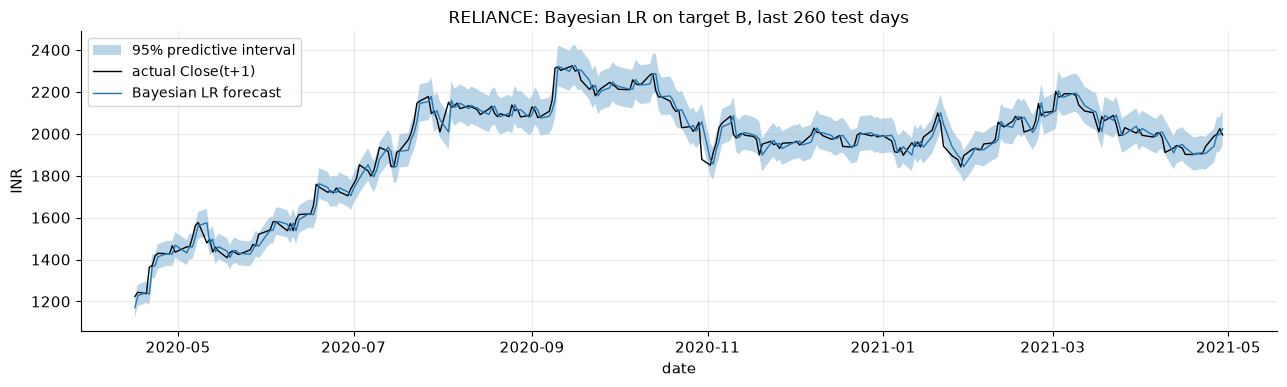

**Observations.** The persistence baseline has RMSE 30.305 and a price R² of 0.9943. That R² means nothing about skill: tomorrow's price is close to today's, so any model that copies today scores about 0.99. 2 of 10 models have RMSE below persistence and **0 are significantly better** (Diebold–Mariano); the lowest is Ridge [B|ENGINEERED] at 30.282 (p = 0.728). Bayesian LR on target B keeps only γ = 9.53 effective parameters of 21, and matches scikit-learn (max |Δw| = 3.3e-14). Its 95% interval covers 95.6% overall but 88.8% on the 161 high-volatility days, since a constant noise variance cannot follow volatility clustering. The price-level model covers only 51.6%: its noise was learned when prices were far lower, and price-level errors grow with the price.

In [17]:
def blr_evidence(X, y, iters=2000, tol=1e-12):
    ym = y.mean(); t = y - ym
    eig0, Q = np.linalg.eigh(X.T @ X); Xt = X.T @ t
    alpha, beta = 1.0, 1 / t.var()
    log = []
    for it in range(iters):
        lam = beta * eig0
        m = beta * Q @ ((Q.T @ Xt) / (alpha + lam))
        gamma = np.sum(lam / (alpha + lam))
        a_new = gamma / (m @ m); res = t - X @ m; b_new = (len(t) - gamma) / (res @ res)
        conv = abs(np.log(a_new / alpha)) + abs(np.log(b_new / beta)); alpha, beta = a_new, b_new
        log.append(dict(it=it + 1, alpha=alpha, beta=beta, gamma=gamma))
        if conv < tol: break
    lam = beta * eig0
    S = Q @ np.diag(1 / (alpha + lam)) @ Q.T
    m = beta * S @ Xt
    return dict(m=m, S=S, alpha=alpha, beta=beta, gamma=np.sum(lam / (alpha + lam)), ym=ym, iters=len(log), log=log)

def blr_predict(fit, X):
    mu = X @ fit["m"] + fit["ym"]; var = 1 / fit["beta"] + np.einsum("ij,jk,ik->i", X, fit["S"], X)
    return mu, var

blr_b = blr_evidence(XB, yB); blr_a = blr_evidence(XA, yA)
sk_b = BayesianRidge(alpha_1=0, alpha_2=0, lambda_1=0, lambda_2=0, tol=1e-12, max_iter=5000).fit(XB, yB)
sk_diff_w = np.max(np.abs(blr_b["m"] - sk_b.coef_)); sk_diff_a = abs(blr_b["alpha"] / sk_b.lambda_ - 1); sk_diff_b = abs(blr_b["beta"] / sk_b.alpha_ - 1)
print(f"Target B: α = {blr_b['alpha']:.3f}, β = {blr_b['beta']:.3f}, γ = {blr_b['gamma']:.3f} of {XB.shape[1]} parameters, {blr_b['iters']} iterations")
print(f"Target A: α = {blr_a['alpha']:.6f}, β = {blr_a['beta']:.6f}, γ = {blr_a['gamma']:.3f} of {XA.shape[1]} parameters")
print(f"Against sklearn BayesianRidge: max |Δw| = {sk_diff_w:.2e}, relative Δα = {sk_diff_a:.2e}, relative Δβ = {sk_diff_b:.2e}")
assert sk_diff_w < 1e-6
mu_b, var_b = blr_predict(blr_b, XBte); mu_a, var_a = blr_predict(blr_a, XAte)
rec("blr_b_eng", "Bayesian LR", "B", "ENGINEERED", c_t * np.exp(mu_b)); rec("blr_a", "Bayesian LR", "A", "RAW", mu_a)
z = stats.norm.ppf(0.975)
lo_b, hi_b = c_t * np.exp(mu_b - z * np.sqrt(var_b)), c_t * np.exp(mu_b + z * np.sqrt(var_b))
lo_a, hi_a = mu_a - z * np.sqrt(var_a), mu_a + z * np.sqrt(var_a)
vol_thr = Dtr.rstd_20.quantile(.75); hv = Dte.rstd_20.values > vol_thr
cov = lambda lo, hi, m_=None: float(np.mean((y_true >= lo) & (y_true <= hi))) if m_ is None else float(np.mean(((y_true >= lo) & (y_true <= hi))[m_]))
cov_rows = dict(b_all=cov(lo_b, hi_b), b_high=cov(lo_b, hi_b, hv), b_low=cov(lo_b, hi_b, ~hv), a_all=cov(lo_a, hi_a), a_high=cov(lo_a, hi_a, hv), a_low=cov(lo_a, hi_a, ~hv), n_high=int(hv.sum()), n_low=int((~hv).sum()), vol_thr=vol_thr, sd_daily=float(np.sqrt(np.mean(var_b))), sd_price_a=float(np.sqrt(np.mean(var_a))))
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in cov_rows.items()})
reg_tab = pd.DataFrame(REG).T.drop(columns="key").sort_values("rmse")
display(reg_tab.round(4))
_nb = reg_tab.drop(index="persistence")
n_below = int((_nb.rmse < REG["persistence"]["rmse"]).sum()); n_sig = int((_nb.dm_p.astype(float) < .05).sum()); n_sig_better = int(((_nb.dm_p.astype(float) < .05) & (_nb.rmse < REG["persistence"]["rmse"])).sum())
best_key = _nb.rmse.astype(float).idxmin()
print(f"Below persistence: {n_below} of {len(_nb)}. Significantly different: {n_sig}; significantly better: {n_sig_better}. Lowest RMSE: {best_key}")
R["u2_reg"] = dict(table=list(REG.values()), ols=R_u2_ols, huber={k: {a: b for a, b in v.items() if a != "cv"} for k, v in huber_info.items()}, ridge={k: {a: b for a, b in v.items() if a != "curve"} for k, v in ridge_info.items()},
    blr=dict(b=dict(alpha=blr_b["alpha"], beta=blr_b["beta"], gamma=blr_b["gamma"], iters=blr_b["iters"], n_params=XB.shape[1]), a=dict(alpha=blr_a["alpha"], beta=blr_a["beta"], gamma=blr_a["gamma"], iters=blr_a["iters"], n_params=XA.shape[1]), sk_diff_w=sk_diff_w, sk_diff_alpha=sk_diff_a, sk_diff_beta=sk_diff_b),
    coverage=cov_rows, n_below=n_below, n_models=len(_nb), n_sig=n_sig, n_sig_better=n_sig_better, best=best_key, best_label=f"{REG[best_key]['model']} [{REG[best_key]['target']}|{REG[best_key]['features']}]", r_train_mean=r_train_mean, persistence_r2=REG["persistence"]["r2_price"])
chart("u2_pred", dict(date=dstr(Dte.index), date_target=dstr(pd.Series(rel.index[rel.index.get_indexer(Dte.index) + 1])), actual=rnd(y_true, 2), persistence=rnd(c_t, 2), blr=rnd(PRED["blr_b_eng"], 2), lo=rnd(lo_b, 2), hi=rnd(hi_b, 2), lo_a=rnd(lo_a, 2), hi_a=rnd(hi_a, 2), blr_a=rnd(mu_a, 2), high_vol=[bool(x) for x in hv]))
fig, ax = plt.subplots(figsize=(13, 4)); _k = -260
ax.fill_between(Dte.index[_k:], lo_b[_k:], hi_b[_k:], alpha=.3, label="95% predictive interval"); ax.plot(Dte.index[_k:], y_true[_k:], "k", lw=1, label="actual Close(t+1)"); ax.plot(Dte.index[_k:], PRED["blr_b_eng"][_k:], lw=1, label="Bayesian LR forecast")
ax.set_ylabel("INR"); ax.set_xlabel("date"); ax.set_title("RELIANCE: Bayesian LR on target B, last 260 test days"); ax.legend(); plt.tight_layout(); savefig("u2_blr_band"); plt.show()
obs(f"The persistence baseline has RMSE {REG['persistence']['rmse']:.3f} and a price R² of {REG['persistence']['r2_price']:.4f}. That R² means nothing about skill: tomorrow's price is close to today's, so any model that copies today scores about 0.99. "
    f"{n_below} of {len(_nb)} models have RMSE below persistence and **{n_sig_better} are significantly better** (Diebold–Mariano); the lowest is {REG[best_key]['model']} [{REG[best_key]['target']}|{REG[best_key]['features']}] at {REG[best_key]['rmse']:.3f} (p = {REG[best_key]['dm_p']:.3f}). "
    f"Bayesian LR on target B keeps only γ = {blr_b['gamma']:.2f} effective parameters of {XB.shape[1]}, and matches scikit-learn (max |Δw| = {sk_diff_w:.1e}). Its 95% interval covers {100*cov_rows['b_all']:.1f}% overall but {100*cov_rows['b_high']:.1f}% on the {cov_rows['n_high']} high-volatility days, since a constant noise variance cannot follow volatility clustering. "
    f"The price-level model covers only {100*cov_rows['a_all']:.1f}%: its noise was learned when prices were far lower, and price-level errors grow with the price.")

## Unit 2, Practice 2: Bayesian logistic regression & SVM

Target: `1[r_{t+1} > 0]`. Baselines: the **majority class** from training, and **same-as-today** (predict U_t). All models use the 21 engineered features with train-only scaling.

- **Discriminant function (LDA):** shared covariance gives a linear `a(x) = wᵀx + w₀`, predicting up when a(x) > 0.
- **Generative (Gaussian NB):** models p(x|C) and P(C), then applies Bayes rule.
- **Discriminative (logistic):** models P(C|x) directly.

**Chance checks.** The one-sided binomial test asks whether accuracy exceeds the test-set majority rate. The AUC chance band is the 95% Mann–Whitney null interval: `0.5 ± 1.96·√((n₁+n₀+1)/(12·n₁·n₀))`.

In [18]:
Xc, Xcte = XB, XBte
yc, ycte = Dtr.y_dir.values.astype(int), Dte.y_dir.values.astype(int)
maj_class = int(yc.mean() > .5); maj_rate_test = float(np.mean(ycte == maj_class))
n1, n0 = int(ycte.sum()), int((1 - ycte).sum())
auc_half = 1.96 * np.sqrt((n1 + n0 + 1) / (12 * n1 * n0))
print(f"P(up): train {yc.mean():.5f}, test {ycte.mean():.5f} | majority class on train = {maj_class}, its test accuracy = {maj_rate_test:.5f} | AUC chance band [{.5-auc_half:.4f}, {.5+auc_half:.4f}]")

CLF, ROC = {}, {}
def clf_rec(key, label, yhat, score=None, cv_auc=None, kind="model", prob=None, keep_roc=True):
    yhat = np.asarray(yhat).astype(int); k = int((yhat == ycte).sum())
    row = dict(key=key, model=label, kind=kind, accuracy=k / len(ycte), n_correct=k, n_test=len(ycte), f1=f1_score(ycte, yhat), auc=None if score is None else roc_auc_score(ycte, score), cv_auc=cv_auc,
               log_loss=None if prob is None else log_loss(ycte, np.clip(prob, 1e-9, 1 - 1e-9)), p_vs_majority=stats.binomtest(k, len(ycte), maj_rate_test, alternative="greater").pvalue, share_up=float(yhat.mean()), cm=confusion_matrix(ycte, yhat).tolist())
    row["auc_in_chance_band"] = None if row["auc"] is None else bool(abs(row["auc"] - .5) <= auc_half)
    CLF[key] = row
    if score is not None and keep_roc:
        fpr, tpr, _ = roc_curve(ycte, score); ROC[key] = dict(fpr=rnd(fpr, 4), tpr=rnd(tpr, 4))

clf_rec("majority", "Majority class", np.full(len(ycte), maj_class), kind="baseline", prob=np.full(len(ycte), yc.mean()))
clf_rec("same_as_today", "Same as today", (Dte.r_lag0.values > 0).astype(int), score=(Dte.r_lag0.values > 0).astype(float), kind="baseline")
def cva(make): return float(np.mean(cross_val_score(make(), Xc, yc, cv=tscv, scoring="roc_auc")))

# LDA, with the discriminant written out and compared
_mu1, _mu0 = Xc[yc == 1].mean(0), Xc[yc == 0].mean(0)
_Sw = (np.cov(Xc[yc == 1].T, ddof=0) * yc.sum() + np.cov(Xc[yc == 0].T, ddof=0) * (1 - yc).sum()) / len(yc)
_w_lda = np.linalg.solve(_Sw, _mu1 - _mu0); _w0 = -.5 * (_mu1 + _mu0) @ _w_lda + np.log(yc.mean() / (1 - yc.mean()))
lda = LinearDiscriminantAnalysis(solver="lsqr").fit(Xc, yc)
lda_diff = max(np.max(np.abs(lda.coef_[0] - _w_lda)), abs(lda.intercept_[0] - _w0))
print(f"LDA by formula vs sklearn: max diff {lda_diff:.2e}; bias w0 = {_w0:.5f}")
print("CV AUC by fold, LDA:", np.round(cross_val_score(LinearDiscriminantAnalysis(solver="lsqr"), Xc, yc, cv=tscv, scoring="roc_auc"), 5)); print("CV AUC by fold, GNB:", np.round(cross_val_score(GaussianNB(), Xc, yc, cv=tscv, scoring="roc_auc"), 5))
clf_rec("lda", "LDA", lda.predict(Xcte), lda.decision_function(Xcte), cva(lambda: LinearDiscriminantAnalysis(solver="lsqr")), prob=lda.predict_proba(Xcte)[:, 1])
gnb = GaussianNB().fit(Xc, yc); clf_rec("gnb", "Gaussian NB", gnb.predict(Xcte), gnb.predict_proba(Xcte)[:, 1], cva(GaussianNB), prob=gnb.predict_proba(Xcte)[:, 1])
gs_lr, lr_info = tune(lambda: LogisticRegression(max_iter=5000), "C", np.logspace(-4, 2, 13), Xc, yc, "roc_auc")
clf_rec("logistic", "Logistic regression", gs_lr.predict(Xcte), gs_lr.decision_function(Xcte), float(gs_lr.best_score_), prob=gs_lr.predict_proba(Xcte)[:, 1])
print("Logistic C =", lr_info["best"], "| at edge:", lr_info["at_edge"], "| extended:", lr_info["extended"], "| CV curve:", np.round(lr_info["curve"]["score"], 4).tolist())

P(up): train 0.51578, test 0.51946 | majority class on train = 1, its test accuracy = 0.51946 | AUC chance band [0.4605, 0.5395]
LDA by formula vs sklearn: max diff 1.39e-16; bias w0 = 0.06346
CV AUC by fold, LDA: [0.49557 0.49239 0.49882 0.53364 0.5301 ]
CV AUC by fold, GNB: [0.49229 0.50389 0.50036 0.53262 0.52136]


Logistic C = 1e-06 | at edge: True | extended: ['edge at 0.0001', 'edge at 1e-06', 'flat beyond 1e-06'] | CV curve: [0.5117, 0.5115, 0.5112, 0.5111, 0.5108, 0.5107, 0.5108, 0.5103, 0.5103, 0.5101, 0.5101, 0.5101, 0.5101, 0.5101]


### Bayesian logistic regression: Laplace approximation from scratch

Prior `w ~ N(0, α⁻¹I′)`, where **I′ is the identity with a 0 for the bias**, so the bias is not penalised. Newton / IRLS minimises `Ψ(w) = −ln p(t|w) + (α/2)wᵀI′w`, with gradient `Φᵀ(y − t) + αI′w` and **Hessian `H = ΦᵀRΦ + αI′`**, where R = diag(yₙ(1−yₙ)).

At the mode, the Laplace approximation is `q(w) = N(w_MAP, S_N)` with `S_N = H⁻¹`. The predictive uses the probit approximation: `p(up|x) ≈ σ(κ(σ_a²)·μ_a)`, with `μ_a = w_MAPᵀφ`, `σ_a² = φᵀS_Nφ` and `κ(σ²) = (1 + πσ²/8)^(−1/2)`.

In [19]:
def sigmoid(a): return 1 / (1 + np.exp(-a))
def laplace_fit(X, t, alpha, iters=100, tol=1e-10):
    Phi = np.c_[np.ones(len(X)), X]; I_ = np.ones(Phi.shape[1]); I_[0] = 0.0
    w = np.zeros(Phi.shape[1]); log = []
    for it in range(iters):
        y = sigmoid(Phi @ w); g = Phi.T @ (y - t) + alpha * I_ * w
        H = (Phi * (y * (1 - y))[:, None]).T @ Phi + np.diag(alpha * I_)
        step = np.linalg.solve(H, g); w = w - step
        y2 = np.clip(sigmoid(Phi @ w), 1e-12, 1 - 1e-12)
        log.append(dict(it=it + 1, psi=-(t * np.log(y2) + (1 - t) * np.log(1 - y2)).sum() + .5 * alpha * (I_ * w) @ w, grad_norm=np.linalg.norm(g), step_norm=np.linalg.norm(step)))
        if np.linalg.norm(step) < tol: break
    y = sigmoid(Phi @ w); H = (Phi * (y * (1 - y))[:, None]).T @ Phi + np.diag(alpha * I_)
    return dict(w=w, H=H, S=np.linalg.inv(H), log=log, alpha=alpha)
def laplace_pred(X, f):
    Phi = np.c_[np.ones(len(X)), X]; mu = Phi @ f["w"]; s2 = np.einsum("ij,jk,ik->i", Phi, f["S"], Phi); kappa = (1 + np.pi * s2 / 8) ** -.5
    return sigmoid(kappa * mu), sigmoid(mu), mu, s2
def laplace_log_evidence(X, t, f):
    Phi = np.c_[np.ones(len(X)), X]; y = np.clip(sigmoid(Phi @ f["w"]), 1e-12, 1 - 1e-12); M = Phi.shape[1] - 1
    ll = (t * np.log(y) + (1 - t) * np.log(1 - y)).sum(); w_ = f["w"][1:]
    return ll + .5 * M * np.log(f["alpha"]) - .5 * f["alpha"] * w_ @ w_ - .5 * np.linalg.slogdet(f["H"])[1] + .5 * np.log(2 * np.pi)

_grid = [10.0 ** k for k in range(-2, 7)]
def cv_lap(a): return float(np.mean([roc_auc_score(yc[b], laplace_pred(Xc[b], laplace_fit(Xc[a_], yc[a_], a))[0]) for a_, b in tscv.split(Xc)]))
cv_bl = {a: cv_lap(a) for a in _grid}
alpha_plateau = False
while max(cv_bl, key=cv_bl.get) == max(_grid) and max(_grid) < 1e10:
    _top = max(_grid); _grid.append(_top * 100); cv_bl[_grid[-1]] = cv_lap(_grid[-1])
    if abs(cv_bl[_grid[-1]] - cv_bl[_top]) <= 1e-4 * cv_bl[_top]:
        alpha_plateau = True; break
_cvmax = max(cv_bl.values())
ALPHA = _top if alpha_plateau else max(cv_bl, key=cv_bl.get)
alpha_edge = ALPHA >= max(k for k in _grid if k <= ALPHA) and alpha_plateau
evid = {a: laplace_log_evidence(Xc, yc.astype(float), laplace_fit(Xc, yc.astype(float), a)) for a in _grid}
ALPHA_EV = max(evid, key=evid.get)
print("CV AUC by α:", {f"{k:g}": round(v, 5) for k, v in cv_bl.items()}); print("Selected α =", ALPHA, "| CV flat beyond it:", alpha_plateau)
print("Laplace log evidence by α:", {f"{k:g}": round(v, 2) for k, v in evid.items()}, "→ evidence-best α =", ALPHA_EV)
lap = laplace_fit(Xc, yc.astype(float), ALPHA)
display(pd.DataFrame(lap["log"]))
eigH = np.linalg.eigvalsh(lap["H"])
Phi_ = np.c_[np.ones(len(Xc)), Xc]; y_ = sigmoid(Phi_ @ lap["w"]); eigD = np.linalg.eigvalsh((Phi_ * (y_ * (1 - y_))[:, None]).T @ Phi_)
sk_l = LogisticRegression(C=1 / ALPHA, max_iter=100000, tol=1e-10).fit(Xc, yc)
lap_diff = np.max(np.abs(lap["w"] - np.r_[sk_l.intercept_, sk_l.coef_[0]]))
pm, pmap, mu_l, s2_l = laplace_pred(Xcte, lap)
print(f"H = ΦᵀRΦ + αI′ with α = {ALPHA:g}: min eig {eigH.min():.4f}, max eig {eigH.max():.2f} (ΦᵀRΦ alone: min {eigD.min():.4f}). Bias diagonal is H[0,0] = {lap['H'][0,0]:.2f}, which carries no α because I′ excludes the bias.")
print(f"max |w_MAP − sklearn| = {lap_diff:.2e} | Newton iterations {len(lap['log'])}")
print(f"σ_a²: mean {s2_l.mean():.6f}, max {s2_l.max():.6f}; mean κ = {np.mean((1+np.pi*s2_l/8)**-.5):.6f}; mean |p−0.5| = {np.mean(np.abs(pm-.5)):.5f}, max {np.max(np.abs(pm-.5)):.5f}; mean |p_MAP − p_probit| = {np.mean(np.abs(pm-pmap)):.2e}")
clf_rec("bayes_logistic", "Bayesian logistic (Laplace)", (pm > .5).astype(int), pm, cv_bl[ALPHA], prob=pm)
# the evidence-based alpha, reported alongside
lap_ev = laplace_fit(Xc, yc.astype(float), ALPHA_EV); pm_ev = laplace_pred(Xcte, lap_ev)[0]
print(f"Evidence-best α = {ALPHA_EV:g}: test AUC {roc_auc_score(ycte, pm_ev):.4f}, accuracy {np.mean((pm_ev>.5)==ycte):.4f}")
R_lap = dict(alpha=ALPHA, alpha_plateau=alpha_plateau, cv={f"{k:g}": v for k, v in cv_bl.items()}, log_evidence={f"{k:g}": v for k, v in evid.items()}, alpha_evidence=ALPHA_EV, ev_auc=roc_auc_score(ycte, pm_ev), ev_acc=float(np.mean((pm_ev > .5) == ycte)), iters=len(lap["log"]), log=lap["log"], min_eig_H=eigH.min(), max_eig_H=eigH.max(), min_eig_data=eigD.min(), H00=lap["H"][0, 0], sk_diff=lap_diff, s2_mean=s2_l.mean(), s2_max=s2_l.max(), kappa_mean=np.mean((1 + np.pi * s2_l / 8) ** -.5), mean_abs_p=np.mean(np.abs(pm - .5)), max_abs_p=np.max(np.abs(pm - .5)), mean_map_probit_diff=np.mean(np.abs(pm - pmap)))

CV AUC by α: {'0.01': 0.51015, '0.1': 0.51013, '1': 0.51008, '10': 0.51028, '100': 0.51074, '1000': 0.51107, '10000': 0.51151, '100000': 0.51171, '1e+06': 0.51173, '1e+08': 0.51174}
Selected α = 1000000.0 | CV flat beyond it: True
Laplace log evidence by α: {'0.01': np.float64(-3158.97), '0.1': np.float64(-3134.79), '1': np.float64(-3110.66), '10': np.float64(-3086.9), '100': np.float64(-3065.95), '1000': np.float64(-3054.8), '10000': np.float64(-3053.43), '100000': np.float64(-3053.66), '1e+06': np.float64(-3053.7), '1e+08': np.float64(-3053.7)} → evidence-best α = 10000.0


,it,psi,grad_norm,step_norm
0,1,3051.103488,1.942228e+02,6.311036e-02
1,2,3051.103487,2.306644e-02,2.096045e-05
2,3,3051.103487,7.624513e-09,6.930177e-12


H = ΦᵀRΦ + αI′ with α = 1e+06: min eig 1100.1534, max eig 1004456.10 (ΦᵀRΦ alone: min 79.4700). Bias diagonal is H[0,0] = 1100.15, which carries no α because I′ excludes the bias.
max |w_MAP − sklearn| = 4.81e-11 | Newton iterations 3
σ_a²: mean 0.000930, max 0.001309; mean κ = 0.999817; mean |p−0.5| = 0.01577, max 0.01619; mean |p_MAP − p_probit| = 2.88e-06
Evidence-best α = 10000: test AUC 0.5053, accuracy 0.5195


### Kernel functions, the kernel trick and SVMs

A kernel computes an inner product in a feature space without building that space. For `(xᵀz)²` in d dimensions, the explicit map is `φ(x) = (x_i·x_j)` over all ordered pairs, which has d² features. A valid kernel's Gram matrix must be positive semi-definite. The SVM is then trained on `TimeSeriesSplit` with an AUC score, tuning C (and γ for RBF).

(xᵀz)² vs φ(x)ᵀφ(z) on 300 pairs in 21-D (φ has 441 features): max diff 4.55e-13
Worked 2-D example x = [1.5, -0.5], z = [0.5, 2.0]: (xᵀz)² = 0.0625, φ(x)ᵀφ(z) = 0.0625000000; φ(x) = [2.25, -1.06066, 0.25], φ(z) = [0.25, 1.414214, 4.0]
RBF Gram matrix 300×300: symmetric = True, min eigenvalue 7.293e-03, max 86.670 → PSD up to round-off: True


Linear SVM C = 0.0001 ['edge at 0.0001', 'flat beyond 0.0001'] | at edge: True [0.5148, 0.5119, 0.5033, 0.5011, 0.5024, 0.5013]


RBF SVM best: {'C': 0.1, 'gamma': 0.01} | CV AUC 0.513 | at edge: {'C': False, 'gamma': False}


param_gamma,0.0001,0.0010,0.0100,0.1000
param_C,,,,
0.01,0.5023,0.5105,0.5127,0.4983
0.10,0.5036,0.5091,0.5130,0.4983
1.00,0.5073,0.5081,0.5107,0.4969
10.00,0.5065,0.5071,0.5076,0.4882


RBF support vectors: 4286 of 4405


,model,kind,accuracy,n_correct,n_test,f1,auc,cv_auc,log_loss,p_vs_majority,share_up,auc_in_chance_band
majority,Majority class,baseline,0.519465,427,822,0.683747,None,None,0.692416,0.514101,1.0,None
same_as_today,Same as today,baseline,0.508516,418,822,0.526932,0.50777,None,None,0.746469,0.519465,True
lda,LDA,model,0.521898,429,822,0.605025,0.506122,0.510104,0.695803,0.458482,0.690998,True
gnb,Gaussian NB,model,0.508516,418,822,0.488608,0.510592,0.510104,0.732139,0.746469,0.441606,True
logistic,Logistic regression,model,0.519465,427,822,0.683747,0.502493,0.511706,0.692419,0.514101,1.0,True
bayes_logistic,Bayesian logistic (Laplace),model,0.519465,427,822,0.683747,0.502452,0.511729,0.692419,0.514101,1.0,True
linear_svm,Linear SVM,model,0.519465,427,822,0.553672,0.502357,0.51477,None,0.514101,0.557178,True
rbf_svm,RBF SVM,model,0.519465,427,822,0.683747,0.504965,0.512998,None,0.514101,1.0,True


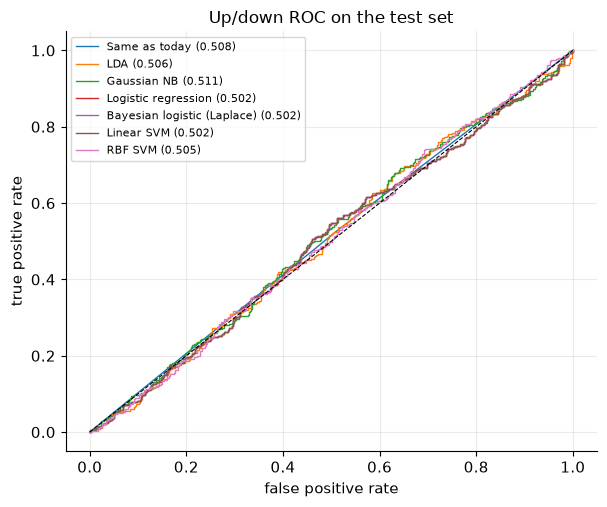

**Observations.** The majority baseline gets 0.5195. 1 of 6 models have higher accuracy, but **0 beat it significantly**. 0 models have an AUC outside the chance band [0.460, 0.540]. The Laplace fit converges in 3 Newton steps and matches scikit-learn to 4.8e-11. With H = ΦᵀRΦ + αI′, the smallest eigenvalue is 1100.153 (positive definite) and α = 1e+06 is where the CV curve goes flat: AUC depends only on the direction of w, which stops changing under heavy shrinkage, so stronger priors change nothing. The posterior variance of the activation is small (mean σ_a² = 9.30e-04), so the probit correction barely changes predictions (mean change 2.9e-06), and predictions stay near 0.5 (mean |p − 0.5| = 0.0158). The kernel identity holds to 4.5e-13 and the RBF Gram matrix is PSD up to round-off (min eigenvalue 7.3e-03).

In [20]:
_krng = np.random.default_rng(SEED)
_ii = _krng.choice(len(Xc), 300, replace=False); _A = Xc[_ii]
_B = Xc[_krng.choice(len(Xc), 300, replace=False)]
phi2 = lambda X: (X[:, :, None] * X[:, None, :]).reshape(len(X), -1)
kdirect = (np.sum(_A * _B, 1)) ** 2; kexp = np.sum(phi2(_A) * phi2(_B), 1)
kt_diff = np.max(np.abs(kdirect - kexp))
x2 = np.array([1.5, -0.5]); z2 = np.array([0.5, 2.0]); phi_small = lambda v: np.array([v[0] ** 2, np.sqrt(2) * v[0] * v[1], v[1] ** 2])
ex_lhs, ex_rhs = float(x2 @ z2) ** 2, float(phi_small(x2) @ phi_small(z2))
_gam = 1 / Xc.shape[1]
from sklearn.metrics.pairwise import rbf_kernel
K_ = rbf_kernel(_A, gamma=_gam); eK = np.linalg.eigvalsh(K_)
print(f"(xᵀz)² vs φ(x)ᵀφ(z) on 300 pairs in {Xc.shape[1]}-D (φ has {Xc.shape[1]**2} features): max diff {kt_diff:.2e}")
print(f"Worked 2-D example x = {x2.tolist()}, z = {z2.tolist()}: (xᵀz)² = {ex_lhs}, φ(x)ᵀφ(z) = {ex_rhs:.10f}; φ(x) = {np.round(phi_small(x2),6).tolist()}, φ(z) = {np.round(phi_small(z2),6).tolist()}")
print(f"RBF Gram matrix 300×300: symmetric = {np.allclose(K_, K_.T)}, min eigenvalue {eK.min():.3e}, max {eK.max():.3f} → PSD up to round-off: {bool(eK.min() > -1e-10)}")
assert kt_diff < 1e-8 and abs(ex_lhs - ex_rhs) < 1e-12 and eK.min() > -1e-10

gs_lsvm, lsvm_info = tune(lambda: LinearSVC(loss="hinge", dual=True, max_iter=100000, random_state=SEED), "C", list(np.logspace(-4, 1, 6)), Xc, yc, "roc_auc", max_ext=2)
clf_rec("linear_svm", "Linear SVM", gs_lsvm.predict(Xcte), gs_lsvm.decision_function(Xcte), float(gs_lsvm.best_score_))
print("Linear SVM C =", lsvm_info["best"], lsvm_info["extended"], "| at edge:", lsvm_info["at_edge"], np.round(lsvm_info["curve"]["score"], 4).tolist())
_rbf_grid = {"C": [0.01, 0.1, 1.0, 10.0], "gamma": [1e-4, 1e-3, 1e-2, 0.1]}
gs_rbf = GridSearchCV(SVC(kernel="rbf"), _rbf_grid, cv=tscv, scoring="roc_auc").fit(Xc, yc)
rbf_best = gs_rbf.best_params_; rbf_edge = {"C": rbf_best["C"] in (0.01, 10.0), "gamma": rbf_best["gamma"] in (1e-4, 0.1)}
print("RBF SVM best:", rbf_best, "| CV AUC", round(gs_rbf.best_score_, 4), "| at edge:", rbf_edge)
_rbf_table = pd.DataFrame(gs_rbf.cv_results_)[["param_C", "param_gamma", "mean_test_score"]].pivot(index="param_C", columns="param_gamma", values="mean_test_score").round(4); display(_rbf_table)
clf_rec("rbf_svm", "RBF SVM", gs_rbf.predict(Xcte), gs_rbf.decision_function(Xcte), float(gs_rbf.best_score_))
print(f"RBF support vectors: {gs_rbf.best_estimator_.n_support_.sum()} of {len(Xc)}")

clf_tab = pd.DataFrame(CLF).T.drop(columns=["key", "cm"]); display(clf_tab)
_m = clf_tab[clf_tab.kind == "model"]
n_beat_sig = int((_m.p_vs_majority.astype(float) < .05).sum()); n_auc_out = int((_m.auc_in_chance_band == False).sum())
R["u2_clf"] = dict(table=list(CLF.values()), maj_class=maj_class, maj_rate=maj_rate_test, p_up_train=yc.mean(), p_up_test=ycte.mean(), n1=n1, n0=n0, auc_low=.5 - auc_half, auc_high=.5 + auc_half, n_beat_sig=n_beat_sig, n_auc_outside=n_auc_out, n_models=len(_m), n_above_majority=int((_m.accuracy.astype(float) > maj_rate_test).sum()),
    lda=dict(diff=lda_diff, w0=_w0), logistic=dict(C=lr_info["best"], at_edge=lr_info["at_edge"], plateau=lr_info["plateau"], extended=lr_info["extended"]), laplace=R_lap,
    kernel=dict(diff=kt_diff, n_pairs=300, d=Xc.shape[1], phi_dim=Xc.shape[1] ** 2, x=x2, z=z2, phi_x=phi_small(x2), phi_z=phi_small(z2), lhs=ex_lhs, rhs=ex_rhs, xz=float(x2 @ z2), gram_n=300, gram_min_eig=eK.min(), gram_max_eig=eK.max(), gamma=_gam),
    linear_svm=dict(C=lsvm_info["best"], at_edge=lsvm_info["at_edge"], plateau=lsvm_info["plateau"], extended=lsvm_info["extended"]), rbf=dict(C=rbf_best["C"], gamma=rbf_best["gamma"], edge=rbf_edge, n_sv=gs_rbf.best_estimator_.n_support_.sum(), n_train=len(Xc), grid=_rbf_grid))
chart("u2_roc", dict(curves={k: dict(label=CLF[k]["model"], auc=CLF[k]["auc"], **ROC[k]) for k in ROC}, auc_low=.5 - auc_half, auc_high=.5 + auc_half))
fig, ax = plt.subplots(figsize=(6.2, 5.2))
for k, v in ROC.items(): ax.plot(v["fpr"], v["tpr"], lw=1, label=f"{CLF[k]['model']} ({CLF[k]['auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.set_title("Up/down ROC on the test set"); ax.legend(fontsize=8); plt.tight_layout(); savefig("u2_roc"); plt.show()
_edge_txt = "where the CV curve goes flat: AUC depends only on the direction of w, which stops changing under heavy shrinkage, so stronger priors change nothing" if alpha_plateau else "inside the grid"
obs(f"The majority baseline gets {maj_rate_test:.4f}. {R['u2_clf']['n_above_majority']} of {len(_m)} models have higher accuracy, but **{n_beat_sig} beat it significantly**. {n_auc_out} models have an AUC outside the chance band [{.5-auc_half:.3f}, {.5+auc_half:.3f}]. "
    f"The Laplace fit converges in {len(lap['log'])} Newton steps and matches scikit-learn to {lap_diff:.1e}. With H = ΦᵀRΦ + αI′, the smallest eigenvalue is {eigH.min():.3f} (positive definite) and α = {ALPHA:g} is {_edge_txt}. "
    f"The posterior variance of the activation is small (mean σ_a² = {s2_l.mean():.2e}), so the probit correction barely changes predictions (mean change {np.mean(np.abs(pm-pmap)):.1e}), and predictions stay near 0.5 (mean |p − 0.5| = {np.mean(np.abs(pm-.5)):.4f}). "
    f"The kernel identity holds to {kt_diff:.1e} and the RBF Gram matrix is PSD up to round-off (min eigenvalue {eK.min():.1e}).")

### Robustness check: TCS, HDFCBANK, INFY

The same pipeline, split date and **RELIANCE's hyperparameters** are applied without re-tuning. These stocks can have corporate actions inside the test window, so their prices are back-adjusted and RMSE is measured in adjusted INR. The ratio `RMSE / persistence RMSE` is what matters. A corporate-action day has no return, and the rows whose lags or target touch it drop out, which is why these stocks have fewer test rows than RELIANCE.

In [21]:
ROBUST = ["TCS", "HDFCBANK", "INFY"]
rob_rows = []
for tk in ROBUST:
    F_, RAW_, T_ = build_features(panel, tk)
    D_ = pd.concat([F_, RAW_, T_], axis=1).dropna(subset=ENG + RAWC + ["close_next", "r_next"])
    tr_, te_ = D_[D_.index < TEST_START], D_[D_.index >= TEST_START]
    sc_ = StandardScaler().fit(tr_[ENG]); X_, Xt_ = sc_.transform(tr_[ENG]), sc_.transform(te_[ENG])
    yr_, ct_, yt_, rt_ = tr_.r_next.values, te_.close_t.values, te_.close_next.values, te_.r_next.values
    pers = np.sqrt(np.mean((yt_ - ct_) ** 2))
    rg = Ridge(alpha=ridge_info["ridge_b_eng"]["best"]).fit(X_, yr_).predict(Xt_); rb = blr_evidence(X_, yr_); rbp = blr_predict(rb, Xt_)
    rmse_r = np.sqrt(np.mean((yt_ - ct_ * np.exp(rg)) ** 2)); rmse_b = np.sqrt(np.mean((yt_ - ct_ * np.exp(rbp[0])) ** 2))
    _lo, _hi = ct_ * np.exp(rbp[0] - z * np.sqrt(rbp[1])), ct_ * np.exp(rbp[0] + z * np.sqrt(rbp[1]))
    yc_, yct_ = tr_.y_dir.values.astype(int), te_.y_dir.values.astype(int)
    mr = float(np.mean(yct_ == int(yc_.mean() > .5)))
    lf = laplace_fit(X_, yc_.astype(float), ALPHA); plf = laplace_pred(Xt_, lf)[0]
    rs = SVC(kernel="rbf", **rbf_best).fit(X_, yc_); ls = LinearSVC(loss="hinge", dual=True, max_iter=100000, random_state=SEED, C=lsvm_info["best"]).fit(X_, yc_)
    lg = LogisticRegression(C=lr_info["best"], max_iter=5000).fit(X_, yc_)
    def _ac(pred): return float(np.mean(pred == yct_))
    rob_rows.append(dict(ticker=tk, n_train=len(tr_), n_test=len(te_), corp_actions_in_test=int(panel[(panel.Ticker == tk) & (panel.Date >= TEST_START)].ca.sum()), persistence_rmse=pers, ridge_rmse=rmse_r, ridge_ratio=rmse_r / pers, ridge_dm_p=dm_test(yt_ - ct_ * np.exp(rg), yt_ - ct_)[1], blr_rmse=rmse_b, blr_ratio=rmse_b / pers, blr_dm_p=dm_test(yt_ - ct_ * np.exp(rbp[0]), yt_ - ct_)[1], blr_coverage=float(np.mean((yt_ >= _lo) & (yt_ <= _hi))),
                         majority_acc=mr, logistic_acc=_ac(lg.predict(Xt_)), laplace_acc=_ac((plf > .5).astype(int)), linear_svm_acc=_ac(ls.predict(Xt_)), rbf_acc=_ac(rs.predict(Xt_)), logistic_auc=roc_auc_score(yct_, lg.decision_function(Xt_)), laplace_auc=roc_auc_score(yct_, plf), rbf_auc=roc_auc_score(yct_, rs.decision_function(Xt_)),
                         best_p_vs_majority=min(stats.binomtest(int(round(a * len(yct_))), len(yct_), mr, alternative="greater").pvalue for a in [_ac(lg.predict(Xt_)), _ac((plf > .5).astype(int)), _ac(ls.predict(Xt_)), _ac(rs.predict(Xt_))])))
rob2 = pd.DataFrame(rob_rows); display(rob2.round(4).T)
_sig = [f"{r['ticker']} Bayesian LR" for r in rob_rows if r["blr_dm_p"] < .05 and r["blr_ratio"] > 1] + [f"{r['ticker']} ridge" for r in rob_rows if r["ridge_dm_p"] < .05 and r["ridge_ratio"] > 1]
n_sig_better_rob = sum(1 for r in rob_rows if (r["blr_dm_p"] < .05 and r["blr_ratio"] < 1)) + sum(1 for r in rob_rows if (r["ridge_dm_p"] < .05 and r["ridge_ratio"] < 1))
assert n_sig_better_rob == 0
R["u2_robust"] = dict(dm_sig_label=", ".join(_sig) if _sig else "none", n_sig_better=n_sig_better_rob, rows=rob_rows, max_ratio_dev=max(abs(rob2.ridge_ratio - 1).max(), abs(rob2.blr_ratio - 1).max()), n_dm_sig=int(((rob2.ridge_dm_p < .05).sum() + (rob2.blr_dm_p < .05).sum())), min_p=rob2.best_p_vs_majority.min())
save_results()
obs(f"On the other three stocks, ridge and Bayesian LR stay within {100*R['u2_robust']['max_ratio_dev']:.2f}% of the persistence RMSE, with {R['u2_robust']['n_dm_sig']} significant Diebold–Mariano result(s) out of {2*len(rob2)}; the only one, {R['u2_robust']['dm_sig_label']}, is significantly worse than persistence, not better. The smallest p-value for any classifier against the majority rate is {rob2.best_p_vs_majority.min():.3f}. RELIANCE was not unusual: the conclusion carries over.")

,0,1,2
ticker,TCS,HDFCBANK,INFY
n_train,3244,4417,4399
n_test,816,816,816
corp_actions_in_test,1,1,1
persistence_rmse,37.741,19.3307,15.2642
ridge_rmse,37.7209,19.3505,15.2901
ridge_ratio,0.9995,1.001,1.0017
ridge_dm_p,0.8006,0.8288,0.3631
blr_rmse,37.9433,19.4528,15.3899
blr_ratio,1.0054,1.0063,1.0082


**Observations.** On the other three stocks, ridge and Bayesian LR stay within 0.82% of the persistence RMSE, with 1 significant Diebold–Mariano result(s) out of 6; the only one, INFY Bayesian LR, is significantly worse than persistence, not better. The smallest p-value for any classifier against the majority rate is 0.325. RELIANCE was not unusual: the conclusion carries over.

# UNIT 3
**Assigned title:** Clustering NIFTY-50 stocks by return–volatility behaviour using K-means, GMM & hierarchical clustering; PCA market factors

**Syllabus mapping:** K-means, mixtures of Gaussians, EM (alternative view), factor analysis, PCA & choosing latent dimensions, dissimilarity measures & cluster evaluation (silhouette, DB index), hierarchical clustering → stocks by return & volatility.

Everything here is unsupervised and describes all 49 stocks. With n = 49, **the results are descriptive**, not inferential: they summarise this sample and do not establish a stable grouping. Each stock's statistics use its own available history, so newer listings cover a different period, and the sample only contains companies that were NIFTY-50 members in 2021 (survivorship bias).

## Features

Per stock: annualised mean return, annualised volatility, beta against an equal-weighted market return, skew, excess kurtosis and maximum drawdown. All six are standardised. The plain 2-D return–volatility version is also fitted, because that is what the assigned title names.

In [22]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist, squareform

Wr = panel.pivot(index="Date", columns="Ticker", values="r")
mkt_ew = Wr.mean(axis=1)
_ind = meta.set_index("Symbol").Industry
rows = []
for tk in Wr.columns:
    r_ = Wr[tk].dropna(); adj = panel.loc[panel.Ticker == tk].set_index("Date").Adj
    m_ = mkt_ew.reindex(r_.index)
    rows.append(dict(ticker=tk, industry=_ind[tk], ann_return=r_.mean() * 252, ann_vol=r_.std(ddof=1) * np.sqrt(252), beta=np.cov(r_, m_)[0, 1] / m_.var(ddof=1), skew=stats.skew(r_), ex_kurt=stats.kurtosis(r_), max_dd=-(adj / adj.cummax() - 1).min(), n=len(r_), first=r_.index.min()))
SF = pd.DataFrame(rows).set_index("ticker")
FEAT6 = ["ann_return", "ann_vol", "beta", "skew", "ex_kurt", "max_dd"]; FEAT2 = ["ann_return", "ann_vol"]
X6 = StandardScaler().fit_transform(SF[FEAT6]); X2 = StandardScaler().fit_transform(SF[FEAT2])
display(SF[FEAT6 + ["n"]].round(3).head(8)); display(SF[FEAT6].describe().round(3).loc[["mean", "std", "min", "max"]])
print("Highest ann_vol:", SF.ann_vol.nlargest(3).round(3).to_dict(), "| highest beta:", SF.beta.nlargest(3).round(3).to_dict(), "| lowest beta:", SF.beta.nsmallest(3).round(3).to_dict())
SPACES = {"6d": X6, "2d": X2}

def relabel(lbl):
    """Sort cluster ids by mean volatility, so a cluster keeps its colour when the method or k changes."""
    o = pd.Series(SF.ann_vol.values).groupby(lbl).mean().sort_values().index
    return pd.Series(lbl).map({c: i for i, c in enumerate(o)}).values

,ann_return,ann_vol,beta,skew,ex_kurt,max_dd,n
ticker,,,,,,,
ADANIPORTS,0.102,0.427,1.176,0.025,5.646,0.803,3320
ASIANPAINT,0.244,0.272,0.492,0.019,5.325,0.449,5302
AXISBANK,0.233,0.451,1.342,-0.055,7.612,0.778,5304
BAJAJ-AUTO,0.201,0.308,0.851,-0.227,6.834,0.523,3200
BAJAJFINSV,0.242,0.403,1.068,-0.595,11.959,0.868,3200
BAJFINANCE,0.335,0.441,0.950,0.279,8.009,0.918,5233
BHARTIARTL,0.167,0.381,0.911,0.419,4.426,0.579,4772
BPCL,0.122,0.421,0.931,-0.136,5.226,0.630,5301


,ann_return,ann_vol,beta,skew,ex_kurt,max_dd
mean,0.153,0.380,0.992,0.008,6.400,0.729
std,0.083,0.066,0.260,0.274,2.264,0.143
min,-0.092,0.241,0.436,-0.776,3.212,0.324
max,0.335,0.516,1.515,0.546,12.692,0.960


Highest ann_vol: {'VEDL': 0.516, 'ZEEL': 0.512, 'INDUSINDBK': 0.489} | highest beta: {'JSWSTEEL': 1.515, 'INDUSINDBK': 1.466, 'TATASTEEL': 1.442} | lowest beta: {'BRITANNIA': 0.436, 'NESTLEIND': 0.488, 'ASIANPAINT': 0.492}


## Unit 3, Practice 1: K-means, GMM & hierarchical clustering

### K-means for k = 2..8

K-means minimises within-cluster squared distance. We show the **elbow** (inertia), **silhouette** (higher is better) and the **Davies–Bouldin index** (lower is better). To avoid a poor local optimum, each fit has 50 restarts.

,space,k,inertia,silhouette,db,min_size,max_size
0,6d,2,205.8428,0.2585,1.4271,21,28
1,6d,3,165.8684,0.2643,1.1889,6,23
2,6d,4,136.5759,0.2527,1.1562,6,22
3,6d,5,116.9863,0.2518,1.0986,3,21
4,6d,6,102.5311,0.2355,1.2143,3,13
5,6d,7,92.6779,0.2402,1.1858,2,13
6,6d,8,81.4802,0.2389,1.1859,2,12
7,2d,2,60.7083,0.3549,1.1181,22,27
8,2d,3,39.9142,0.3844,0.9197,11,21
9,2d,4,28.9285,0.4094,0.7485,3,19


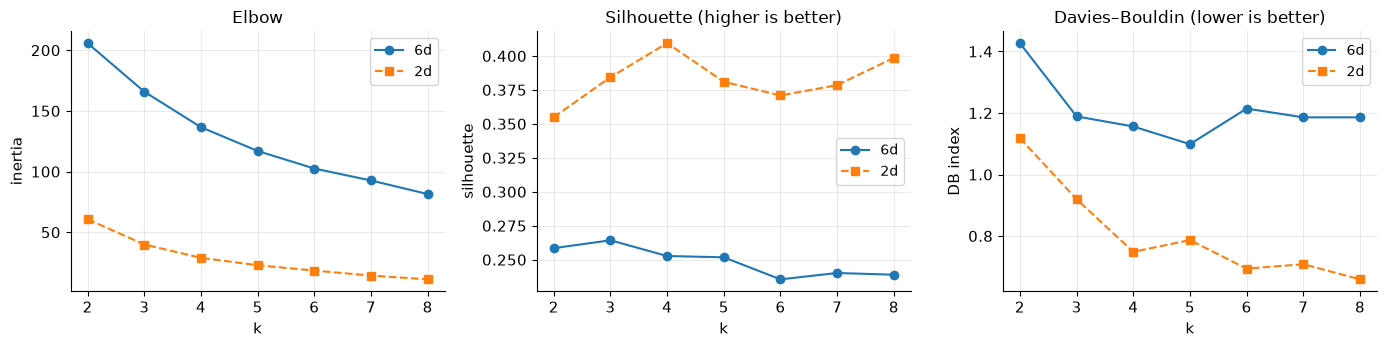

In [23]:
KS = list(range(2, 9))
km_rows = []; LABELS = {"kmeans": {}, "gmm": {}, "hier": {}}
for sp, X in SPACES.items():
    LABELS["kmeans"][sp] = {}
    for k in KS:
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
        l_ = relabel(km.labels_); LABELS["kmeans"][sp][k] = l_
        km_rows.append(dict(space=sp, k=k, inertia=km.inertia_, silhouette=silhouette_score(X, l_), db=davies_bouldin_score(X, l_), min_size=int(pd.Series(l_).value_counts().min()), max_size=int(pd.Series(l_).value_counts().max())))
km_df = pd.DataFrame(km_rows); display(km_df.round(4))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for sp, ls_ in [("6d", "-o"), ("2d", "--s")]:
    d = km_df[km_df.space == sp]
    ax[0].plot(d.k, d.inertia, ls_, label=sp); ax[1].plot(d.k, d.silhouette, ls_, label=sp); ax[2].plot(d.k, d.db, ls_, label=sp)
for a, t, y in zip(ax, ["Elbow", "Silhouette (higher is better)", "Davies–Bouldin (lower is better)"], ["inertia", "silhouette", "DB index"]): a.set_title(t); a.set_xlabel("k"); a.set_ylabel(y); a.legend()
plt.tight_layout(); savefig("u3_kmeans_k"); plt.show()

### Gaussian mixtures: model selection, EM from scratch and the alternative view

`p(x) = Σ_k π_k N(x | μ_k, Σ_k)`. Components and covariance type are chosen with BIC and AIC on the 6-D features. A full-covariance model has many parameters per component for 49 points, so BIC's penalty matters here.

**The alternative view of EM.** Introduce a latent assignment z_n. For any distribution q(Z):

`ln p(X|θ) = L(q, θ) + KL(q ‖ p(Z|X, θ))`, with `L(q, θ) = Σ_Z q(Z) ln[p(X, Z|θ)/q(Z)]`.

KL ≥ 0, so L is a lower bound on the log-likelihood. The **E-step** sets q to the posterior (the responsibilities γ_nk), which makes KL = 0 so the bound touches the log-likelihood. The **M-step** maximises L over θ. Since the bound rises and then touches, ln p(X|θ) can never fall.

**K-means as the hard-assignment limit.** Fix Σ_k = εI and equal π_k. As ε → 0 each responsibility goes to 0 or 1, and the M-step mean is then the K-means centroid.

In [24]:
K_HARD = 3
COV_TYPES = ["spherical", "diag", "tied", "full"]
gm_rows = []
for sp, X in SPACES.items():
    for ct in COV_TYPES:
        for k in range(1, 9):
            g = GaussianMixture(n_components=k, covariance_type=ct, n_init=20, reg_covar=1e-3, random_state=SEED, max_iter=1000).fit(X)
            gm_rows.append(dict(space=sp, cov=ct, k=k, bic=g.bic(X), aic=g.aic(X), ll=g.score(X) * len(X), n_params=g._n_parameters()))
gm_df = pd.DataFrame(gm_rows)
_g6 = gm_df[gm_df.space == "6d"]; _g2 = gm_df[gm_df.space == "2d"]
best_bic = _g6.loc[_g6.bic.idxmin()]; best_aic = _g6.loc[_g6.aic.idxmin()]; best_bic2 = _g2.loc[_g2.bic.idxmin()]; best_aic2 = _g2.loc[_g2.aic.idxmin()]
display(_g6.pivot(index="k", columns="cov", values="bic").round(1)); display(_g6.pivot(index="k", columns="cov", values="aic").round(1))
print("6-D: BIC selects", best_bic[["cov", "k", "bic", "n_params"]].to_dict(), "| AIC selects", best_aic[["cov", "k", "aic", "n_params"]].to_dict())
print("2-D: BIC selects", best_bic2[["cov", "k", "bic"]].to_dict(), "| AIC selects", best_aic2[["cov", "k", "aic"]].to_dict())

cov,diag,full,spherical,tied
k,,,,
1,881.0,796.9,861.6,796.9
2,848.8,818.0,843.6,797.2
3,847.1,873.4,841.4,797.0
4,873.4,906.5,838.6,812.2
5,876.6,951.7,835.9,829.0
6,898.0,964.8,820.6,848.8
7,904.5,997.7,835.8,851.7
8,934.6,1031.1,843.3,868.3


cov,diag,full,spherical,tied
k,,,,
1,858.3,745.8,848.3,745.8
2,801.5,713.9,815.2,732.9
3,775.2,716.4,797.9,719.5
4,776.9,696.5,779.9,721.3
5,755.5,688.7,762.1,725.0
6,752.4,648.8,731.7,731.5
7,734.2,628.8,731.8,721.2
8,739.7,609.2,724.1,724.5


6-D: BIC selects {'cov': 'tied', 'k': 1, 'bic': 796.8615535019479, 'n_params': 27} | AIC selects {'cov': 'full', 'k': 8, 'aic': 609.2463318130999, 'n_params': 223}
2-D: BIC selects {'cov': 'spherical', 'k': 1, 'bic': 289.78746233718783} | AIC selects {'cov': 'diag', 'k': 5, 'aic': 268.8149650070162}


EM from scratch (tied, K = 2): 396 iterations, log-lik -348.9330 → -341.8091; monotone = True; smallest step 9.90e-11; max |ln p − L(q,θ)| after E-step 1.71e-13
sklearn log-lik -341.809057, difference 9.51e-08; max |μ_scratch − μ_sklearn| = 3.11e-07; mixture weights [0.407, 0.593]


,eps,mean_max_resp,ari_vs_kmeans,centre_gap
0,2.0000,0.4928,0.6365,0.5406
1,1.0000,0.7994,0.7849,0.4598
2,0.5000,0.9266,0.7454,0.4337
3,0.2000,0.9845,0.7103,0.4852
4,0.1000,0.9980,0.7103,0.5085
5,0.0500,0.9992,1.0000,0.0057
6,0.0100,1.0000,1.0000,0.0000
7,0.0010,1.0000,1.0000,0.0000
8,0.0001,1.0000,1.0000,0.0000


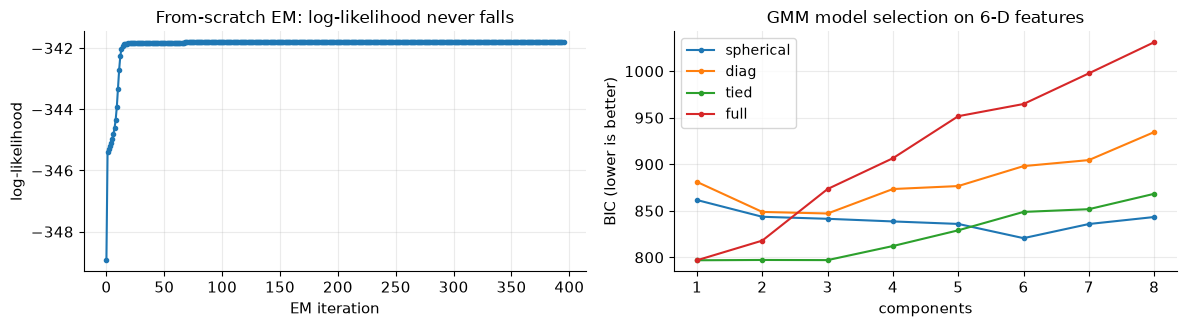

In [25]:
def em_gmm(X, pi, mu, cov, cov_type, reg=1e-3, max_iter=2000, tol=1e-10):
    """EM for a Gaussian mixture. cov is per-component (K, D, D) for every type, so one E-step serves all four."""
    N, D = X.shape; K = len(pi); hist = []; prev = -np.inf
    for it in range(max_iter):
        # E-step: responsibilities in log space
        lp = np.zeros((N, K))
        for k in range(K):
            Ld = np.linalg.cholesky(cov[k]); dev = linalg.solve_triangular(Ld, (X - mu[k]).T, lower=True).T
            lp[:, k] = np.log(pi[k]) - .5 * D * np.log(2 * np.pi) - np.log(np.diag(Ld)).sum() - .5 * (dev ** 2).sum(1)
        lmax = lp.max(1, keepdims=True); ll_n = lmax[:, 0] + np.log(np.exp(lp - lmax).sum(1))
        resp = np.exp(lp - ll_n[:, None]); ll = ll_n.sum()
        # lower bound with q = responsibilities equals ln p(X|θ), the check that KL = 0 after the E-step
        _safe = np.where(resp > 0, resp, 1.0)
        bound = (resp * lp).sum() - (resp * np.log(_safe)).sum()
        hist.append(dict(it=it, ll=ll, bound=bound, gap=ll - bound))
        if ll - prev < tol and it > 0: break
        prev = ll
        # M-step
        Nk = resp.sum(0) + 10 * np.finfo(float).eps
        pi = Nk / N; mu = (resp.T @ X) / Nk[:, None]
        full = np.stack([((X - mu[k]).T * resp[:, k]) @ (X - mu[k]) / Nk[k] for k in range(K)])
        if cov_type == "full": cov = full + reg * np.eye(D)
        elif cov_type == "tied":
            t_ = (X.T @ X - (mu.T * Nk) @ mu) / N + reg * np.eye(D); cov = np.stack([t_] * K)
        elif cov_type == "diag":
            cov = np.stack([np.diag(np.diag(full[k]) + reg) for k in range(K)])
        else:
            cov = np.stack([(np.trace(full[k]) / D + reg) * np.eye(D) for k in range(K)])
    return dict(pi=pi, mu=mu, cov=cov, resp=resp, ll=ll, hist=hist)

def init_for(X, k, ct, seed):
    _km = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(X); lb = _km.labels_
    pi0 = np.bincount(lb, minlength=k) / len(X); mu0 = _km.cluster_centers_; D = X.shape[1]
    base = np.cov(X.T) + 1e-3 * np.eye(D)
    if ct == "full": cov0 = np.stack([base] * k); prec = np.stack([np.linalg.inv(base)] * k)
    elif ct == "tied": cov0 = np.stack([base] * k); prec = np.linalg.inv(base)
    elif ct == "diag": cov0 = np.stack([np.diag(np.diag(base))] * k); prec = np.stack([1 / np.diag(base)] * k)
    else:
        v = np.trace(base) / D; cov0 = np.stack([v * np.eye(D)] * k); prec = np.full(k, 1 / v)
    return pi0, mu0, cov0, prec

G_K, G_CT = int(best_bic.k), best_bic["cov"]
em_k = max(G_K, 2)     # one component has nothing to demonstrate, so the EM check always uses at least two
_pi0, _mu0, _cov0, _prec = init_for(X6, em_k, G_CT, SEED)
em = em_gmm(X6, _pi0, _mu0, _cov0, G_CT)
_sk = GaussianMixture(n_components=em_k, covariance_type=G_CT, reg_covar=1e-3, weights_init=_pi0, means_init=_mu0, precisions_init=_prec, n_init=1, max_iter=5000, tol=1e-10, random_state=SEED).fit(X6)
ll_h = np.array([h["ll"] for h in em["hist"]]); gap = np.array([h["gap"] for h in em["hist"]])
dll = np.diff(ll_h); monotone = bool((dll >= -1e-9).all())
sk_ll = _sk.score(X6) * len(X6); _ord = linalg.norm(em["mu"][:, None] - _sk.means_[None], axis=2).argmin(1)
em_mu_diff = np.max(np.abs(em["mu"] - _sk.means_[_ord]))
print(f"EM from scratch ({G_CT}, K = {em_k}): {len(ll_h)} iterations, log-lik {ll_h[0]:.4f} → {ll_h[-1]:.4f}; monotone = {monotone}; smallest step {dll.min():.2e}; max |ln p − L(q,θ)| after E-step {np.abs(gap).max():.2e}")
print(f"sklearn log-lik {sk_ll:.6f}, difference {abs(sk_ll-ll_h[-1]):.2e}; max |μ_scratch − μ_sklearn| = {em_mu_diff:.2e}; mixture weights {np.round(em['pi'],3).tolist()}")
assert monotone and abs(sk_ll - ll_h[-1]) < 1e-2

# K-means as the hard limit: fixed εI and equal weights, with the same initial centres as a plain Lloyd K-means
_start = KMeans(n_clusters=K_HARD, init="random", n_init=1, random_state=SEED).fit(X6).cluster_centers_
_km_hard = KMeans(n_clusters=K_HARD, init=_start, n_init=1, tol=0, algorithm="lloyd", max_iter=1000).fit(X6)
def soft_kmeans(X, mu, eps, iters=5000):
    for _ in range(iters):
        d2 = ((X[:, None] - mu[None]) ** 2).sum(2); lp = -d2 / (2 * eps); lp -= lp.max(1, keepdims=True); r = np.exp(lp); r /= r.sum(1, keepdims=True)
        new = (r.T @ X) / r.sum(0)[:, None]
        if np.abs(new - mu).max() < 1e-12: mu = new; break
        mu = new
    return r, mu
hard_rows = []
for eps in [2.0, 1.0, 0.5, 0.2, 0.1, 0.05, 0.01, 0.001, 0.0001]:
    r_, mu_ = soft_kmeans(X6, _start.copy(), eps)
    _o = linalg.norm(mu_[:, None] - _km_hard.cluster_centers_[None], axis=2).argmin(1)
    hard_rows.append(dict(eps=eps, mean_max_resp=r_.max(1).mean(), ari_vs_kmeans=adjusted_rand_score(_km_hard.labels_, r_.argmax(1)), centre_gap=np.max(np.abs(mu_ - _km_hard.cluster_centers_[_o]))))
hard = pd.DataFrame(hard_rows); display(hard.round(4))
assert hard_rows[-1]["ari_vs_kmeans"] == 1.0 and hard_rows[-1]["centre_gap"] < 1e-9

# labels for the site's method and k controls, using the BIC-selected covariance family
for sp, X in SPACES.items():
    LABELS["gmm"][sp] = {}
    ct = (best_bic if sp == "6d" else best_bic2)["cov"]
    for k in KS:
        LABELS["gmm"][sp][k] = relabel(GaussianMixture(n_components=k, covariance_type=ct, n_init=20, reg_covar=1e-3, random_state=SEED, max_iter=1000).fit_predict(X))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(ll_h, "-o", ms=3); ax[0].set_xlabel("EM iteration"); ax[0].set_ylabel("log-likelihood"); ax[0].set_title("From-scratch EM: log-likelihood never falls")
for ct in COV_TYPES: d = _g6[_g6["cov"] == ct]; ax[1].plot(d.k, d.bic, "-o", ms=3, label=ct)
ax[1].set_xlabel("components"); ax[1].set_ylabel("BIC (lower is better)"); ax[1].set_title("GMM model selection on 6-D features"); ax[1].legend(); plt.tight_layout(); savefig("u3_gmm_em"); plt.show()

### Hierarchical clustering and dissimilarity measures

Agglomerative clustering with ward, complete and average linkage. The **cophenetic correlation** measures how faithfully a dendrogram preserves the original distances.

Two dissimilarities are compared:

- **Euclidean distance on standardised features**, which groups stocks by how they behave on summary statistics.
- **Correlation distance** `d = √(2(1−ρ))` between return series, which groups stocks that move together on the same days. Ward's criterion assumes Euclidean geometry. This d is proportional to the Euclidean distance between standardised series on common days, so the combination is acceptable, though only approximately here because stocks cover different periods.

,distance,linkage,cophenetic
0,euclidean,ward,0.4884
1,euclidean,complete,0.5684
2,euclidean,average,0.6719
3,correlation,ward,0.6120
4,correlation,complete,0.7018
5,correlation,average,0.8666


method,gmm,hier,kmeans
k,,,
2,0.225,0.195,0.258
3,0.159,0.195,0.264
4,0.113,0.234,0.253
5,0.147,0.204,0.252
6,0.167,0.205,0.236
7,0.069,0.215,0.240
8,0.199,0.231,0.239


method,gmm,hier,kmeans
k,,,
2,1.532,1.441,1.427
3,1.687,1.432,1.189
4,1.745,1.261,1.156
5,1.442,1.314,1.099
6,1.545,1.327,1.214
7,1.666,1.272,1.186
8,1.158,1.117,1.186


method,gmm,hier,kmeans
k,,,
2,0.351,0.385,0.355
3,0.329,0.357,0.384
4,0.324,0.399,0.409
5,0.340,0.377,0.381
6,0.325,0.385,0.371
7,0.297,0.381,0.379
8,0.387,0.386,0.399


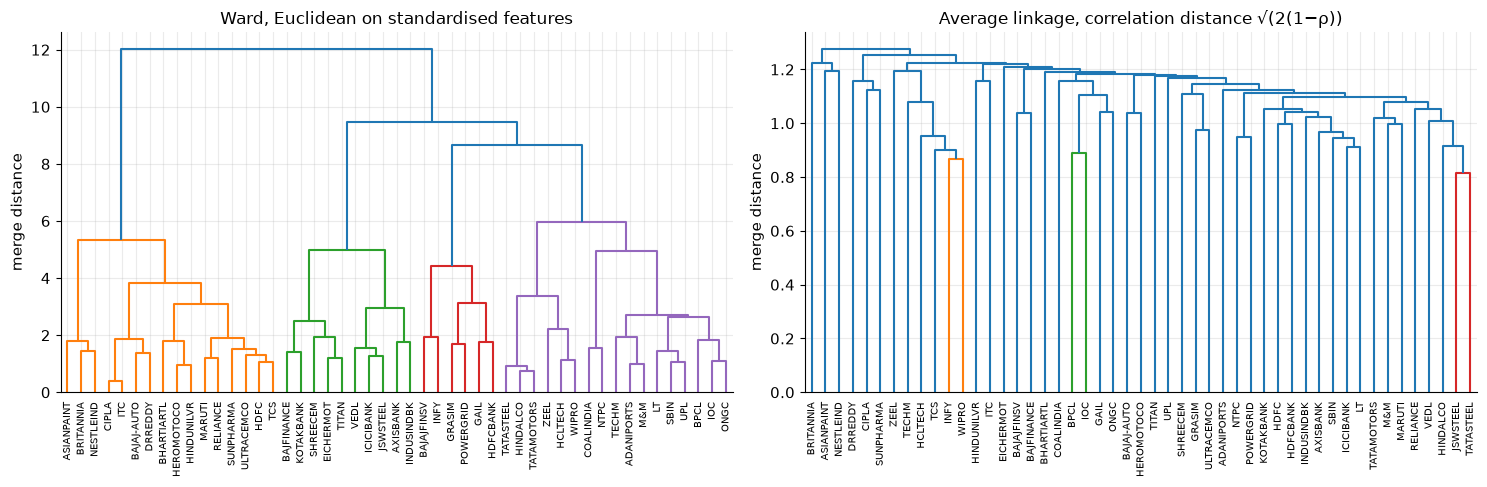

In [26]:
Rho = Wr.corr(min_periods=250)
assert Rho.notna().all().all() and list(Rho.columns) == list(SF.index)
Dcorr = np.sqrt(np.clip(2 * (1 - Rho.values), 0, None)); np.fill_diagonal(Dcorr, 0); dcorr_v = squareform(Dcorr, checks=False)
Deu = pdist(X6)
hier_rows = []; Z_all = {}
for dname, dv, Xeval in [("euclidean", Deu, X6), ("correlation", dcorr_v, None)]:
    for meth in ["ward", "complete", "average"]:
        Z_ = linkage(dv, method=meth); c_, _ = cophenet(Z_, dv); Z_all[(dname, meth)] = Z_
        hier_rows.append(dict(distance=dname, linkage=meth, cophenetic=c_))
hier = pd.DataFrame(hier_rows); display(hier.round(4))
Z2 = linkage(X2, method="ward")
LABELS["hier"]["6d"] = {k: relabel(fcluster(Z_all[("euclidean", "ward")], k, "maxclust") - 1) for k in KS}
LABELS["hier"]["2d"] = {k: relabel(fcluster(Z2, k, "maxclust") - 1) for k in KS}
all_metrics = []
for meth in ["kmeans", "gmm", "hier"]:
    for sp, X in SPACES.items():
        for k in KS:
            l_ = LABELS[meth][sp][k]; nc = len(np.unique(l_))
            all_metrics.append(dict(method=meth, space=sp, k=k, n_clusters=nc, silhouette=silhouette_score(X, l_) if nc > 1 else None, db=davies_bouldin_score(X, l_) if nc > 1 else None, ari_industry=adjusted_rand_score(SF.industry, l_), min_size=int(pd.Series(l_).value_counts().min())))
met = pd.DataFrame(all_metrics)
display(met[met.space == "6d"].pivot(index="k", columns="method", values="silhouette").round(3)); display(met[met.space == "6d"].pivot(index="k", columns="method", values="db").round(3)); display(met[met.space == "2d"].pivot(index="k", columns="method", values="silhouette").round(3))
fig, ax = plt.subplots(1, 2, figsize=(15, 5)); _names = list(SF.index)
dendrogram(Z_all[("euclidean", "ward")], labels=_names, ax=ax[0], leaf_font_size=7); ax[0].set_title("Ward, Euclidean on standardised features"); ax[0].set_ylabel("merge distance")
dendrogram(Z_all[("correlation", "average")], labels=_names, ax=ax[1], leaf_font_size=7); ax[1].set_title("Average linkage, correlation distance √(2(1−ρ))"); ax[1].set_ylabel("merge distance")
plt.tight_layout(); savefig("u3_dendrograms"); plt.show()

### Choosing k and evaluating against industry

k is chosen on internal criteria only. The silhouette maximum is the first candidate, but a split that isolates one or two extreme stocks is not useful as a grouping, so we also require every cluster to contain at least 3 stocks. Industry is held back as an external check: the adjusted Rand index (ARI) is 0 for chance agreement and 1 for perfect agreement. A permutation test gives its null range.

In [27]:
_km6 = km_df[km_df.space == "6d"].set_index("k")
sil_best_raw = int(_km6.silhouette.idxmax()); _ok6 = _km6[_km6.min_size >= 3]
K_CHOSEN = int(_ok6.silhouette.idxmax())
_km2 = km_df[km_df.space == "2d"].set_index("k"); _ok2 = _km2[_km2.min_size >= 3]; K_CHOSEN_2D = int(_ok2.silhouette.idxmax())
_inert = _km6.inertia; _drops = (-_inert.diff()).dropna() / _inert.iloc[0]
print(f"6-D: silhouette maximum at k = {sil_best_raw} (smallest cluster {_km6.min_size[sil_best_raw]}); with ≥3 stocks per cluster, k = {K_CHOSEN}, silhouette {_km6.silhouette[K_CHOSEN]:.4f}, DB {_km6.db[K_CHOSEN]:.4f}")
print(f"2-D: silhouette-based k = {K_CHOSEN_2D}, silhouette {_km2.silhouette[K_CHOSEN_2D]:.4f}, DB {_km2.db[K_CHOSEN_2D]:.4f}")
print("Inertia fall as a share of the k = 2 inertia, per extra cluster:", _drops.round(3).to_dict())
L_km, L_gm, L_hc = LABELS["kmeans"]["6d"][K_CHOSEN], LABELS["gmm"]["6d"][K_CHOSEN], LABELS["hier"]["6d"][K_CHOSEN]
agree = dict(km_gmm=adjusted_rand_score(L_km, L_gm), km_hier=adjusted_rand_score(L_km, L_hc), gmm_hier=adjusted_rand_score(L_gm, L_hc))
print("Agreement at the chosen k (ARI):", {k: round(v, 3) for k, v in agree.items()})
_prng = np.random.default_rng(SEED); _ind_vals = SF.industry.values
_null = np.array([adjusted_rand_score(_prng.permutation(_ind_vals), L_km) for _ in range(5000)])
ari_km = adjusted_rand_score(_ind_vals, L_km); ari_p = float(((_null >= ari_km).sum() + 1) / (len(_null) + 1))
_lab_corr_av = fcluster(Z_all[("correlation", "average")], K_CHOSEN, "maxclust"); _lab_corr_w = fcluster(Z_all[("correlation", "ward")], K_CHOSEN, "maxclust")
_null2 = np.array([adjusted_rand_score(_prng.permutation(_ind_vals), _lab_corr_w) for _ in range(5000)])
ari_cw = adjusted_rand_score(_ind_vals, _lab_corr_w); ari_cw_p = float(((_null2 >= ari_cw).sum() + 1) / (len(_null2) + 1))
ari_table = dict(km_6d=ari_km, gmm_6d=adjusted_rand_score(_ind_vals, L_gm), hier_6d=adjusted_rand_score(_ind_vals, L_hc), km_2d=adjusted_rand_score(_ind_vals, LABELS["kmeans"]["2d"][K_CHOSEN_2D]), corr_ward=ari_cw, corr_average=adjusted_rand_score(_ind_vals, _lab_corr_av))
sil_corr_w = silhouette_score(Dcorr, _lab_corr_w, metric="precomputed"); sil_corr_a = silhouette_score(Dcorr, _lab_corr_av, metric="precomputed"); sil_eu_on_corr = silhouette_score(Dcorr, L_hc, metric="precomputed")
print(f"ARI with Industry: {({k: round(v,3) for k,v in ari_table.items()})}; permutation p: features {ari_p:.4f}, correlation-ward {ari_cw_p:.4f}; ARI between Euclidean-ward and correlation-ward: {adjusted_rand_score(L_hc, _lab_corr_w):.3f}")
print(f"Silhouette on correlation distance: correlation-ward {sil_corr_w:.3f}, correlation-average {sil_corr_a:.3f}, feature-based clusters {sil_eu_on_corr:.3f}")
cont = pd.crosstab(SF.industry, pd.Series(L_km, index=SF.index, name="cluster")); display(cont)
cont_corr = pd.crosstab(SF.industry, pd.Series(_lab_corr_w, index=SF.index, name="corr_cluster")); display(cont_corr)
_summ = SF.assign(cluster=L_km).groupby("cluster")[FEAT6].mean().round(3); _summ["n"] = pd.Series(L_km).value_counts().sort_index(); display(_summ)
_members = {int(c): list(SF.index[L_km == c]) for c in np.unique(L_km)}
_corr_members = {int(c): list(SF.index[_lab_corr_w == c]) for c in np.unique(_lab_corr_w)}
print("Feature clusters:", _members); print("Correlation-distance clusters:", _corr_members)

6-D: silhouette maximum at k = 3 (smallest cluster 6); with ≥3 stocks per cluster, k = 3, silhouette 0.2643, DB 1.1889
2-D: silhouette-based k = 4, silhouette 0.4094, DB 0.7485
Inertia fall as a share of the k = 2 inertia, per extra cluster: {3: 0.194, 4: 0.142, 5: 0.095, 6: 0.07, 7: 0.048, 8: 0.054}
Agreement at the chosen k (ARI): {'km_gmm': 0.302, 'km_hier': 0.368, 'gmm_hier': 0.223}
ARI with Industry: {'km_6d': 0.029, 'gmm_6d': 0.041, 'hier_6d': 0.066, 'km_2d': 0.078, 'corr_ward': 0.134, 'corr_average': 0.039}; permutation p: features 0.1016, correlation-ward 0.0002; ARI between Euclidean-ward and correlation-ward: 0.110
Silhouette on correlation distance: correlation-ward 0.058, correlation-average 0.062, feature-based clusters -0.002


cluster,0,1,2
industry,,,
AUTOMOBILE,3,0,3
CEMENT & CEMENT PRODUCTS,1,1,1
CONSTRUCTION,0,0,1
CONSUMER GOODS,5,0,1
ENERGY,4,2,1
FERTILISERS & PESTICIDES,0,0,1
FINANCIAL SERVICES,1,2,6
IT,1,1,3
MEDIA & ENTERTAINMENT,0,0,1


corr_cluster,1,2,3
industry,,,
AUTOMOBILE,0,0,6
CEMENT & CEMENT PRODUCTS,0,0,3
CONSTRUCTION,0,0,1
CONSUMER GOODS,0,5,1
ENERGY,0,0,7
FERTILISERS & PESTICIDES,0,0,1
FINANCIAL SERVICES,0,0,9
IT,5,0,0
MEDIA & ENTERTAINMENT,0,0,1


,ann_return,ann_vol,beta,skew,ex_kurt,max_dd,n
cluster,,,,,,,
0,0.140,0.325,0.775,0.049,5.356,0.612,20
1,0.146,0.354,0.941,-0.344,11.026,0.717,6
2,0.166,0.434,1.195,0.063,6.101,0.834,23


Feature clusters: {0: ['ASIANPAINT', 'BAJAJ-AUTO', 'BHARTIARTL', 'BPCL', 'BRITANNIA', 'CIPLA', 'COALINDIA', 'DRREDDY', 'HDFC', 'HEROMOTOCO', 'HINDUNILVR', 'IOC', 'ITC', 'MARUTI', 'NESTLEIND', 'NTPC', 'RELIANCE', 'SUNPHARMA', 'TCS', 'ULTRACEMCO'], 1: ['BAJAJFINSV', 'GAIL', 'GRASIM', 'HDFCBANK', 'INFY', 'POWERGRID'], 2: ['ADANIPORTS', 'AXISBANK', 'BAJFINANCE', 'EICHERMOT', 'HCLTECH', 'HINDALCO', 'ICICIBANK', 'INDUSINDBK', 'JSWSTEEL', 'KOTAKBANK', 'LT', 'M&M', 'ONGC', 'SBIN', 'SHREECEM', 'TATAMOTORS', 'TATASTEEL', 'TECHM', 'TITAN', 'UPL', 'VEDL', 'WIPRO', 'ZEEL']}
Correlation-distance clusters: {1: ['HCLTECH', 'INFY', 'TCS', 'TECHM', 'WIPRO'], 2: ['ASIANPAINT', 'BRITANNIA', 'CIPLA', 'DRREDDY', 'HINDUNILVR', 'ITC', 'NESTLEIND', 'SUNPHARMA'], 3: ['ADANIPORTS', 'AXISBANK', 'BAJAJ-AUTO', 'BAJAJFINSV', 'BAJFINANCE', 'BHARTIARTL', 'BPCL', 'COALINDIA', 'EICHERMOT', 'GAIL', 'GRASIM', 'HDFC', 'HDFCBANK', 'HEROMOTOCO', 'HINDALCO', 'ICICIBANK', 'INDUSINDBK', 'IOC', 'JSWSTEEL', 'KOTAKBANK', 'LT', 'M&

## Unit 3, Practice 2: PCA

PCA is run on the standardised stocks × days return matrix. It needs a complete matrix, so the window starts at the latest first-return date among the stocks kept, and days with any missing return (a corporate-action day for one stock) are dropped. This is descriptive, so there is no train/test split.

**Rules for choosing latent dimensions:** cumulative variance ≥ 80%; Kaiser (eigenvalue > 1 on standardised data); parallel analysis (eigenvalue above the 95th percentile of those from data with each column shuffled independently); broken stick.

Latest listings: {'ADANIPORTS': datetime.date(2007, 11, 28), 'BAJAJFINSV': datetime.date(2008, 5, 27), 'BAJAJ-AUTO': datetime.date(2008, 5, 27), 'NESTLEIND': datetime.date(2010, 1, 11), 'COALINDIA': datetime.date(2010, 11, 5)}
Window 2010-11-05 → 2021-04-30: 2597 days in range, 2557 after dropping days with any missing return; 49 stocks kept.


PC1 0.3018, PC2 0.0500, PC3 0.0356; ≥80% needs 27; Kaiser 8; parallel analysis 6; broken stick 1
PC1 loadings: all same sign = True, min 0.314 (DRREDDY), max 0.726 (ICICIBANK). Corr(PC1 score, equal-weighted index) = 0.99837


,PC2,PC3,n
industry,,,
CONSTRUCTION,-0.151,-0.029,1
FINANCIAL SERVICES,-0.122,-0.191,9
ENERGY,-0.101,0.248,7
METALS,-0.075,0.268,5
SERVICES,-0.052,0.044,1
CEMENT & CEMENT PRODUCTS,-0.045,-0.067,3
AUTOMOBILE,-0.029,-0.103,6
TELECOM,-0.019,-0.004,1
MEDIA & ENTERTAINMENT,0.007,0.024,1


PC2 highest: {'TCS': 0.641, 'HCLTECH': 0.632, 'INFY': 0.618, 'WIPRO': 0.602, 'TECHM': 0.51} | lowest: {'IOC': -0.227, 'SBIN': -0.223, 'BPCL': -0.204, 'AXISBANK': -0.161, 'ICICIBANK': -0.151}
PC3 highest: {'ONGC': 0.36, 'GAIL': 0.327, 'COALINDIA': 0.325, 'VEDL': 0.305, 'IOC': 0.299} | lowest: {'KOTAKBANK': -0.29, 'HDFCBANK': -0.285, 'BAJFINANCE': -0.271, 'INDUSINDBK': -0.244, 'HDFC': -0.242}
Share of loading variance explained by industry (η²): {'PC1': np.float64(0.788), 'PC2': np.float64(0.931), 'PC3': np.float64(0.833)}


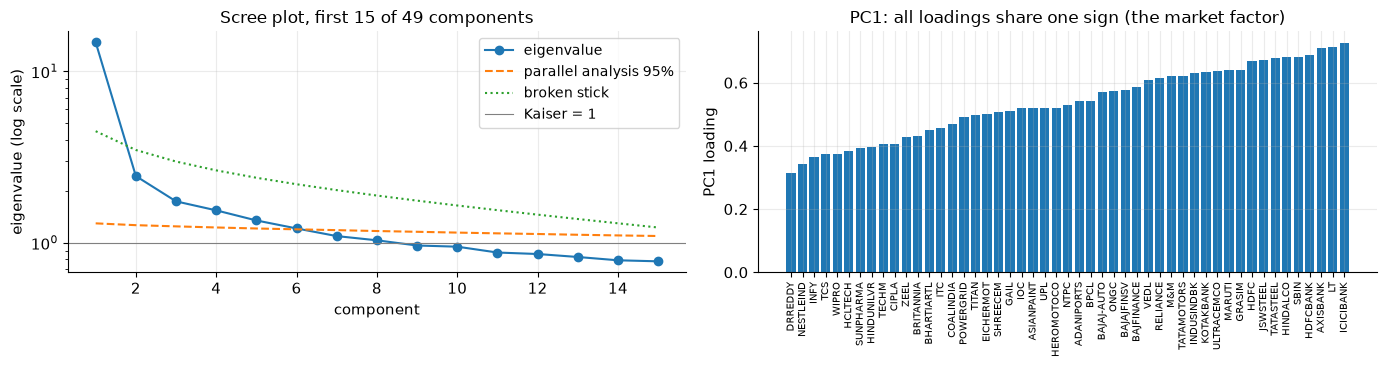

In [28]:
_first = Wr.apply(lambda s: s.first_valid_index())
print("Latest listings:", _first.sort_values().tail(5).dt.date.to_dict())
PCA_START = _first.max()
Wp_ = Wr.loc[PCA_START:]
Wc = Wp_.dropna()
print(f"Window {Wc.index.min().date()} → {Wc.index.max().date()}: {Wp_.shape[0]} days in range, {Wc.shape[0]} after dropping days with any missing return; {Wc.shape[1]} stocks kept.")
Xp = StandardScaler().fit_transform(Wc.values)
pca = PCA().fit(Xp)
ev = pca.explained_variance_; evr = pca.explained_variance_ratio_; cum = np.cumsum(evr); P = len(ev); Np = Xp.shape[0]
n80 = int(np.argmax(cum >= .8) + 1); n_kaiser = int((ev > 1).sum())
_rng2 = np.random.default_rng(SEED)
par = []
for _ in range(200):
    Xs = np.column_stack([_rng2.permutation(Xp[:, j]) for j in range(P)])
    par.append(np.linalg.svd(Xs, compute_uv=False) ** 2 / (Np - 1))
par = np.array(par); par95 = np.percentile(par, 95, axis=0); n_par = int(np.argmax(ev <= par95)) if (ev <= par95).any() else P
bs = np.array([np.sum(1 / np.arange(k, P + 1)) / P for k in range(1, P + 1)]); n_bs = int(np.argmax(evr <= bs)) if (evr <= bs).any() else P
print(f"PC1 {evr[0]:.4f}, PC2 {evr[1]:.4f}, PC3 {evr[2]:.4f}; ≥80% needs {n80}; Kaiser {n_kaiser}; parallel analysis {n_par}; broken stick {n_bs}")
K_F = n_par
load = pca.components_.T * np.sqrt(ev)     # correlations between stocks and PCs
_flip = np.sign(load[:, 0].sum()); load[:, 0] *= _flip
scores = pca.transform(Xp); scores[:, 0] *= _flip
ew_c = Wc.mean(axis=1).values
pc1_corr = np.corrcoef(scores[:, 0], ew_c)[0, 1]; pc1_all_pos = bool((load[:, 0] > 0).all())
print(f"PC1 loadings: all same sign = {pc1_all_pos}, min {load[:,0].min():.3f} ({Wc.columns[load[:,0].argmin()]}), max {load[:,0].max():.3f} ({Wc.columns[load[:,0].argmax()]}). Corr(PC1 score, equal-weighted index) = {pc1_corr:.5f}")
_lt = pd.DataFrame(load[:, :max(K_F, 3)], index=Wc.columns, columns=[f"PC{i+1}" for i in range(max(K_F, 3))]); _lt["industry"] = _ind[_lt.index].values
pc_ind = _lt.groupby("industry")[["PC2", "PC3"]].mean().round(3); pc_ind["n"] = _lt.groupby("industry").size()
display(pc_ind.sort_values("PC2"))
for pc in ["PC2", "PC3"]:
    print(pc, "highest:", _lt[pc].nlargest(5).round(3).to_dict(), "| lowest:", _lt[pc].nsmallest(5).round(3).to_dict())
# Between-industry share of each PC's squared loadings (eta²), restricted to industries with ≥2 stocks in the window
_multi = _lt[_lt.groupby("industry").PC1.transform("size") >= 2]
def eta2(col): return 1 - ((_multi[col] - _multi.groupby("industry")[col].transform("mean")) ** 2).sum() / ((_multi[col] - _multi[col].mean()) ** 2).sum()
eta = {c: eta2(c) for c in ["PC1", "PC2", "PC3"]}
print("Share of loading variance explained by industry (η²):", {k: round(v, 3) for k, v in eta.items()})
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8)); _n = 15
ax[0].plot(range(1, _n + 1), ev[:_n], "-o", label="eigenvalue"); ax[0].plot(range(1, _n + 1), par95[:_n], "--", label="parallel analysis 95%"); ax[0].plot(range(1, _n + 1), bs[:_n] * P, ":", label="broken stick"); ax[0].axhline(1, color="grey", lw=.8, label="Kaiser = 1")
ax[0].set_yscale("log"); ax[0].set_xlabel("component"); ax[0].set_ylabel("eigenvalue (log scale)"); ax[0].legend(); ax[0].set_title(f"Scree plot, first {_n} of {P} components")
_o = np.argsort(load[:, 0]); ax[1].bar(np.array(Wc.columns)[_o], load[_o, 0]); plt.setp(ax[1].get_xticklabels(), rotation=90, fontsize=7); ax[1].set_ylabel("PC1 loading"); ax[1].set_title("PC1: all loadings share one sign (the market factor)")
plt.tight_layout(); savefig("u3_pca"); plt.show()

### Factor analysis

Factor analysis models `x = Λz + ε` with `ε ~ N(0, Ψ)`, where **Ψ is diagonal** so each stock has its own noise variance. Probabilistic PCA is the special case Ψ = σ²I. We use the same number of factors as parallel analysis picks. Factor loadings are only identified up to a rotation, so we compare the subspaces as well as the individual columns.

In [29]:
fa = FactorAnalysis(n_components=K_F, svd_method="lapack", tol=1e-6, max_iter=20000, random_state=SEED).fit(Xp)
Lam = fa.components_.T; psi = fa.noise_variance_
Lp = pca.components_.T[:, :K_F] * np.sqrt(ev[:K_F]); Lp[:, 0] *= _flip
_cos = []
for j in range(K_F):
    a_, b_ = Lp[:, j], Lam[:, j]; _cos.append(float(abs(a_ @ b_) / (linalg.norm(a_) * linalg.norm(b_))))
_ang = np.rad2deg(linalg.subspace_angles(Lp, Lam))
sigma2_ppca = ev[K_F:].mean()     # PPCA maximum-likelihood noise: the mean discarded eigenvalue
psi_pca = 1 - (Lp ** 2).sum(1)    # residual variance per stock left by k PCs (unit variance data)
_sgn = np.sign((Lam[:, 0] * Lp[:, 0]).sum()); Lam_ = Lam.copy(); Lam_[:, 0] *= _sgn
ll_fa = fa.score(Xp) * Np
ppca = PCA(n_components=K_F).fit(Xp); ll_ppca = ppca.score(Xp) * Np
k_fa = P * K_F - K_F * (K_F - 1) / 2 + P; k_pp = P * K_F - K_F * (K_F - 1) / 2 + 1
bic_fa, bic_pp = -2 * ll_fa + k_fa * np.log(Np), -2 * ll_ppca + k_pp * np.log(Np)
print(f"K = {K_F}: |cos(loading_j)| = {np.round(_cos,4).tolist()}; subspace angles (degrees) = {np.round(_ang,3).tolist()}")
print(f"Noise: FA ψ from {psi.min():.3f} ({Wc.columns[psi.argmin()]}) to {psi.max():.3f} ({Wc.columns[psi.argmax()]}), mean {psi.mean():.3f}; PPCA σ² = {sigma2_ppca:.3f}; corr(ψ_FA, PCA residual) = {np.corrcoef(psi, psi_pca)[0,1]:.4f}")
print(f"Log-likelihood FA {ll_fa:.1f} vs PPCA {ll_ppca:.1f}; BIC FA {bic_fa:.1f} vs PPCA {bic_pp:.1f}")

R["u3"] = dict(n=len(SF), features=FEAT6, feature_stats=SF[FEAT6].describe().loc[["mean", "std", "min", "max"]].to_dict(), k_chosen=K_CHOSEN, k_chosen_2d=K_CHOSEN_2D, sil_best_raw=sil_best_raw, sil_best_raw_min=_km6.min_size[sil_best_raw], kmeans=km_rows, sil_chosen=_km6.silhouette[K_CHOSEN], db_chosen=_km6.db[K_CHOSEN], sil_chosen_2d=_km2.silhouette[K_CHOSEN_2D], db_chosen_2d=_km2.db[K_CHOSEN_2D], inertia_drop=_drops.to_dict(),
    gmm=dict(bic_cov=best_bic["cov"], bic_k=best_bic.k, bic=best_bic.bic, bic_params=best_bic.n_params, aic_cov=best_aic["cov"], aic_k=best_aic.k, aic=best_aic.aic, aic_params=best_aic.n_params, bic2_cov=best_bic2["cov"], bic2_k=best_bic2.k, aic2_cov=best_aic2["cov"], aic2_k=best_aic2.k, em_k=em_k, em_cov=G_CT, em_iters=len(ll_h), em_ll0=ll_h[0], em_ll=ll_h[-1], em_monotone=monotone, em_min_step=dll.min(), em_gap=np.abs(gap).max(), sk_ll=sk_ll, sk_diff=abs(sk_ll - ll_h[-1]), mu_diff=em_mu_diff, weights=em["pi"], reg_covar=1e-3),
    hard_limit=hard_rows, hier=hier_rows, metrics=all_metrics, agreement=agree, ari=ari_table, ari_p=ari_p, ari_corr_p=ari_cw_p, ari_null_mean=_null.mean(), ari_null_95=np.quantile(_null, .95), ari_eu_vs_corr=adjusted_rand_score(L_hc, _lab_corr_w), sil_corr_ward=sil_corr_w, sil_corr_avg=sil_corr_a, sil_features_on_corr=sil_eu_on_corr, cluster_summary=_summ.reset_index().to_dict("records"), members=_members, corr_members=_corr_members)
R["u3_pca"] = dict(start=Wc.index.min(), end=Wc.index.max(), days_in_range=Wp_.shape[0], days=Wc.shape[0], stocks=Wc.shape[1], latest_listing=_first.idxmax(), pc1=evr[0], pc2=evr[1], pc3=evr[2], ev1=ev[0], n80=n80, n_kaiser=n_kaiser, n_parallel=n_par, n_broken=n_bs, cum_at_parallel=cum[K_F - 1], cum_at_kaiser=cum[n_kaiser - 1], cum_at_80=cum[n80 - 1], pc1_all_same_sign=pc1_all_pos, pc1_min=load[:, 0].min(), pc1_min_t=Wc.columns[load[:, 0].argmin()], pc1_max=load[:, 0].max(), pc1_max_t=Wc.columns[load[:, 0].argmax()], pc1_corr=pc1_corr, eta2=eta,
    pc2_top=_lt.PC2.nlargest(5).to_dict(), pc2_bottom=_lt.PC2.nsmallest(5).to_dict(), pc3_top=_lt.PC3.nlargest(5).to_dict(), pc3_bottom=_lt.PC3.nsmallest(5).to_dict(), pc_industry=pc_ind.reset_index().to_dict("records"), n_shuffles=par.shape[0],
    fa=dict(k=K_F, cos=_cos, angles=_ang, psi_min=psi.min(), psi_min_t=Wc.columns[psi.argmin()], psi_max=psi.max(), psi_max_t=Wc.columns[psi.argmax()], psi_mean=psi.mean(), sigma2_ppca=sigma2_ppca, psi_corr=np.corrcoef(psi, psi_pca)[0, 1], ll_fa=ll_fa, ll_ppca=ll_ppca, bic_fa=bic_fa, bic_ppca=bic_pp))
save_results()

chart("u3_clusters", dict(tickers=list(SF.index), industry=SF.industry.tolist(), features={c: rnd(SF[c].values, 4) for c in FEAT6}, labels={m: {sp: {str(k): v.tolist() for k, v in d.items()} for sp, d in LABELS[m].items()} for m in LABELS}, metrics=all_metrics, kmeans=km_rows, k_chosen=K_CHOSEN, k_chosen_2d=K_CHOSEN_2D))
chart("u3_gmm", dict(rows=[dict(space=r["space"], cov=r["cov"], k=r["k"], bic=round(r["bic"], 2), aic=round(r["aic"], 2)) for r in gm_rows], em_ll=rnd(ll_h, 4), hard=hard_rows))
def dendro_json(Z_):
    d_ = dendrogram(Z_, labels=list(SF.index), no_plot=True)
    return dict(icoord=np.round(d_["icoord"], 2), dcoord=np.round(d_["dcoord"], 4), ivl=d_["ivl"], leaves_industry=[SF.industry[t] for t in d_["ivl"]])
chart("u3_dendrogram", dict(euclid_ward=dendro_json(Z_all[("euclidean", "ward")]), euclid_complete=dendro_json(Z_all[("euclidean", "complete")]), euclid_average=dendro_json(Z_all[("euclidean", "average")]), corr_ward=dendro_json(Z_all[("correlation", "ward")]), corr_complete=dendro_json(Z_all[("correlation", "complete")]), corr_average=dendro_json(Z_all[("correlation", "average")]), cophenetic=hier_rows))
chart("u3_contingency", dict(features=dict(industries=list(cont.index), clusters=[int(c) for c in cont.columns], counts=cont.values), correlation=dict(industries=list(cont_corr.index), clusters=[int(c) for c in cont_corr.columns], counts=cont_corr.values)))
chart("u3_pca", dict(n_show=20, eigen=rnd(ev[:20], 4), ratio=rnd(evr[:20], 5), cum=rnd(cum[:20], 5), parallel=rnd(par95[:20], 4), broken=rnd(bs[:20] * P, 4), tickers=list(Wc.columns), industry=[_ind[t] for t in Wc.columns], pc1=rnd(load[:, 0], 4), pc2=rnd(load[:, 1], 4), pc3=rnd(load[:, 2], 4),
    pc1_series_idx=None, fa_psi=rnd(psi, 4), pca_resid=rnd(psi_pca, 4), fa_load=np.round(Lam_[:, :K_F], 4), pca_load=np.round(Lp, 4), k=K_F, sigma2=float(sigma2_ppca), pc_industry=pc_ind.reset_index().to_dict("records")))
_idx = ds_idx(scores[:, 0], 800)
chart("u3_pc1_series", dict(date=dstr(Wc.index[_idx]), pc1=rnd(scores[_idx, 0], 3), ew=rnd(ew_c[_idx], 5)))

_m6 = met[(met.space == "6d") & (met.k == K_CHOSEN)].set_index("method")
_c0, _c1, _c2 = [_summ.loc[c] for c in range(3)] if K_CHOSEN == 3 else (None, None, None)
obs(f"**K-means:** the silhouette peaks at **k = {K_CHOSEN}** (silhouette {_km6.silhouette[K_CHOSEN]:.3f}, DB {_km6.db[K_CHOSEN]:.3f}, smallest cluster {_km6.min_size[K_CHOSEN]} stocks), and the ≥3-stock rule does not change it. There is no sharp elbow: each extra cluster removes {100*_drops[3]:.0f}%, {100*_drops[4]:.0f}%, {100*_drops[5]:.0f}%, then {100*_drops[6]:.0f}% of the k = 2 inertia. DB alone would prefer k = {int(_km6.db.idxmin())}. We keep k = {K_CHOSEN} because the silhouette agrees and three groups can be read: lower-beta stocks (mean β = {_c0.beta:.2f}, n = {_c0.n:.0f}), a fat-tailed group (excess kurtosis {_c1.ex_kurt:.1f}, n = {_c1.n:.0f}) and high-volatility, high-beta stocks (volatility {_c2.ann_vol:.2f}, β = {_c2.beta:.2f}, n = {_c2.n:.0f}). In the 2-D return–volatility view, the silhouette picks k = {K_CHOSEN_2D}. Silhouettes this low mean the clusters overlap: these stocks lie on a continuum rather than in separate groups. "
    f"**GMM:** BIC picks K = {int(best_bic.k)} ({best_bic['cov']}): a single Gaussian is enough, so BIC finds no evidence of separate clusters in {len(SF)} points. AIC picks {best_aic['cov']} with K = {int(best_aic.k)}, using {int(best_aic.n_params)} parameters for {len(SF)} stocks, which is overfitting that its weaker penalty does not stop. The K ≥ 2 mixtures are shown for description and for the EM check. "
    f"From-scratch EM matches scikit-learn (log-likelihood gap {abs(sk_ll-ll_h[-1]):.1e}), its log-likelihood never falls, and the bound touches it after each E-step (largest gap {np.abs(gap).max():.1e}). As ε falls from {hard_rows[0]['eps']} to {hard_rows[-1]['eps']}, the mean largest responsibility rises from {hard_rows[0]['mean_max_resp']:.3f} to {hard_rows[-1]['mean_max_resp']:.3f} and ARI against K-means reaches {hard_rows[-1]['ari_vs_kmeans']:.3f}. "
    f"**Agreement with industry** is weak on features (ARI {ari_km:.3f}, permutation p = {ari_p:.3f}) but clearer on correlation distance (ARI {ari_cw:.3f}, permutation p = {ari_cw_p:.4f} with {len(_null2)} shuffles): that clustering isolates IT ({len(_corr_members[1])} stocks) and consumer/pharma defensives ({len(_corr_members[2])}), leaving {len(_corr_members[3])} in a large group. Sectors do move together even when their risk–return summaries differ. Silhouettes on correlation distance are near zero ({sil_corr_w:.3f}), so this structure is real but weak. With n = {len(SF)}, this is descriptive.")
obs(f"**PCA** over {Wc.shape[0]} days and {Wc.shape[1]} stocks: PC1 explains {100*evr[0]:.1f}% of the variance. All its loadings share one sign (from {load[:,0].min():.3f} to {load[:,0].max():.3f}) and its score correlates {pc1_corr:.4f} with the equal-weighted index, so PC1 is the market factor. "
    f"The rules disagree: ≥80% variance needs {n80} components, Kaiser gives {n_kaiser}, parallel analysis gives {n_par} and broken stick gives {n_bs}. PC2 separates IT (mean loading {pc_ind.loc['IT','PC2']:.2f}) from the rest. PC3 separates energy and metals ({pc_ind.loc['ENERGY','PC3']:.2f}, {pc_ind.loc['METALS','PC3']:.2f}) from financials and consumer goods ({pc_ind.loc['FINANCIAL SERVICES','PC3']:.2f}, {pc_ind.loc['CONSUMER GOODS','PC3']:.2f}). Among multi-stock industries, industry explains {100*eta['PC2']:.0f}% and {100*eta['PC3']:.0f}% of the loading variation on PC2 and PC3. "
    f"**Factor analysis** with {K_F} factors recovers the same leading factors as PCA (loading cosines {_cos[0]:.3f} and {_cos[1]:.3f} on the first two). The {K_F}-dimensional subspaces share most directions, with principal angles from {_ang.min():.2f}° to {_ang.max():.1f}°, and later columns differ because FA loadings are only defined up to rotation. The main difference is noise: ψ runs from {psi.min():.2f} to {psi.max():.2f}, where PPCA forces a single σ² = {sigma2_ppca:.2f}. BIC prefers FA ({bic_fa:,.0f} vs {bic_pp:,.0f}).")

K = 6: |cos(loading_j)| = [0.9996, 0.9812, 0.7609, 0.2525, 0.3242, 0.6539]; subspace angles (degrees) = [32.934, 16.52, 14.408, 3.375, 1.773, 0.312]
Noise: FA ψ from 0.280 (ICICIBANK) to 0.829 (ZEEL), mean 0.597; PPCA σ² = 0.603; corr(ψ_FA, PCA residual) = 0.9155
Log-likelihood FA -155007.9 vs PPCA -156422.5; BIC FA 312589.5 vs PPCA 315042.0


**Observations.** **K-means:** the silhouette peaks at **k = 3** (silhouette 0.264, DB 1.189, smallest cluster 6 stocks), and the ≥3-stock rule does not change it. There is no sharp elbow: each extra cluster removes 19%, 14%, 10%, then 7% of the k = 2 inertia. DB alone would prefer k = 5. We keep k = 3 because the silhouette agrees and three groups can be read: lower-beta stocks (mean β = 0.78, n = 20), a fat-tailed group (excess kurtosis 11.0, n = 6) and high-volatility, high-beta stocks (volatility 0.43, β = 1.20, n = 23). In the 2-D return–volatility view, the silhouette picks k = 4. Silhouettes this low mean the clusters overlap: these stocks lie on a continuum rather than in separate groups. **GMM:** BIC picks K = 1 (tied): a single Gaussian is enough, so BIC finds no evidence of separate clusters in 49 points. AIC picks full with K = 8, using 223 parameters for 49 stocks, which is overfitting that its weaker penalty does not stop. The K ≥ 2 mixtures are shown for description and for the EM check. From-scratch EM matches scikit-learn (log-likelihood gap 9.5e-08), its log-likelihood never falls, and the bound touches it after each E-step (largest gap 1.7e-13). As ε falls from 2.0 to 0.0001, the mean largest responsibility rises from 0.493 to 1.000 and ARI against K-means reaches 1.000. **Agreement with industry** is weak on features (ARI 0.029, permutation p = 0.102) but clearer on correlation distance (ARI 0.134, permutation p = 0.0002 with 5000 shuffles): that clustering isolates IT (5 stocks) and consumer/pharma defensives (8), leaving 36 in a large group. Sectors do move together even when their risk–return summaries differ. Silhouettes on correlation distance are near zero (0.058), so this structure is real but weak. With n = 49, this is descriptive.

**Observations.** **PCA** over 2557 days and 49 stocks: PC1 explains 30.2% of the variance. All its loadings share one sign (from 0.314 to 0.726) and its score correlates 0.9984 with the equal-weighted index, so PC1 is the market factor. The rules disagree: ≥80% variance needs 27 components, Kaiser gives 8, parallel analysis gives 6 and broken stick gives 1. PC2 separates IT (mean loading 0.60) from the rest. PC3 separates energy and metals (0.25, 0.27) from financials and consumer goods (-0.19, -0.18). Among multi-stock industries, industry explains 93% and 83% of the loading variation on PC2 and PC3. **Factor analysis** with 6 factors recovers the same leading factors as PCA (loading cosines 1.000 and 0.981 on the first two). The 6-dimensional subspaces share most directions, with principal angles from 0.31° to 32.9°, and later columns differ because FA loadings are only defined up to rotation. The main difference is noise: ψ runs from 0.28 to 0.83, where PPCA forces a single σ² = 0.60. BIC prefers FA (312,590 vs 315,042).

# UNIT 4
**Assigned title:** HMM for detecting hidden market regimes (bull / bear / sideways) with Viterbi decoding; Kalman filter for price trend

**Syllabus mapping:** Markov models, HMM, maximum likelihood for HMM (Baum–Welch), forward–backward & sum-product algorithms, scaling factors, Viterbi decoding → daily return regimes; linear dynamical system / Kalman filter → Kalman filtering of closing price.

## Unit 4, Practice 1: HMM to predict sequential data

A first-order **Markov model** has the next state depend only on the current one. A **hidden** Markov model adds that the state is unobserved, and each day's return is drawn from a Gaussian that depends on the state: `z_t | z_{t−1} ~ A`, `r_t | z_t=k ~ N(μ_k, σ_k²)`.

**Data.** An equal-weighted NIFTY-50 proxy index, the daily mean of adjusted log-returns over the stocks available that day, and RELIANCE. Returns are in percent, to keep the numbers well scaled. Parameters are fitted on the **training period only** (before 2018-01-01). Membership is the 2021 list, so the proxy carries survivorship bias, and new listings change its composition over time.

In [30]:
from hmmlearn.hmm import GaussianHMM
Wr4 = panel.pivot(index="Date", columns="Ticker", values="r")
ew = Wr4.mean(axis=1).dropna() * 100
rl = rel.r.dropna() * 100
ew_idx = 100 * np.exp((ew / 100).cumsum())
print(f"Equal-weighted proxy: {len(ew)} return days, {ew.index.min().date()} → {ew.index.max().date()}, mean {ew.mean():.4f}%, sd {ew.std():.4f}%, stocks per day from {Wr4.notna().sum(axis=1).loc[ew.index].min()} to {Wr4.notna().sum(axis=1).loc[ew.index].max()}")
print(f"RELIANCE: {len(rl)} return days")

def log_emis(x, mu, var):
    return -.5 * (np.log(2 * np.pi * var)[None, :] + (x[:, None] - mu[None, :]) ** 2 / var[None, :])

def fb_scaled(x, pi, A, mu, var):
    """Forward–backward with scaling factors c_t. alpha is the filtered P(z_t | r_1..t), and ln p(r) = Σ ln c_t."""
    T, K = len(x), len(pi); le = log_emis(x, mu, var); b = np.exp(le - le.max(1, keepdims=True)); shift = le.max(1)
    al = np.zeros((T, K)); c = np.zeros(T)
    al[0] = pi * b[0]; c[0] = al[0].sum(); al[0] /= c[0]
    for t in range(1, T):
        al[t] = (al[t - 1] @ A) * b[t]; c[t] = al[t].sum(); al[t] /= c[t]
    be = np.ones((T, K))
    for t in range(T - 2, -1, -1):
        be[t] = A @ (b[t + 1] * be[t + 1]) / c[t + 1]
    gam = al * be
    xi = np.zeros((K, K))
    for t in range(T - 1):
        xi += (al[t][:, None] * A) * (b[t + 1] * be[t + 1])[None, :] / c[t + 1]
    return dict(alpha=al, beta=be, gamma=gam, xi=xi, ll=np.log(c).sum() + shift.sum(), c=c)

def baum_welch(x, pi, A, mu, var, max_iter=3000, tol=1e-7):
    hist = []
    for it in range(max_iter):
        fb = fb_scaled(x, pi, A, mu, var); hist.append(fb["ll"])
        g = fb["gamma"]; pi = g[0]; A = fb["xi"] / fb["xi"].sum(1, keepdims=True); Nk = g.sum(0)
        mu = (g * x[:, None]).sum(0) / Nk; var = (g * (x[:, None] - mu[None]) ** 2).sum(0) / Nk
        if it > 0 and hist[-1] - hist[-2] < tol: break
    return dict(pi=pi, A=A, mu=mu, var=var, ll=fb_scaled(x, pi, A, mu, var)["ll"], hist=hist)

def viterbi(x, pi, A, mu, var):
    T, K = len(x), len(pi); le = log_emis(x, mu, var); la = np.log(A + 1e-300)
    d = np.log(pi + 1e-300) + le[0]; bp = np.zeros((T, K), int)
    for t in range(1, T):
        s = d[:, None] + la; bp[t] = s.argmax(0); d = s.max(0) + le[t]
    path = np.zeros(T, int); path[-1] = d.argmax(); best = d.max()
    for t in range(T - 2, -1, -1): path[t] = bp[t + 1, path[t + 1]]
    return path, best

def rand_init(x, K, rng):
    q = np.quantile(x, rng.uniform(.05, .95, K)); v = x.var() * rng.uniform(.3, 2.0, K)
    A = rng.dirichlet(np.ones(K) * 2, K) * .15 + np.eye(K) * .85
    return np.ones(K) / K, A / A.sum(1, keepdims=True), q, v

def hmm_lib(x, K, init, tol=1e-4, n_iter=2000):
    h = GaussianHMM(K, "diag", n_iter=n_iter, tol=tol, covars_prior=0, covars_weight=0, init_params="", params="stmc", implementation="scaling")
    h.startprob_, h.transmat_, h.means_, h.covars_ = init[0], init[1], init[2][:, None], init[3][:, None]
    h.fit(x[:, None]); return h

def n_params(K): return K * (K - 1) + (K - 1) + 2 * K

Equal-weighted proxy: 5305 return days, 2000-01-04 → 2021-04-30, mean 0.0609%, sd 1.3545%, stocks per day from 28 to 49
RELIANCE: 5302 return days


### Scaling factors and sum-product

**Scaling.** The unscaled forward variable `α(z_t) = p(r_1..r_t, z_t)` is a product of t densities and shrinks geometrically, so it underflows to exactly 0 in double precision. With `c_t = p(r_t | r_1..r_{t−1})`, the scaled `α̂(z_t) = p(z_t | r_1..r_t)` stays a probability, and `ln p(r) = Σ ln c_t`.

**Forward–backward is sum-product on the chain.** The HMM is a tree-structured factor graph over z_1…z_T, with factors `p(z_t|z_{t−1})` and `p(r_t|z_t)`. The left-to-right message into z_t is α, and the right-to-left message is β. Sum-product gives `p(z_t | r) ∝ α(z_t)β(z_t)`. Replacing the sum with a max (max-sum, in log space) gives **Viterbi**, which finds the single most probable path, not the most probable state on each day. Both are checked below by brute-force enumeration of all paths.

In [31]:
_x = ew[ew.index < TEST_START].values
_rg = np.random.default_rng(SEED); _pi, _A, _mu, _var = rand_init(_x, 3, _rg)
_b = np.exp(log_emis(_x, _mu, _var)); _al = _pi * _b[0]; _under = None; _logs = []
for t in range(1, len(_x)):
    _al = (_al @ _A) * _b[t]; _logs.append(_al.sum())
    if _al.sum() == 0 and _under is None: _under = t + 1; break
_fb0 = fb_scaled(_x, _pi, _A, _mu, _var)
_lf = np.log(_pi) + log_emis(_x, _mu, _var)[0]; _la = np.log(_A); _le = log_emis(_x, _mu, _var)
for t in range(1, len(_x)):
    _lf = np.array([np.logaddexp.reduce(_lf + _la[:, j]) for j in range(3)]) + _le[t]
ll_log = np.logaddexp.reduce(_lf)
print(f"Unscaled forward: Σα becomes exactly 0 at day {_under} of {len(_x)}. Scaled: ln p(r) = Σ ln c_t = {_fb0['ll']:.6f}; log-space forward check = {ll_log:.6f}; difference {abs(ll_log-_fb0['ll']):.2e}")
assert _under is not None and abs(ll_log - _fb0["ll"]) < 1e-7
# brute force on a short chain
_T = 8; _xs = _x[:_T]; _paths = np.array(list(itertools.product(range(3), repeat=_T))); _les = log_emis(_xs, _mu, _var)
_lp = np.log(_pi)[_paths[:, 0]] + _les[0, _paths[:, 0]] + sum(np.log(_A)[_paths[:, t - 1], _paths[:, t]] + _les[t, _paths[:, t]] for t in range(1, _T))
_tot = np.logaddexp.reduce(_lp); _marg = np.array([[np.exp(np.logaddexp.reduce(_lp[_paths[:, t] == k]) - _tot) for k in range(3)] for t in range(_T)])
_fbs = fb_scaled(_xs, _pi, _A, _mu, _var); _vp, _vb = viterbi(_xs, _pi, _A, _mu, _var)
bf = dict(T=_T, K=3, paths=len(_paths), ll_diff=abs(_tot - _fbs["ll"]), marg_diff=np.abs(_marg - _fbs["gamma"]).max(), viterbi_match=bool((_paths[_lp.argmax()] == _vp).all()), viterbi_score_diff=abs(_lp.max() - _vb))
print("Brute force on a", _T, "day chain:", bf); assert bf["ll_diff"] < 1e-10 and bf["marg_diff"] < 1e-10 and bf["viterbi_match"]

Unscaled forward: Σα becomes exactly 0 at day 362 of 4482. Scaled: ln p(r) = Σ ln c_t = -7411.140835; log-space forward check = -7411.140835; difference 7.82e-11
Brute force on a 8 day chain: {'T': 8, 'K': 3, 'paths': 6561, 'll_diff': np.float64(5.3290705182007514e-14), 'marg_diff': np.float64(6.011857678345223e-14), 'viterbi_match': True, 'viterbi_score_diff': np.float64(3.552713678800501e-15)}


### Model selection, restarts and the match with `hmmlearn`

K = 2, 3, 4 with 20 random restarts each, since Baum–Welch only finds a local optimum. BIC = −2 ln L + p ln N, with `p = K(K−1) + (K−1) + 2K` parameters. The best K is refitted from the same start with both the from-scratch Baum–Welch and `hmmlearn`.

In [32]:
def fit_series(name, r, n_restart=20):
    xtr = r[r.index < TEST_START].values; rows = []; best_init = {}
    rng = np.random.default_rng(SEED); lab_demo = None
    for K in (2, 3, 4):
        lls = []; models = []
        for s in range(n_restart):
            ini = rand_init(xtr, K, rng); h = hmm_lib(xtr, K, ini); ll = h.score(xtr[:, None]); lls.append(ll); models.append((ll, ini, h))
        lls = np.array(lls); j = lls.argmax(); best_init[K] = models[j][1]
        rows.append(dict(K=K, ll=lls.max(), ll_worst=lls.min(), n_params=n_params(K), bic=-2 * lls.max() + n_params(K) * np.log(len(xtr)), aic=-2 * lls.max() + 2 * n_params(K), n_at_best=int((lls > lls.max() - .05).sum()), n_restart=n_restart))
        if K == 3:
            good = [m for m in models if m[0] > lls.max() - .05]
            orders = [tuple(np.argsort(m[2].means_[:, 0])) for m in good]
            for a, b in itertools.combinations(range(len(good)), 2):
                if orders[a] != orders[b]:
                    lab_demo = dict(ll_a=good[a][0], ll_b=good[b][0], raw_means_a=good[a][2].means_[:, 0], raw_means_b=good[b][2].means_[:, 0]); break
    tab = pd.DataFrame(rows); K_best = int(tab.K[tab.bic.idxmin()])
    ini = best_init[K_best]
    bw = baum_welch(xtr, *ini); hl = hmm_lib(xtr, K_best, ini, tol=1e-7, n_iter=5000)
    o1, o2 = np.argsort(bw["mu"]), np.argsort(hl.means_[:, 0])
    cmp_ = dict(ll_scratch=bw["ll"], ll_hmmlearn=hl.score(xtr[:, None]), ll_diff=abs(bw["ll"] - hl.score(xtr[:, None])), mu_diff=np.abs(bw["mu"][o1] - hl.means_[o2, 0]).max(), var_diff=np.abs(bw["var"][o1] - hl.covars_[o2, 0, 0]).max(), A_diff=np.abs(bw["A"][o1][:, o1] - hl.transmat_[o2][:, o2]).max(), iters=len(bw["hist"]), monotone=bool((np.diff(bw["hist"]) >= -1e-7).all()))
    return dict(name=name, table=rows, K_best=K_best, bw=bw, hl=hl, cmp=cmp_, lab_demo=lab_demo, xtr=xtr)

FIT = {"ew": fit_series("Equal-weighted index", ew), "reliance": fit_series("RELIANCE", rl)}
for k, v in FIT.items():
    print(k, "selected K =", v["K_best"]); display(pd.DataFrame(v["table"]).round(2)); print("from-scratch vs hmmlearn:", {a: (round(b, 8) if isinstance(b, float) else b) for a, b in v["cmp"].items()}); print("label-switching example:", v["lab_demo"])
    assert v["cmp"]["ll_diff"] < 1e-3 and v["cmp"]["monotone"]

ew selected K = 3


,K,ll,ll_worst,n_params,bic,aic,n_at_best,n_restart
0,2,-6996.68,-6996.68,7,14052.21,14007.36,20,20
1,3,-6892.66,-6892.66,14,13903.03,13813.32,20,20
2,4,-6859.99,-6864.55,23,13913.36,13765.98,8,20


from-scratch vs hmmlearn: {'ll_scratch': np.float64(-6892.659915), 'll_hmmlearn': -6892.659915, 'll_diff': np.float64(0.0), 'mu_diff': np.float64(0.0), 'var_diff': np.float64(0.0), 'A_diff': np.float64(0.0), 'iters': 50, 'monotone': True}
label-switching example: {'ll_a': -6892.660112615525, 'll_b': -6892.660114553639, 'raw_means_a': array([-0.66232226,  0.15836468,  0.0280627 ]), 'raw_means_b': array([ 0.15836308,  0.02806751, -0.66233158])}
reliance selected K = 3


,K,ll,ll_worst,n_params,bic,aic,n_at_best,n_restart
0,2,-9248.04,-9248.04,7,18554.93,18510.08,20,20
1,3,-9185.73,-9186.80,14,18489.16,18399.46,15,20
2,4,-9149.32,-9182.50,23,18492.00,18344.64,10,20


from-scratch vs hmmlearn: {'ll_scratch': np.float64(-9185.73142852), 'll_hmmlearn': -9185.73142852, 'll_diff': np.float64(0.0), 'mu_diff': np.float64(0.0), 'var_diff': np.float64(0.0), 'A_diff': np.float64(0.0), 'iters': 363, 'monotone': True}
label-switching example: {'ll_a': -9185.732405096585, 'll_b': -9185.732389373512, 'raw_means_a': array([-0.33181258,  0.0694818 ,  0.11955257]), 'raw_means_b': array([ 0.06947928,  0.11955708, -0.33181381])}


### Naming states, transitions and regimes

**Label switching.** A state's number means nothing: permuting the labels gives the same likelihood, so different restarts can return the same model in a different order. So states are named from their parameters: **bear** = lowest mean, **bull** = highest mean, **sideways** = the state between them. Volatility is reported beside the name, because a name based on the mean alone hides what the volatility is doing.

Expected duration in state i is `1/(1−a_ii)`. The parameters come from training data only. **Viterbi and smoothed posteriors use the whole series, including future days, so they are only for describing the past.**


=== ew: K = 3, parameters from train only ===
      state  mean_pct  sd_pct    a_ii  expected_days  stationary  occupancy_viterbi
0      bear   -0.6645  3.3808  0.9152        11.7913      0.0536             0.0434
1  sideways    0.0278  1.5122  0.9607        25.4162      0.3495             0.3729
2      bull    0.1584  0.7822  0.9840        62.6956      0.5970             0.5838
A =
             bear  sideways    bull
bear      0.9152    0.0848  0.0000
sideways  0.0121    0.9607  0.0272
bull      0.0005    0.0154  0.9840
Viterbi: agreement with hmmlearn 1.00000; max |γ − hmmlearn γ| = 1.11e-12; filtered argmax vs smoothed argmax disagree on 0.1335 of days; filtered argmax vs Viterbi on 0.1578; smoothed vs Viterbi on 0.0633
Bear share by period: {'gfc': 0.259, 'oct2008': 0.74, 'covid': 1.0, 'calm': 0.0, 'overall': 0.043}

=== reliance: K = 3, parameters from train only ===
      state  mean_pct  sd_pct    a_ii  expected_days  stationary  occupancy_viterbi
0      bear   -0.3319  5.7990 

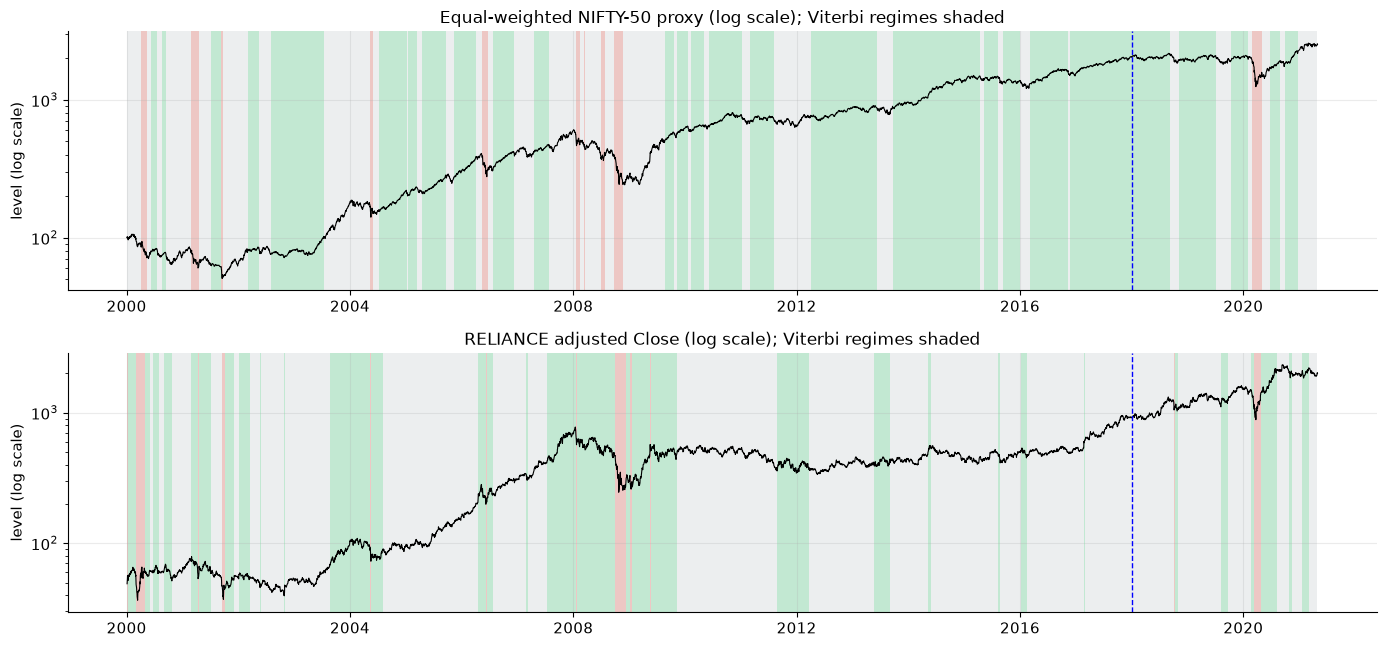

**Observations.** BIC selects K = 3 for the index and K = 3 for RELIANCE. From-scratch Baum–Welch matches `hmmlearn` (log-likelihood gap 1.7e-11 and 5.5e-12) and its likelihood never falls, and Viterbi agrees on 100.0% of days. On the index, the bear state has mean -0.665% and sd 3.38% (expected 12 days), sideways +0.028% and 1.51% (25 days), and bull +0.158% and 0.78% (63 days). So regimes differ more in volatility than in direction. Bear covers 4.3% of all days, but 26% of January 2008 to March 2009, 100% of March 2020 and 74% of the sharpest stretch from mid-September to November 2008, so both crises are detected. March 2020 is in the test period and uses parameters fitted before 2018. On RELIANCE the highest-mean state (+0.120%) has a higher sd (2.39%) than the middle one (1.41%), so 'bull' there is not the calmest state: the name is shorthand.

In [33]:
NAMES = {2: ["bear", "bull"], 3: ["bear", "sideways", "bull"], 4: ["bear", "weak", "strong", "bull"]}
def order_model(m):
    o = np.argsort(m["mu"]); return dict(pi=m["pi"][o], A=m["A"][o][:, o], mu=m["mu"][o], var=m["var"][o])
HMMR = {}
RG = {}
for key, r in [("ew", ew), ("reliance", rl)]:
    fit = FIT[key]; K = fit["K_best"]; m = order_model(fit["bw"]); names = NAMES[K]
    x_all = r.values; ptr = int((r.index < TEST_START).sum())
    fb_all = fb_scaled(x_all, m["pi"], m["A"], m["mu"], m["var"])
    path, _ = viterbi(x_all, m["pi"], m["A"], m["mu"], m["var"])
    # the library decodes with the same parameters; the state order is compared after sorting by mean
    _h = GaussianHMM(K, "diag", init_params="", params=""); _h.startprob_, _h.transmat_, _h.means_, _h.covars_ = m["pi"], m["A"], m["mu"][:, None], m["var"][:, None]
    _lp_path = _h.predict(x_all[:, None]); vit_agree = float(np.mean(_lp_path == path)); _lg = _h.predict_proba(x_all[:, None]); gam_diff = np.abs(_lg - fb_all["gamma"]).max()
    filt = fb_all["alpha"]; smooth = fb_all["gamma"]
    w, v = np.linalg.eig(m["A"].T); st = np.real(v[:, np.argmin(np.abs(w - 1))]); st = st / st.sum()
    dur = 1 / (1 - np.diag(m["A"]))
    ser = pd.Series(path, index=r.index)
    occ = np.bincount(path, minlength=K) / len(path)
    bear = 0
    def share(a, b): s_ = ser.loc[a:b]; return dict(start=a, end=b, days=len(s_), bear_share=float((s_ == bear).mean()), filtered_bear=float(filt[(r.index >= a) & (r.index <= b), bear].mean()), smoothed_bear=float(smooth[(r.index >= a) & (r.index <= b), bear].mean()))
    checks = dict(gfc=share("2008-01-01", "2009-03-31"), oct2008=share("2008-09-15", "2008-11-30"), covid=share("2020-03-01", "2020-03-31"), calm=share("2013-01-01", "2014-12-31"), overall=share(str(r.index.min().date()), str(r.index.max().date())))
    f_argmax = filt.argmax(1); s_argmax = smooth.argmax(1)
    print(f"\n=== {key}: K = {K}, parameters from train only ===")
    print(pd.DataFrame(dict(state=names, mean_pct=m["mu"], sd_pct=np.sqrt(m["var"]), a_ii=np.diag(m["A"]), expected_days=dur, stationary=st, occupancy_viterbi=occ)).round(4).to_string())
    print("A =\n", pd.DataFrame(m["A"], index=names, columns=names).round(4).to_string())
    print(f"Viterbi: agreement with hmmlearn {vit_agree:.5f}; max |γ − hmmlearn γ| = {gam_diff:.2e}; filtered argmax vs smoothed argmax disagree on {np.mean(f_argmax != s_argmax):.4f} of days; filtered argmax vs Viterbi on {np.mean(f_argmax != path):.4f}; smoothed vs Viterbi on {np.mean(s_argmax != path):.4f}")
    print("Bear share by period:", {a: round(b["bear_share"], 3) for a, b in checks.items()})
    HMMR[key] = dict(K=K, names=names, mean=m["mu"], sd=np.sqrt(m["var"]), A=m["A"], duration=dur, stationary=st, occupancy=occ, table=fit["table"], cmp=fit["cmp"], lab_demo=fit["lab_demo"], vit_agree=vit_agree, gam_diff=gam_diff, f_vs_s=float(np.mean(f_argmax != s_argmax)), f_vs_v=float(np.mean(f_argmax != path)), s_vs_v=float(np.mean(s_argmax != path)), checks=checks, n_train=ptr, n_all=len(r), pi=m["pi"])
    assert vit_agree == 1.0 and gam_diff < 1e-6
    RG[key] = dict(r=r, m=m, K=K, names=names, path=path, filt=filt, smooth=smooth, fb=fb_all, ptr=ptr)

fig, ax = plt.subplots(2, 1, figsize=(14, 6.6), sharex=False)
_cols = {"bear": "#c0392b", "sideways": "#bdc3c7", "bull": "#27ae60"}
for a, key, price, ttl in [(ax[0], "ew", ew_idx, "Equal-weighted NIFTY-50 proxy (log scale)"), (ax[1], "reliance", rel.Adj.reindex(rl.index), "RELIANCE adjusted Close (log scale)")]:
    rg = RG[key]; a.plot(price.index, price.values, "k", lw=.8); a.set_yscale("log"); a.set_ylabel("level (log scale)"); a.set_title(ttl + "; Viterbi regimes shaded")
    pth = rg["path"]; idx = rg["r"].index; s_ = 0
    for i in range(1, len(pth) + 1):
        if i == len(pth) or pth[i] != pth[s_]:
            a.axvspan(idx[s_], idx[min(i, len(idx) - 1)], color=_cols.get(rg["names"][pth[s_]], "#888"), alpha=.28, lw=0); s_ = i
    a.axvline(TEST_START, color="b", ls="--", lw=1)
plt.tight_layout(); savefig("u4_regimes"); plt.show()

_e = HMMR["ew"]; _rl_ = HMMR["reliance"]
obs(f"BIC selects K = {_e['K']} for the index and K = {_rl_['K']} for RELIANCE. From-scratch Baum–Welch matches `hmmlearn` (log-likelihood gap {_e['cmp']['ll_diff']:.1e} and {_rl_['cmp']['ll_diff']:.1e}) and its likelihood never falls, and Viterbi agrees on {100*_e['vit_agree']:.1f}% of days. "
    f"On the index, the bear state has mean {_e['mean'][0]:+.3f}% and sd {_e['sd'][0]:.2f}% (expected {_e['duration'][0]:.0f} days), sideways {_e['mean'][1]:+.3f}% and {_e['sd'][1]:.2f}% ({_e['duration'][1]:.0f} days), and bull {_e['mean'][2]:+.3f}% and {_e['sd'][2]:.2f}% ({_e['duration'][2]:.0f} days). So regimes differ more in volatility than in direction. "
    f"Bear covers {100*_e['checks']['overall']['bear_share']:.1f}% of all days, but {100*_e['checks']['gfc']['bear_share']:.0f}% of January 2008 to March 2009, {100*_e['checks']['covid']['bear_share']:.0f}% of March 2020 and {100*_e['checks']['oct2008']['bear_share']:.0f}% of the sharpest stretch from mid-September to November 2008, so both crises are detected. March 2020 is in the test period and uses parameters fitted before 2018. "
    f"On RELIANCE the highest-mean state ({_rl_['mean'][2]:+.3f}%) has a higher sd ({_rl_['sd'][2]:.2f}%) than the middle one ({_rl_['sd'][1]:.2f}%), so 'bull' there is not the calmest state: the name is shorthand.")

### Prediction with filtered probabilities only

Viterbi and smoothed posteriors at day t depend on returns after t, which would not be known at the time. **Out-of-sample forecasts must use the filtered (forward) probabilities only.**

`p(r_{t+1} | r_1..t) = Σ_j [Σ_i α̂_t(i) a_ij] N(r_{t+1} | μ_j, σ_j²)`

The forecast is "up" when P(r_{t+1} > 0) > 0.5. Forecasts are made at the close of each day from 2018-01-01 to 2021-04-29, so the targets are the **same 822 days** as Units 2 and 5. We also run the wrong version, which uses smoothed probabilities, to show how large the look-ahead gain would appear. The chance check is a one-sided binomial test against the majority rate.

Density quality is scored by mean out-of-sample log predictive density against an i.i.d. Normal and an i.i.d. Student-t fitted on train.

In [34]:
from sklearn.metrics import roc_auc_score
FC = {}
for key, rg in RG.items():
    r, m, ptr = rg["r"], rg["m"], rg["ptr"]; filt, smooth = rg["filt"], rg["smooth"]
    idx = r.index; pos = np.where((idx >= TEST_START) & (idx <= pd.Timestamp("2021-04-29")))[0]
    pi_f = filt[pos] @ m["A"]; pi_s = smooth[pos] @ m["A"]
    pj = stats.norm.sf(0, m["mu"], np.sqrt(m["var"]))
    p_up_f, p_up_s = pi_f @ pj, pi_s @ pj
    y_next = r.values[pos + 1]; up = (y_next > 0).astype(int); mean_f = pi_f @ m["mu"]
    var_f = pi_f @ (m["var"] + m["mu"] ** 2) - mean_f ** 2
    xtr_ = r.values[:ptr]; maj = int((xtr_ > 0).mean() > .5); mr = float(np.mean(up == maj))
    def row(p, lab):
        pred = (p > .5).astype(int); k = int((pred == up).sum())
        return dict(label=lab, accuracy=k / len(up), n_correct=k, n=len(up), auc=roc_auc_score(up, p), p_vs_majority=stats.binomtest(k, len(up), mr, alternative="greater").pvalue, share_up=float(pred.mean()))
    dens = np.exp(log_emis(y_next, m["mu"], m["var"])); lpd = np.log((pi_f * dens).sum(1))
    t_df, t_loc, t_sc = stats.t.fit(xtr_)
    lpd_n = stats.norm.logpdf(y_next, xtr_.mean(), xtr_.std()); lpd_t = stats.t.logpdf(y_next, t_df, t_loc, t_sc)
    cdf = (pi_f * stats.norm.cdf(y_next[:, None], m["mu"], np.sqrt(m["var"]))).sum(1); cov95 = float(np.mean((cdf > .025) & (cdf < .975)))
    cov95_n = float(np.mean(np.abs(y_next - xtr_.mean()) < 1.96 * xtr_.std()))
    d_ = lpd - lpd_n; dc = d_ - d_.mean(); _L = 5; _v = dc @ dc / len(d_) + 2 * sum((1 - l / (_L + 1)) * (dc[l:] @ dc[:-l]) / len(d_) for l in range(1, _L + 1)); t_lpd = d_.mean() / np.sqrt(_v / len(d_))
    FC[key] = dict(n=len(up), majority_class=maj, majority_rate=mr, filtered=row(p_up_f, "HMM forecast (filtered)"), smoothed_wrong=row(p_up_s, "Smoothed (uses the future)"), mean_abs_p=float(np.mean(np.abs(p_up_f - .5))), lpd_hmm=lpd.mean(), lpd_normal=lpd_n.mean(), lpd_t=lpd_t.mean(), lpd_t_stat=t_lpd, lpd_p=2 * stats.norm.sf(abs(t_lpd)), coverage95=cov95, coverage95_normal=cov95_n, first_target=idx[pos[0] + 1], last_target=idx[pos[-1] + 1], sd_forecast_min=float(np.sqrt(var_f).min()), sd_forecast_max=float(np.sqrt(var_f).max()))
    rg.update(p_up_f=p_up_f, p_up_s=p_up_s, pos=pos, sd_f=np.sqrt(var_f), y_next=y_next, mean_f=mean_f)
    print(key, {a: (round(b, 4) if isinstance(b, float) else b) for a, b in FC[key].items() if a not in ("filtered", "smoothed_wrong")}); print("  filtered:", {a: (round(b, 4) if isinstance(b, float) else b) for a, b in FC[key]["filtered"].items()}); print("  smoothed:", {a: (round(b, 4) if isinstance(b, float) else b) for a, b in FC[key]["smoothed_wrong"].items()})
assert FC["reliance"]["n"] == len(Dte) and (rl.index[RG["reliance"]["pos"] + 1] == pd.DatetimeIndex(rel.index[rel.index.get_indexer(Dte.index) + 1])).all()
assert FC["ew"]["filtered"]["accuracy"] < FC["ew"]["smoothed_wrong"]["accuracy"]
_f, _s = FC["ew"]["filtered"], FC["ew"]["smoothed_wrong"]; _fr = FC["reliance"]["filtered"]
obs(f"Direction: on the index, the honest filtered forecast scores {_f['accuracy']:.4f} against the majority rate {FC['ew']['majority_rate']:.4f} (p = {_f['p_vs_majority']:.3f}); on RELIANCE, {_fr['accuracy']:.4f} against {FC['reliance']['majority_rate']:.4f} (p = {_fr['p_vs_majority']:.3f}). "
    f"The look-ahead version would appear to score {_s['accuracy']:.4f} on the index (AUC {_s['auc']:.3f} against an honest {_f['auc']:.3f}), and that gap of {100*(_s['accuracy']-_f['accuracy']):.1f} percentage points comes from peeking at tomorrow's return. "
    f"Where the HMM does help is **density and risk**: mean log predictive density is {FC['ew']['lpd_hmm']:.4f} against {FC['ew']['lpd_normal']:.4f} for an i.i.d. Normal (Newey–West t = {FC['ew']['lpd_t_stat']:.2f}) and {FC['ew']['lpd_t']:.4f} for an i.i.d. Student-t on the index, and its forecast sd moves from {FC['ew']['sd_forecast_min']:.2f}% to {FC['ew']['sd_forecast_max']:.2f}%, tracking volatility. Regimes predict how much the market may move, not which way.")

ew {'n': 822, 'majority_class': 1, 'majority_rate': 0.5572, 'mean_abs_p': 0.0555, 'lpd_hmm': np.float64(-1.4816), 'lpd_normal': np.float64(-1.735), 'lpd_t': np.float64(-1.5527), 'lpd_t_stat': np.float64(2.9015), 'lpd_p': np.float64(0.0037), 'coverage95': 0.9526, 'coverage95_normal': 0.9611, 'first_target': Timestamp('2018-01-02 00:00:00'), 'last_target': Timestamp('2021-04-30 00:00:00'), 'sd_forecast_min': 0.8217, 'sd_forecast_max': 3.2698}
  filtered: {'label': 'HMM forecast (filtered)', 'accuracy': 0.545, 'n_correct': 448, 'n': 822, 'auc': 0.4814, 'p_vs_majority': np.float64(0.7697), 'share_up': 0.927}
  smoothed: {'label': 'Smoothed (uses the future)', 'accuracy': 0.562, 'n_correct': 462, 'n': 822, 'auc': 0.5382, 'p_vs_majority': np.float64(0.4034), 'share_up': 0.9392}
reliance {'n': 822, 'majority_class': 1, 'majority_rate': 0.5195, 'mean_abs_p': 0.0187, 'lpd_hmm': np.float64(-2.022), 'lpd_normal': np.float64(-2.1864), 'lpd_t': np.float64(-2.0609), 'lpd_t_stat': np.float64(2.8897),

**Observations.** Direction: on the index, the honest filtered forecast scores 0.5450 against the majority rate 0.5572 (p = 0.770); on RELIANCE, 0.5207 against 0.5195 (p = 0.486). The look-ahead version would appear to score 0.5620 on the index (AUC 0.538 against an honest 0.481), and that gap of 1.7 percentage points comes from peeking at tomorrow's return. Where the HMM does help is **density and risk**: mean log predictive density is -1.4816 against -1.7350 for an i.i.d. Normal (Newey–West t = 2.90) and -1.5527 for an i.i.d. Student-t on the index, and its forecast sd moves from 0.82% to 3.27%, tracking volatility. Regimes predict how much the market may move, not which way.

## Linear dynamical system: Kalman filter

We model `y_t = 100·ln(Adj Close)` for RELIANCE, in percent units.

- **Local level:** `y_t = μ_t + ε_t`, `μ_{t+1} = μ_t + η_t`, with Var(ε) = R and Var(η) = Q.
- **Local linear trend:** adds a slope, `μ_{t+1} = μ_t + β_t + η_t`, `β_{t+1} = β_t + ζ_t`.

Q and R are estimated by maximum likelihood on the **training period only**, using the prediction-error decomposition with an approximate diffuse start (a₀ = 0, P₀ = 10⁶·I, the first k_states terms left out). The filter and Rauch–Tung–Striebel (RTS) smoother are written from scratch and compared with `statsmodels.UnobservedComponents`.

**Filtered** μ_{t|t} uses data up to t. **Smoothed** μ_{t|T} uses the whole series, so it has the same look-ahead problem as the HMM's γ and cannot be used for forecasting.

local level: MLE R = 3.312e-06, Q = [4.669821], ln L = -9813.5920 | statsmodels R = 8.098e-11, Q = [4.670345], ln L = -9813.5918 | same parameters: filter diff 1.14e-13, smoother diff 1.14e-13, ln L diff 3.64e-12


local linear trend: MLE R = 1.389e-11, Q = [4.666898, 0.0], ln L = -9813.9388 | statsmodels R = 6.231e-10, Q = [4.667133, 0.0], ln L = -9813.9388 | same parameters: filter diff 5.68e-14, smoother diff 1.14e-13, ln L diff 2.78e-10


,key,model,rmse,mae,dm_t,dm_p,r2_ret,gain
0,persistence,Persistence,30.3051,20.8155,NaN,NaN,0.0000,1.0000
1,ll,Local level (MLE),30.3051,20.8155,-0.0223,0.9822,0.0000,1.0000
2,llt,Local linear trend (MLE),30.2925,20.8011,-0.3107,0.7561,0.0016,1.0000
3,illustrative,"Local level, q = 0.01 (fixed by hand)",73.8945,52.4919,6.0647,0.0000,-4.8263,0.0951


Local level MLE: q = Q/R = 1.410e+06, steady gain K = 1.0000; mean |filtered − observed| = 0.0000% | autocorr(1) of train returns = 0.0639
Illustrative q = 0.01: gain 0.0951; RMS distance from price, filtered 4.609% vs smoothed 3.474%
First day P(bear) > 0.5: {'ew': {'gfc': {'first_filtered': Timestamp('2008-10-06 00:00:00'), 'first_smoothed': Timestamp('2008-09-29 00:00:00'), 'lead_days': 4, 'mean_abs_gap': 0.09656333826453815}, 'covid': {'first_filtered': Timestamp('2020-03-09 00:00:00'), 'first_smoothed': Timestamp('2020-02-28 00:00:00'), 'lead_days': 6, 'mean_abs_gap': 0.15506457400779902}}, 'reliance': {'gfc': {'first_filtered': Timestamp('2008-10-03 00:00:00'), 'first_smoothed': Timestamp('2008-10-01 00:00:00'), 'lead_days': 1, 'mean_abs_gap': 0.12740797759937073}, 'covid': {'first_filtered': Timestamp('2020-03-09 00:00:00'), 'first_smoothed': Timestamp('2020-03-06 00:00:00'), 'lead_days': 1, 'mean_abs_gap': 0.10725557921668696}}}


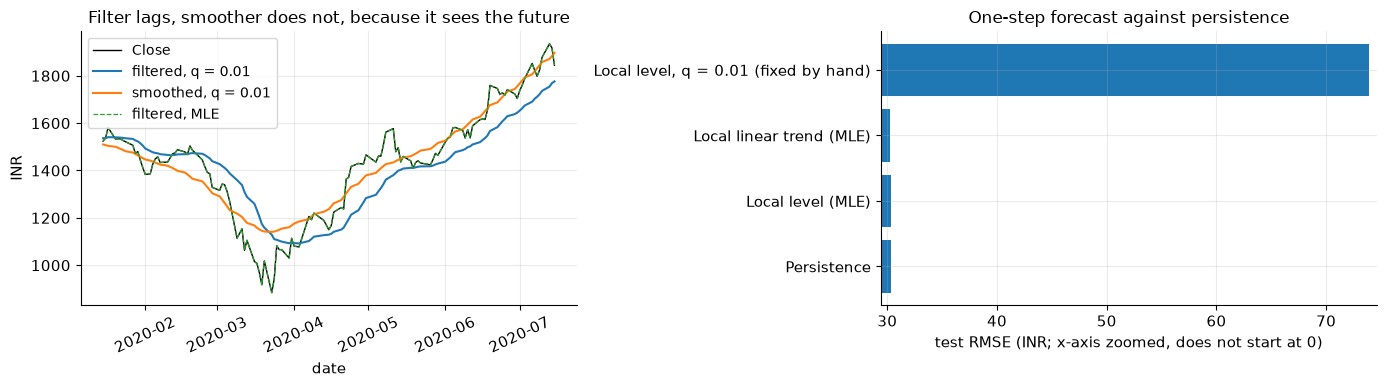

**Observations.** The from-scratch filter and RTS smoother reproduce `statsmodels` at the same parameters (filter gap 1.1e-13, smoother gap 1.1e-13), and the MLE log-likelihoods agree within 2.2e-04. The local-level MLE pushes R to its boundary (3.3e-06, against Q = 4.670), so the steady-state gain is K = 1.0000 and the filtered level equals today's price. There is a reason: this model implies a lag-1 autocorrelation of −R/(Q+2R) ≤ 0 in daily changes, but the training returns have +0.0639, so the likelihood's best choice is R ≈ 0. **Forecast against persistence:** persistence RMSE 30.305, local level 30.305 (DM p = 0.982), local linear trend 30.293 (DM p = 0.756). None is significantly better. The local level ties persistence because it has become persistence. The linear trend's slope variance also goes to zero, leaving a constant drift. To get a visible trend line, we also show a hand-fixed q = 0.01 (gain 0.095, mean lag (1−K)/K = 9.5 days). It looks smoother, but it forecasts significantly worse (RMSE 73.895, DM p = 1.32e-09) because it lags the price. The smoother removes that lag only by using future prices. So the Kalman filter describes the trend, and likelihood estimation correctly says that there is nothing to extract for one-day forecasting.

In [35]:
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score as _auc
y_true = Dte.close_next.values; r_true = Dte.r_next.values
def dm_test(e1, e0, lags=5):
    d = e1 ** 2 - e0 ** 2; n = len(d); dc = d - d.mean()
    v = dc @ dc / n + 2 * sum((1 - l / (lags + 1)) * (dc[l:] @ dc[:-l]) / n for l in range(1, lags + 1))
    t_ = d.mean() / np.sqrt(v / n)
    return t_, 2 * stats.norm.sf(abs(t_))
def kf_matrices(kind, theta):
    v = np.exp(theta)
    if kind == "ll": return np.array([[1.0]]), np.array([[1.0]]), np.array([[v[1]]]), v[0]
    return np.array([[1.0, 1.0], [0.0, 1.0]]), np.array([[1.0, 0.0]]), np.diag([v[1], v[2]]), v[0]

def kalman(y, TT, Z, Q, R, a0=None, P0=None, burn=None):
    n, k = len(y), TT.shape[0]; a = np.zeros(k) if a0 is None else a0.copy(); P = np.eye(k) * 1e6 if P0 is None else P0.copy()
    burn = k if burn is None else burn
    ap, Pp, af, Pf = np.zeros((n, k)), np.zeros((n, k, k)), np.zeros((n, k)), np.zeros((n, k, k)); ll = 0.0; Kg = np.zeros((n, k)); Fv = np.zeros(n)
    Zr = Z[0]
    for t in range(n):
        ap[t], Pp[t] = a, P
        v = y[t] - Zr @ a; PZ = P @ Zr; F = Zr @ PZ + R; K_ = PZ / F
        a = a + K_ * v; P = P - np.outer(K_, PZ)
        af[t], Pf[t] = a, P; Kg[t] = K_; Fv[t] = F
        if t >= burn: ll += -.5 * (np.log(2 * np.pi) + np.log(F) + v * v / F)
        a = TT @ a; P = TT @ P @ TT.T + Q
    return dict(ap=ap, Pp=Pp, af=af, Pf=Pf, ll=ll, K=Kg, F=Fv, a_next=a, P_next=P)

def rts(kf, TT):
    n, k = kf["af"].shape; s = np.zeros((n, k)); s[-1] = kf["af"][-1]
    for t in range(n - 2, -1, -1):
        C = kf["Pf"][t] @ TT.T @ np.linalg.inv(kf["Pp"][t + 1]); s[t] = kf["af"][t] + C @ (s[t + 1] - kf["ap"][t + 1])
    return s

_rel_price = rel.Adj
y_all = 100 * np.log(_rel_price.values); n_tr = int((_rel_price.index < TEST_START).sum()); y_tr = y_all[:n_tr]
KF = {}
for kind, spec, starts in [("ll", "local level", [np.log([1.0, 3.0]), np.log([.01, 4.0])]), ("llt", "local linear trend", [np.log([1.0, 3.0, 1e-4]), np.log([.01, 4.0, 1e-3])])]:
    def nll(th):
        TT, Z, Q, R = kf_matrices(kind, th); return -kalman(y_tr, TT, Z, Q, R)["ll"]
    best = None
    for st in starts:
        o_ = optimize.minimize(nll, st, method="L-BFGS-B", bounds=[(-25, 8)] * len(st), options=dict(maxiter=300, ftol=1e-11))
        if best is None or o_.fun < best.fun: best = o_
    TT, Z, Q, R_v = kf_matrices(kind, best.x)
    mod = sm.tsa.UnobservedComponents(y_tr, spec); res = mod.fit(disp=0, maxiter=2000, method="lbfgs")
    # the from-scratch filter run at statsmodels' own parameters must reproduce its states
    pv = res.params; sm_R = pv[0]; sm_Q = pv[1:]
    th_sm = np.log(np.maximum(pv, 1e-300)); TTs, Zs, Qs, Rs = kf_matrices(kind, th_sm)
    k_sm = kalman(y_tr, TTs, Zs, Qs, Rs); s_sm = rts(k_sm, TTs)
    filt_diff = np.abs(k_sm["af"][50:, 0] - res.filtered_state[0, 50:]).max(); sm_diff = np.abs(s_sm[50:, 0] - res.smoothed_state[0, 50:]).max(); ll_at_sm = abs(k_sm["ll"] - res.llf)
    KF[kind] = dict(spec=spec, R=R_v, Q=np.diag(Q).tolist(), ll=-best.fun, sm_R=sm_R, sm_Q=sm_Q, sm_ll=res.llf, ll_diff_mle=abs(-best.fun - res.llf), filt_diff=filt_diff, smooth_diff=sm_diff, ll_at_sm_diff=ll_at_sm, TT=TT, Z=Z, Qm=Q)
    print(f"{spec}: MLE R = {R_v:.3e}, Q = {np.round(np.diag(Q),6).tolist()}, ln L = {-best.fun:.4f} | statsmodels R = {sm_R:.3e}, Q = {np.round(sm_Q,6).tolist()}, ln L = {res.llf:.4f} | same parameters: filter diff {filt_diff:.2e}, smoother diff {sm_diff:.2e}, ln L diff {ll_at_sm:.2e}")
    assert filt_diff < 1e-6 and sm_diff < 1e-5 and abs(-best.fun - res.llf) < .05

# full-sample filtering with parameters from train, and honest one-step forecasts
fc_rows = []; idx_all = _rel_price.index; t_pos = rel.index.get_indexer(Dte.index)
y_price = _rel_price.values; assert np.allclose(y_price[t_pos + 1], y_true)
def forecast_price(kind_key, TT, Z, Q, R):
    k_ = kalman(y_all, TT, Z, Q, R); yhat = (k_["ap"] @ Z[0])[t_pos + 1]; return np.exp(yhat / 100), k_
_pers = rel.Adj.values[t_pos]
for kind, label in [("ll", "Local level (MLE)"), ("llt", "Local linear trend (MLE)")]:
    p_ = KF[kind]; ph, k_ = forecast_price(kind, p_["TT"], p_["Z"], p_["Qm"], p_["R"]); s_ = rts(k_, p_["TT"]); p_.update(forecast=ph, kf=k_, smooth=s_)
    fc_rows.append(dict(key=kind, model=label, rmse=np.sqrt(np.mean((y_true - ph) ** 2)), mae=np.mean(np.abs(y_true - ph)), dm_t=dm_test(y_true - ph, y_true - _pers)[0], dm_p=dm_test(y_true - ph, y_true - _pers)[1], r2_ret=1 - np.sum((r_true - np.log(ph / _pers)) ** 2) / np.sum(r_true ** 2), gain=float(k_["K"][-1, 0])))
# an illustrative heavier smoother: signal-to-noise fixed by hand, not by likelihood
q_fixed = 0.01; _tot_var = np.var(np.diff(y_tr)); R_ill = _tot_var / (2 + q_fixed); Q_ill = q_fixed * R_ill
TT_i, Z_i = np.array([[1.0]]), np.array([[1.0]]); ph_i, k_i = forecast_price("ill", TT_i, Z_i, np.array([[Q_ill]]), R_ill); s_i = rts(k_i, TT_i)
fc_rows.append(dict(key="illustrative", model=f"Local level, q = {q_fixed} (fixed by hand)", rmse=np.sqrt(np.mean((y_true - ph_i) ** 2)), mae=np.mean(np.abs(y_true - ph_i)), dm_t=dm_test(y_true - ph_i, y_true - _pers)[0], dm_p=dm_test(y_true - ph_i, y_true - _pers)[1], r2_ret=1 - np.sum((r_true - np.log(ph_i / _pers)) ** 2) / np.sum(r_true ** 2), gain=float(k_i["K"][-1, 0])))
fc_rows.insert(0, dict(key="persistence", model="Persistence", rmse=np.sqrt(np.mean((y_true - _pers) ** 2)), mae=np.mean(np.abs(y_true - _pers)), dm_t=None, dm_p=None, r2_ret=0.0, gain=1.0))
_rmse_pers_chk = np.sqrt(np.mean((Dte.close_next.values - Dte.close_t.values) ** 2)); assert abs(fc_rows[0]["rmse"] - _rmse_pers_chk) < 1e-9
kf_tab = pd.DataFrame(fc_rows); display(kf_tab.round(4))
_ll = KF["ll"]; q_hat = _ll["Q"][0] / _ll["R"]; ll_g = _ll["kf"]["K"][-1, 0]
_tr_mask = np.arange(len(y_all)) < n_tr
_lag_filt = np.sqrt(np.mean((y_all - k_i["af"][:, 0]) ** 2)); _lag_smooth = np.sqrt(np.mean((y_all - s_i[:, 0]) ** 2))
_dmle = np.abs(_ll["kf"]["af"][:, 0] - y_all); print(f"Local level MLE: q = Q/R = {q_hat:.3e}, steady gain K = {ll_g:.4f}; mean |filtered − observed| = {_dmle.mean():.4f}% | autocorr(1) of train returns = {np.corrcoef(np.diff(y_tr)[1:], np.diff(y_tr)[:-1])[0,1]:.4f}")
print(f"Illustrative q = {q_fixed}: gain {k_i['K'][-1,0]:.4f}; RMS distance from price, filtered {_lag_filt:.3f}% vs smoothed {_lag_smooth:.3f}%")

_ac1 = np.corrcoef(np.diff(y_tr)[1:], np.diff(y_tr)[:-1])[0, 1]; _mean_lag = (1 - k_i["K"][-1, 0]) / k_i["K"][-1, 0]
R["u4"] = dict(ew=HMMR["ew"], reliance=HMMR["reliance"], forecast=FC, brute_force=bf, underflow_day=_under, n_train_days=len(_x), ll_scaled=_fb0["ll"], ll_log_space=ll_log, ll_scaling_diff=abs(ll_log - _fb0["ll"]), ew_days=len(ew), ew_mean=ew.mean(), ew_sd=ew.std(), rel_days=len(rl),
    kalman=dict(ll={k: v for k, v in _ll.items() if k in ("spec", "R", "Q", "ll", "sm_R", "sm_Q", "sm_ll", "ll_diff_mle", "filt_diff", "smooth_diff", "ll_at_sm_diff")}, llt={k: v for k, v in KF["llt"].items() if k in ("spec", "R", "Q", "ll", "sm_R", "sm_Q", "sm_ll", "ll_diff_mle", "filt_diff", "smooth_diff", "ll_at_sm_diff")}, forecast=fc_rows, q_hat=q_hat, gain=ll_g, q_fixed=q_fixed, gain_fixed=float(k_i["K"][-1, 0]), lag_filtered=_lag_filt, lag_smoothed=_lag_smooth, n_sig_better=int(sum(1 for r_ in fc_rows if r_["dm_p"] is not None and r_["dm_p"] < .05 and r_["rmse"] < fc_rows[0]["rmse"])), mean_abs_filter_gap=_dmle.mean(), autocorr1=_ac1, mean_lag=_mean_lag))
save_results()

def segments(path, idx):
    out = []; s_ = 0
    for i in range(1, len(path) + 1):
        if i == len(path) or path[i] != path[s_]:
            out.append([str(idx[s_].date()), str(idx[min(i, len(idx) - 1)].date()), int(path[s_])]); s_ = i
    return out
_reg_chart = {}
for key, price, label in [("ew", ew_idx, "Equal-weighted NIFTY-50 proxy"), ("reliance", rel.Adj.reindex(rl.index), "RELIANCE adjusted Close")]:
    rg = RG[key]; _i = ds_idx(np.log(price.values), 1400)
    _reg_chart[key] = dict(label=label, date=dstr(price.index[_i]), price=rnd(price.values[_i], 2), names=rg["names"], segments=segments(rg["path"], rg["r"].index), split=str(TEST_START.date()))
chart("u4_regimes", _reg_chart)
_look = {}
for key, rg in RG.items():
    b_ = 0; _look[key] = {}
    for w, (a_, c_) in dict(gfc=("2008-08-01", "2009-01-31"), covid=("2020-02-01", "2020-05-29")).items():
        m_ = (rg["r"].index >= a_) & (rg["r"].index <= c_)
        _look[key][w] = dict(date=dstr(rg["r"].index[m_]), r=rnd(rg["r"].values[m_], 3), filtered=rnd(rg["filt"][m_, b_], 4), smoothed=rnd(rg["smooth"][m_, b_], 4), viterbi=[int(x == b_) for x in rg["path"][m_]])
chart("u4_lookahead", _look)
# how early does each posterior flag the crash? first day with P(bear) > 0.5 in each window, and the return on that day
_lead = {}
for key, rg in RG.items():
    _lead[key] = {}
    for w, (a_, c_) in dict(gfc=("2008-08-01", "2009-01-31"), covid=("2020-02-01", "2020-05-29")).items():
        m_ = (rg["r"].index >= a_) & (rg["r"].index <= c_); ix = rg["r"].index[m_]; f_, s2_ = rg["filt"][m_, 0], rg["smooth"][m_, 0]
        i_f, i_s = int(np.argmax(f_ > .5)), int(np.argmax(s2_ > .5))
        _lead[key][w] = dict(first_filtered=ix[i_f], first_smoothed=ix[i_s], lead_days=i_f - i_s, mean_abs_gap=float(np.abs(f_ - s2_).mean()))
print("First day P(bear) > 0.5:", _lead)
R["u4"]["lookahead"] = _lead; save_results()
_fc = {}
for key, rg in RG.items():
    idx_ = rg["r"].index[rg["pos"] + 1]
    _fc[key] = dict(date=dstr(idx_), p_up=rnd(rg["p_up_f"], 4), p_up_smoothed=rnd(rg["p_up_s"], 4), sd=rnd(rg["sd_f"], 3), realised=rnd(rg["y_next"], 3), mean=rnd(rg["mean_f"], 4))
chart("u4_forecast", _fc)
_ki = ds_idx(y_all, 1300)
chart("u4_kalman", dict(date=dstr(idx_all[_ki]), close=rnd(_rel_price.values[_ki], 2), mle_filtered=rnd(np.exp(_ll["kf"]["af"][_ki, 0] / 100), 2), mle_smoothed=rnd(np.exp(_ll["smooth"][_ki, 0] / 100), 2), ill_filtered=rnd(np.exp(k_i["af"][_ki, 0] / 100), 2), ill_smoothed=rnd(np.exp(s_i[_ki, 0] / 100), 2),
    llt_filtered=rnd(np.exp(KF["llt"]["kf"]["af"][_ki, 0] / 100), 2), llt_smoothed=rnd(np.exp(KF["llt"]["smooth"][_ki, 0] / 100), 2), split=str(TEST_START.date()),
    zoom=(lambda m_: dict(date=dstr(idx_all[m_]), close=rnd(_rel_price.values[m_], 2), mle_filtered=rnd(np.exp(_ll["kf"]["af"][m_, 0] / 100), 2), mle_smoothed=rnd(np.exp(_ll["smooth"][m_, 0] / 100), 2), ill_filtered=rnd(np.exp(k_i["af"][m_, 0] / 100), 2), ill_smoothed=rnd(np.exp(s_i[m_, 0] / 100), 2)))((idx_all >= "2020-01-15") & (idx_all <= "2020-07-15"))))
fig, ax = plt.subplots(1, 2, figsize=(14, 4)); _m = (idx_all >= "2020-01-15") & (idx_all <= "2020-07-15")
ax[0].plot(idx_all[_m], _rel_price.values[_m], "k", lw=1, label="Close"); ax[0].plot(idx_all[_m], np.exp(k_i["af"][_m, 0] / 100), label=f"filtered, q = {q_fixed}"); ax[0].plot(idx_all[_m], np.exp(s_i[_m, 0] / 100), label=f"smoothed, q = {q_fixed}"); ax[0].plot(idx_all[_m], np.exp(_ll["kf"]["af"][_m, 0] / 100), "--", lw=.9, label="filtered, MLE")
ax[0].set_ylabel("INR"); ax[0].set_xlabel("date"); ax[0].tick_params(axis="x", rotation=25); ax[0].legend(); ax[0].set_title("Filter lags, smoother does not, because it sees the future")
_ft = kf_tab.set_index("model").rmse; ax[1].barh(_ft.index, _ft.values); ax[1].set_xlim(_ft.min() * .97, _ft.max() * 1.01); ax[1].set_xlabel("test RMSE (INR; x-axis zoomed, does not start at 0)"); ax[1].set_title("One-step forecast against persistence")
plt.tight_layout(); savefig("u4_kalman"); plt.show()
_fll = fc_rows[1]; _fllt = fc_rows[2]; _fi = fc_rows[3]
obs(f"The from-scratch filter and RTS smoother reproduce `statsmodels` at the same parameters (filter gap {_ll['filt_diff']:.1e}, smoother gap {_ll['smooth_diff']:.1e}), and the MLE log-likelihoods agree within {_ll['ll_diff_mle']:.1e}. "
    f"The local-level MLE pushes R to its boundary ({_ll['R']:.1e}, against Q = {_ll['Q'][0]:.3f}), so the steady-state gain is K = {ll_g:.4f} and the filtered level equals today's price. There is a reason: this model implies a lag-1 autocorrelation of −R/(Q+2R) ≤ 0 in daily changes, but the training returns have {_ac1:+.4f}, so the likelihood's best choice is R ≈ 0. "
    f"**Forecast against persistence:** persistence RMSE {fc_rows[0]['rmse']:.3f}, local level {_fll['rmse']:.3f} (DM p = {_fll['dm_p']:.3f}), local linear trend {_fllt['rmse']:.3f} (DM p = {_fllt['dm_p']:.3f}). "
    f"{'None is' if R['u4']['kalman']['n_sig_better'] == 0 else 'Some are'} significantly better. The local level ties persistence because it has become persistence. The linear trend's slope variance also goes to zero, leaving a constant drift. To get a visible trend line, we also show a hand-fixed q = {q_fixed} (gain {k_i['K'][-1,0]:.3f}, mean lag (1−K)/K = {_mean_lag:.1f} days). It looks smoother, but it forecasts significantly worse (RMSE {_fi['rmse']:.3f}, DM p = {fmt_p(_fi['dm_p'])}) because it lags the price. The smoother removes that lag only by using future prices. So the Kalman filter describes the trend, and likelihood estimation correctly says that there is nothing to extract for one-day forecasting.")

# UNIT 5
**Assigned title:** Ensemble prediction of daily price direction using CART, Random Forest, AdaBoost & Gradient Boosting

**Syllabus mapping:** CART, boosting (AdaBoost / Gradient Boosting), adaptive basis function models, generalized additive models, ensemble learning (Bagging / Random Forest / Stacking), Bayesian model averaging → daily direction.

Same RELIANCE split, same 21 features and same target `1[r_{t+1} > 0]` as Unit 2, with the same baselines. Trees do not depend on feature scale, so they use raw features, which also makes their thresholds readable. Models that need scaling use a scaler fitted on train only. All tuning uses `TimeSeriesSplit(5)` on training rows, with AUC as the score.

**Adaptive basis function models.** All of these fit `f(x) = w₀ + Σ_m w_m φ_m(x; v_m)`. In a linear model the basis φ is fixed. In a tree, each leaf is a basis function (an indicator of a learned region). In boosting, each new weak learner is a basis function fitted to what the model so far gets wrong, added stagewise. A GAM sits in between: it uses `f(x) = β₀ + Σ_j f_j(x_j)`, with one smooth function per feature from a fixed spline basis, which keeps the model readable but rules out interactions.

In [36]:
from functools import reduce
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, log_loss
from pygam import LogisticGAM, s as gam_s, l as gam_l

Xr, Xrte = Dtr[ENG].values, Dte[ENG].values
y5, y5te = Dtr.y_dir.values.astype(int), Dte.y_dir.values.astype(int)
sc5 = StandardScaler().fit(Xr); Xz, Xzte = sc5.transform(Xr), sc5.transform(Xrte)
maj5 = int(y5.mean() > .5); mr5 = float(np.mean(y5te == maj5)); n1_, n0_ = int(y5te.sum()), int((1 - y5te).sum()); half5 = 1.96 * np.sqrt((n1_ + n0_ + 1) / (12 * n1_ * n0_))
L5, ROC5, TUNE = {}, {}, {}
def rec5(key, label, group, p=None, yhat=None, cv_auc=None, keep_roc=True):
    yh = (p > .5).astype(int) if yhat is None else np.asarray(yhat).astype(int); k = int((yh == y5te).sum())
    auc = None if p is None or len(np.unique(p)) == 1 else roc_auc_score(y5te, p)
    L5[key] = dict(key=key, model=label, group=group, accuracy=k / len(y5te), n_correct=k, n_test=len(y5te), f1=f1_score(y5te, yh), auc=auc, cv_auc=cv_auc, log_loss=None if p is None else log_loss(y5te, np.clip(p, 1e-9, 1 - 1e-9)), p_vs_majority=stats.binomtest(k, len(y5te), mr5, alternative="greater").pvalue, share_up=float(yh.mean()), auc_in_chance_band=None if auc is None else bool(abs(auc - .5) <= half5))
    if auc is not None and keep_roc:
        a_, b_, _ = roc_curve(y5te, p); ROC5[key] = dict(fpr=rnd(a_, 4), tpr=rnd(b_, 4))
rec5("majority", "Majority class", "baseline", p=np.full(len(y5te), y5.mean()), keep_roc=False)
rec5("same_as_today", "Same as today", "baseline", p=(Dte.r_lag0.values > 0).astype(float))
L5["same_as_today"]["log_loss"] = None
print(f"Majority rate {mr5:.5f}; AUC chance band [{.5-half5:.4f}, {.5+half5:.4f}]; train P(up) {y5.mean():.5f}")

def grid_cv(est, grid):
    gs = GridSearchCV(est, grid, cv=tscv, scoring="roc_auc", n_jobs=-1).fit(Xr, y5)
    edges = {k: gs.best_params_[k] for k, v in grid.items() if len(v) > 1 and gs.best_params_[k] in (v[0], v[-1])}
    return gs, dict(best=gs.best_params_, cv_auc=gs.best_score_, at_edge=edges)

Majority rate 0.51946; AUC chance band [0.4605, 0.5395]; train P(up) 0.51578


## Unit 5, Practice 1: CART for categorization

CART grows a binary tree by greedily choosing the split that most reduces Gini impurity, then prunes it. **Cost-complexity pruning** minimises `R_α(T) = R(T) + α|T|`, where |T| is the number of leaves. Each α on the pruning path gives one tree, and α is chosen with `TimeSeriesSplit`. A pruned tree with no splits at all is excluded from the grid, because it has no ordering of test days to score.

Unpruned tree: 886 leaves, depth 25, train accuracy 1.0000, test accuracy 0.5097
CV chose ccp_alpha = 0.001629: 3 leaves, depth 2, CV AUC 0.4981, train accuracy 0.5387, test accuracy 0.4696; at grid edge: {}
|--- vol_ratio20 <= 0.82
|   |--- class: 0
|--- vol_ratio20 >  0.82
|   |--- r_lag2 <= 0.04
|   |   |--- class: 1
|   |--- r_lag2 >  0.04
|   |   |--- class: 0



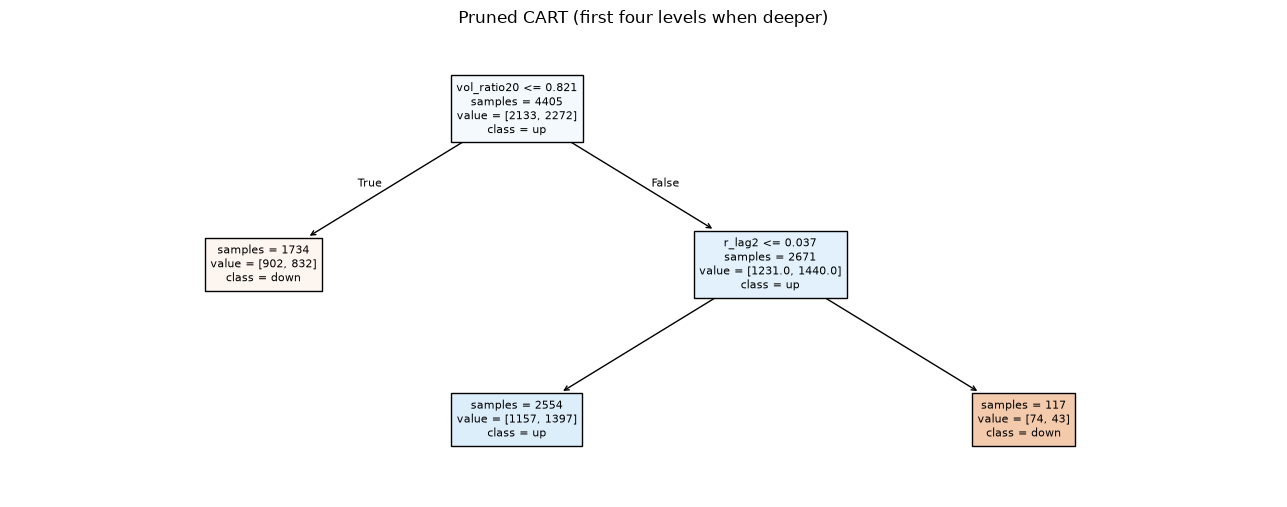

**Observations.** The unpruned tree has 886 leaves and memorises the training set (train accuracy 1.000), yet scores only 0.510 on test, a clear sign of overfitting. CV pruning keeps 3 leaves (depth 2), with train accuracy 0.539 and test accuracy 0.470, against a majority rate of 0.519. Even the best pruned tree has a CV AUC of 0.498, about what a coin flip gives, so a single tree finds no usable rule. It is plotted because it is small enough to read, not because it predicts well.

In [37]:
_full = DecisionTreeClassifier(random_state=SEED).fit(Xr, y5)
_path = _full.cost_complexity_pruning_path(Xr, y5)
_al = np.unique(_path.ccp_alphas[:-1]); _al = _al[_al >= 0]
# the path is dense at tiny α, so the 60 largest values (the small trees) are all kept, and the rest are sampled
_cand = np.unique(np.r_[_al[-60:], np.quantile(_al[:-60], np.linspace(0, 1, 20))])
gs_cart, TUNE["cart"] = grid_cv(DecisionTreeClassifier(random_state=SEED), {"ccp_alpha": list(_cand)})
cart = gs_cart.best_estimator_
_cv_c = pd.DataFrame(gs_cart.cv_results_)[["param_ccp_alpha", "mean_test_score"]].astype(float)
_fits = [DecisionTreeClassifier(random_state=SEED, ccp_alpha=a).fit(Xr, y5) for a in _cand]
_leaves = [t_.get_n_leaves() for t_ in _fits]; _tr_acc = [t_.score(Xr, y5) for t_ in _fits]
print(f"Unpruned tree: {_full.get_n_leaves()} leaves, depth {_full.get_depth()}, train accuracy {_full.score(Xr,y5):.4f}, test accuracy {_full.score(Xrte,y5te):.4f}")
print(f"CV chose ccp_alpha = {cart.ccp_alpha:.6f}: {cart.get_n_leaves()} leaves, depth {cart.get_depth()}, CV AUC {gs_cart.best_score_:.4f}, train accuracy {cart.score(Xr,y5):.4f}, test accuracy {cart.score(Xrte,y5te):.4f}; at grid edge: {TUNE['cart']['at_edge']}")
print(export_text(cart, feature_names=ENG, max_depth=4)[:1800])
rec5("cart", "CART (pruned)", "tree", p=cart.predict_proba(Xrte)[:, 1], cv_auc=gs_cart.best_score_)
def tree_json(t):
    tr = t.tree_; nodes = []
    for i in range(tr.node_count):
        v = tr.value[i][0] / tr.value[i][0].sum()
        nodes.append(dict(id=i, left=int(tr.children_left[i]), right=int(tr.children_right[i]), feature=None if tr.children_left[i] < 0 else ENG[tr.feature[i]], threshold=None if tr.children_left[i] < 0 else float(f"{tr.threshold[i]:.5g}"), samples=int(tr.n_node_samples[i]), p_up=round(float(v[1]), 4), gini=round(float(tr.impurity[i]), 4)))
    return nodes
from sklearn.tree import plot_tree
fig, ax = plt.subplots(figsize=(13, 5.2)); plot_tree(cart, feature_names=ENG, class_names=["down", "up"], filled=True, impurity=False, proportion=False, fontsize=8, ax=ax, max_depth=4); ax.set_title("Pruned CART (first four levels when deeper)"); plt.tight_layout(); savefig("u5_cart"); plt.show()
_ct = dict(alpha=cart.ccp_alpha, n_leaves=cart.get_n_leaves(), depth=cart.get_depth(), cv_auc=gs_cart.best_score_, train_acc=cart.score(Xr, y5), test_acc=cart.score(Xrte, y5te), full_leaves=_full.get_n_leaves(), full_depth=_full.get_depth(), full_train_acc=_full.score(Xr, y5), full_test_acc=_full.score(Xrte, y5te), at_edge=TUNE["cart"]["at_edge"], n_grid=len(_cand))
obs(f"The unpruned tree has {_full.get_n_leaves()} leaves and memorises the training set (train accuracy {_full.score(Xr,y5):.3f}), yet scores only {_full.score(Xrte,y5te):.3f} on test, a clear sign of overfitting. CV pruning keeps {cart.get_n_leaves()} leaves (depth {cart.get_depth()}), with train accuracy {cart.score(Xr,y5):.3f} and test accuracy {cart.score(Xrte,y5te):.3f}, against a majority rate of {mr5:.3f}. Even the best pruned tree has a CV AUC of {gs_cart.best_score_:.3f}, about what a coin flip gives, so a single tree finds no usable rule. It is plotted because it is small enough to read, not because it predicts well.")

## Unit 5, Practice 2: ensemble classifiers

- **Bagging** averages deep trees fitted on bootstrap samples, which lowers variance.
- **Random Forest** also samples features at each split, which decorrelates the trees.
- **AdaBoost** fits stumps in sequence, reweighting mistakes (SAMME).
- **Gradient Boosting** fits each tree to the gradient of the log-loss.
- **Stacking** trains a logistic meta-learner on base-model predictions. Standard K-fold stacking would leak future data into the meta-features, so out-of-fold predictions here come from the same expanding-window folds. The meta-learner therefore sees only rows that come after the data used to train each base model.

In [38]:
gs_bag, TUNE["bagging"] = grid_cv(BaggingClassifier(DecisionTreeClassifier(random_state=SEED), n_estimators=150, random_state=SEED), {"estimator__min_samples_leaf": [1, 5, 20, 50, 100], "max_samples": [0.5, 1.0]})
rec5("bagging", "Bagging", "ensemble", p=gs_bag.predict_proba(Xrte)[:, 1], cv_auc=gs_bag.best_score_)
gs_rf, TUNE["random_forest"] = grid_cv(RandomForestClassifier(n_estimators=300, random_state=SEED), {"max_depth": [2, 3, 5, 8, None], "min_samples_leaf": [5, 20, 50, 100], "max_features": ["sqrt", 0.33, 0.5]})
rf = gs_rf.best_estimator_; rec5("random_forest", "Random Forest", "ensemble", p=rf.predict_proba(Xrte)[:, 1], cv_auc=gs_rf.best_score_)
gs_ada, TUNE["adaboost"] = grid_cv(AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), random_state=SEED), {"n_estimators": [5, 10, 25, 50, 100, 200, 400], "learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0]})
ada = gs_ada.best_estimator_; rec5("adaboost", "AdaBoost", "ensemble", p=ada.predict_proba(Xrte)[:, 1], cv_auc=gs_ada.best_score_)
gs_gb, TUNE["gradient_boosting"] = grid_cv(GradientBoostingClassifier(subsample=0.8, random_state=SEED), {"n_estimators": [10, 25, 50, 100, 200, 400], "learning_rate": [0.001, 0.005, 0.01, 0.05, 0.1], "max_depth": [1, 2, 3]})
gb = gs_gb.best_estimator_; rec5("gradient_boosting", "Gradient Boosting", "ensemble", p=gb.predict_proba(Xrte)[:, 1], cv_auc=gs_gb.best_score_)
for k_, v_ in TUNE.items(): print(f"{k_}: {v_['best'] if k_ != 'cart' else round(v_['best']['ccp_alpha'], 6)} | CV AUC {v_['cv_auc']:.4f} | at grid edge: {v_['at_edge']}")

# Stacking with expanding-window out-of-fold predictions
base_makers = dict(cart=lambda: DecisionTreeClassifier(random_state=SEED, ccp_alpha=cart.ccp_alpha), random_forest=lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, **gs_rf.best_params_), adaboost=lambda: AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), random_state=SEED, **gs_ada.best_params_), gradient_boosting=lambda: GradientBoostingClassifier(subsample=.8, random_state=SEED, **gs_gb.best_params_))
oof = np.full((len(y5), len(base_makers)), np.nan)
for tr_i, va_i in tscv.split(Xr):
    for j, mk in enumerate(base_makers.values()):
        oof[va_i, j] = mk().fit(Xr[tr_i], y5[tr_i]).predict_proba(Xr[va_i])[:, 1]
_ok = ~np.isnan(oof).any(1); print(f"Out-of-fold rows for the meta-learner: {_ok.sum()} of {len(y5)} (rows before the first validation fold have no out-of-fold prediction)")
def logit(p): p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))
meta_sc = StandardScaler().fit(logit(oof[_ok])); meta_lr = LogisticRegression(C=1.0, max_iter=2000).fit(meta_sc.transform(logit(oof[_ok])), y5[_ok])
bases_te = np.column_stack([mk().fit(Xr, y5).predict_proba(Xrte)[:, 1] for mk in base_makers.values()])
p_stack = meta_lr.predict_proba(meta_sc.transform(logit(bases_te)))[:, 1]
_oof_p = meta_lr.predict_proba(meta_sc.transform(logit(oof[_ok])))[:, 1]
stack_oof_auc = roc_auc_score(y5[_ok], _oof_p)
rec5("stacking", "Stacking (logistic meta)", "ensemble", p=p_stack, cv_auc=None)
stack_coef = dict(zip(base_makers.keys(), meta_lr.coef_[0])); print("Meta-learner weights on standardised base logits:", {a: round(b, 4) for a, b in stack_coef.items()}, f"| AUC on the out-of-fold rows the meta-learner was fitted on: {stack_oof_auc:.4f}. That is in-sample for the meta-learner, so the leaderboard shows no CV AUC for stacking.")

# Staged boosting curve: an adaptive basis grows one function at a time. These settings are for illustration, not the tuned model:
# the tuned model learns too little to show the trade-off.
_gbw = GradientBoostingClassifier(subsample=.8, random_state=SEED, n_estimators=800, learning_rate=0.05, max_depth=2).fit(Xr, y5)
_stages = np.unique(np.round(np.geomspace(1, 800, 50)).astype(int)); _tr_ll, _te_ll, _te_auc = [], [], []
for i, (pa, pb) in enumerate(zip(_gbw.staged_predict_proba(Xr), _gbw.staged_predict_proba(Xrte)), 1):
    if i in _stages: _tr_ll.append(log_loss(y5, pa[:, 1])); _te_ll.append(log_loss(y5te, pb[:, 1])); _te_auc.append(roc_auc_score(y5te, pb[:, 1]))
print(f"Staged GB: train log-loss {_tr_ll[0]:.4f} → {_tr_ll[-1]:.4f}; test log-loss {_te_ll[0]:.4f} → {_te_ll[-1]:.4f}; constant-p test log-loss {L5['majority']['log_loss']:.4f}")

cart: 0.001629 | CV AUC 0.4981 | at grid edge: {}
bagging: {'estimator__min_samples_leaf': 50, 'max_samples': 1.0} | CV AUC 0.5271 | at grid edge: {'max_samples': 1.0}
random_forest: {'max_depth': 2, 'max_features': 0.5, 'min_samples_leaf': 50} | CV AUC 0.5354 | at grid edge: {'max_depth': 2, 'max_features': 0.5}
adaboost: {'learning_rate': 0.5, 'n_estimators': 25} | CV AUC 0.5329 | at grid edge: {}
gradient_boosting: {'learning_rate': 0.001, 'max_depth': 2, 'n_estimators': 200} | CV AUC 0.5367 | at grid edge: {'learning_rate': 0.001}


Out-of-fold rows for the meta-learner: 3670 of 4405 (rows before the first validation fold have no out-of-fold prediction)


Meta-learner weights on standardised base logits: {'cart': np.float64(-0.0625), 'random_forest': np.float64(0.0737), 'adaboost': np.float64(0.1023), 'gradient_boosting': np.float64(-0.1685)} | AUC on the out-of-fold rows the meta-learner was fitted on: 0.5379. That is in-sample for the meta-learner, so the leaderboard shows no CV AUC for stacking.


Staged GB: train log-loss 0.6922 → 0.5747; test log-loss 0.6928 → 0.7051; constant-p test log-loss 0.6924


## Generalized additive model

`pygam.LogisticGAM` with a penalised spline `s()` per continuous feature (8 basis functions) and a linear term for each weekday dummy. λ is chosen with `TimeSeriesSplit`, since pygam's built-in GCV/UBRE search does not respect time order. A partial-dependence curve shows the feature's effect on the log-odds, centred to mean 0, holding the other features fixed. Curves are drawn over the feature's 1st–99th percentile, since the spline has almost no data beyond that.

CV AUC by λ: {'0.01': 0.527, '0.1': 0.526, '1': 0.5235, '10': 0.5172, '100': 0.5134, '1000': 0.5122, '10000': 0.5117, '100000': 0.5116} → λ = 0.01 | at edge of the converging range: True | fit diverged at: [0.001]
Partial-dependence log-odds range, largest first: {'mom_60': 0.968, 'dist_sma50': 0.934, 'rmean_10': 0.925, 'hl_range': 0.911, 'rstd_20': 0.738, 'r_lag0': 0.725, 'oc_ret': 0.662, 'vol_ratio20': 0.638}
Effective degrees of freedom 87.22; explained deviance 0.01952; curves where a flat line stays inside the 95% band: 17 of 17


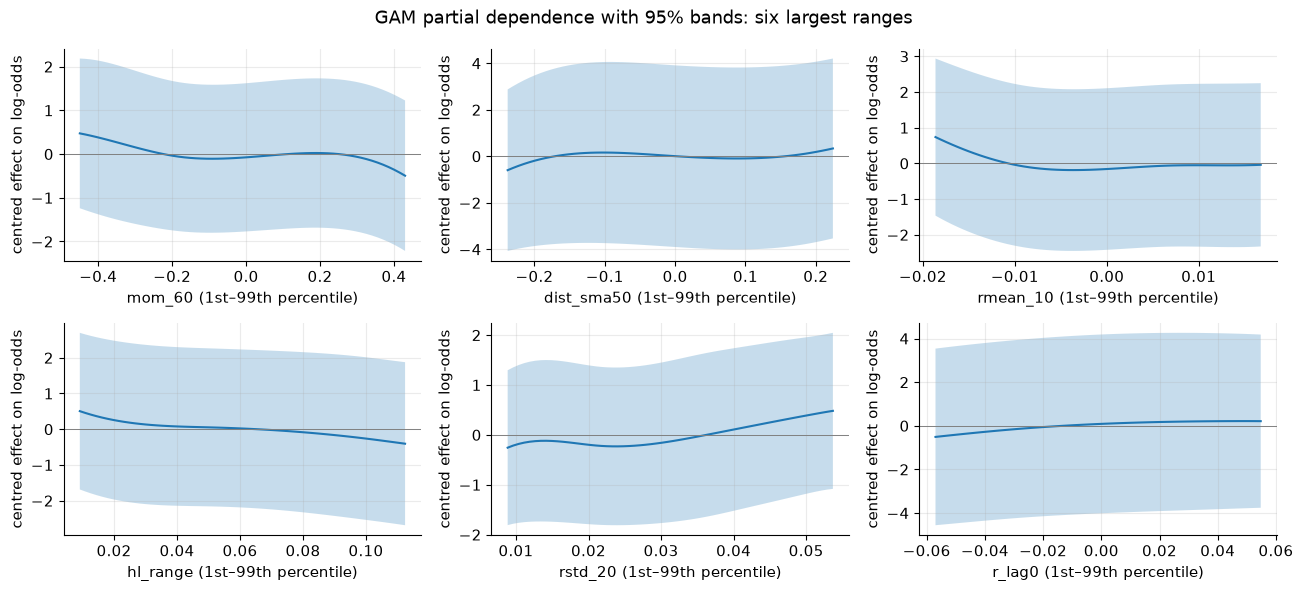

In [39]:
CONT = [i for i, c in enumerate(ENG) if not c.startswith("dow_")]; DUM = [i for i, c in enumerate(ENG) if c.startswith("dow_")]
def make_gam(lam):
    terms = reduce(lambda a, b: a + b, [gam_s(i, n_splines=8, lam=lam) for i in CONT] + [gam_l(i, lam=lam) for i in DUM])
    return LogisticGAM(terms, max_iter=100, tol=1e-4)
lam_grid = [10.0 ** k for k in range(-3, 6)]
from pygam.utils import OptimizationError
def cv_gam_at(lam):
    sc = []
    for a, b in tscv.split(Xr):
        try:
            g_ = make_gam(lam).fit(Xr[a], y5[a]); sc.append(roc_auc_score(y5[b], g_.predict_proba(Xr[b])))
        except OptimizationError:
            return None     # too little penalty for the fit to converge on this fold
    return float(np.mean(sc))
cv_gam = {lam: cv_gam_at(lam) for lam in lam_grid}
gam_diverged = [k for k, v in cv_gam.items() if v is None]; cv_gam = {k: v for k, v in cv_gam.items() if v is not None}
LAM = max(cv_gam, key=cv_gam.get); gam_edge = LAM in (min(cv_gam), max(cv_gam))
print("CV AUC by λ:", {f"{k:g}": round(v, 4) for k, v in cv_gam.items()}, "→ λ =", LAM, "| at edge of the converging range:", gam_edge, "| fit diverged at:", gam_diverged)
gam = make_gam(LAM).fit(Xr, y5)
p_gam = gam.predict_proba(Xrte); rec5("gam", "GAM (LogisticGAM)", "additive", p=p_gam, cv_auc=cv_gam[LAM])
gam_edof = float(gam.statistics_["edof"]); gam_pseudo = float(gam.statistics_["pseudo_r2"]["explained_deviance"])
_pd = []
for t_i, i in enumerate(CONT):
    Xg = gam.generate_X_grid(term=t_i, n=60); pdv, ci = gam.partial_dependence(term=t_i, X=Xg, width=.95)
    # effects are ranked and judged inside the 1st–99th percentile of the feature: beyond that, the spline has almost no data
    _q1, _q99 = np.quantile(Xr[:, i], [.01, .99]); _in = (Xg[:, i] >= _q1) & (Xg[:, i] <= _q99)
    Xg2 = gam.generate_X_grid(term=t_i, n=60); Xg2[:, i] = np.linspace(_q1, _q99, 60); pdv, ci = gam.partial_dependence(term=t_i, X=Xg2, width=.95)
    # pygam's terms are not centred, so each curve is shifted to mean 0; "flat" then means a horizontal line stays inside the band
    _c = pdv.mean(); pdv, ci = pdv - _c, ci - _c
    _pd.append(dict(feature=ENG[i], x=[float(f"{v:.5g}") for v in Xg2[:, i]], y=rnd(pdv, 4), lo=rnd(ci[:, 0], 4), hi=rnd(ci[:, 1], 4), range=float(pdv.max() - pdv.min()), zero_in_band=bool(((ci[:, 0] <= 0) & (ci[:, 1] >= 0)).all()), q01=float(_q1), q99=float(_q99)))
_pd.sort(key=lambda d: -d["range"])
print("Partial-dependence log-odds range, largest first:", {d["feature"]: round(d["range"], 3) for d in _pd[:8]})
print(f"Effective degrees of freedom {gam_edof:.2f}; explained deviance {gam_pseudo:.5f}; curves where a flat line stays inside the 95% band: {sum(d['zero_in_band'] for d in _pd)} of {len(_pd)}")
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a, d in zip(ax.ravel(), _pd[:6]):
    a.plot(d["x"], d["y"]); a.fill_between(d["x"], d["lo"], d["hi"], alpha=.25); a.axhline(0, color="grey", lw=.7); a.set_xlabel(d["feature"] + " (1st–99th percentile)"); a.set_ylabel("centred effect on log-odds")
fig.suptitle("GAM partial dependence with 95% bands: six largest ranges"); plt.tight_layout(); savefig("u5_gam"); plt.show()

## Bayesian model averaging

BMA averages predictions over models, weighted by posterior model probability: `p(up|x) = Σ_m P(M_m|D) p(up|x, M_m)`. With a flat prior over the models considered, `P(M_m|D) ∝ exp(−BIC_m/2)`, which is the standard large-sample approximation to the marginal likelihood.

**Model space:** logistic models on every subset of the 21 standardised features with at most 4 features, including the intercept-only model. Larger subsets are left out because 2²¹ fits would be too many. The mass by subset size below shows whether that truncation matters.

In [40]:
def irls_fit(Phi, t, iters=25, tol=1e-8):
    w = np.zeros(Phi.shape[1]); w[0] = np.log(t.mean() / (1 - t.mean()))
    for _ in range(iters):
        a = Phi @ w; y = 1 / (1 + np.exp(-a)); W = y * (1 - y)
        step = np.linalg.solve((Phi * W[:, None]).T @ Phi, Phi.T @ (t - y)); w += step
        if np.abs(step).max() < tol: break
    a = Phi @ w; ll = -np.logaddexp(0, -a) @ t - np.logaddexp(0, a) @ (1 - t)
    return w, ll

def run_bma(X, t, Xte, max_size=4, keep=2000):
    N, D_ = X.shape; b1 = np.ones((N, 1)); bte = np.ones((len(Xte), 1)); models = []
    for size in range(0, max_size + 1):
        for c_ in itertools.combinations(range(D_), size):
            Phi = np.c_[b1, X[:, c_]] if size else b1
            w, ll = irls_fit(Phi, t.astype(float)); models.append((c_, w, -2 * ll + (size + 1) * np.log(N)))
    bic = np.array([m[2] for m in models]); lw = -.5 * (bic - bic.min()); wts = np.exp(lw); wts /= wts.sum()
    order = np.argsort(-wts); kept = order[:keep]; mass = wts[kept].sum()
    p = np.zeros(len(Xte))
    for i in kept:
        c_, w, _ = models[i]; Phi = np.c_[bte, Xte[:, c_]] if len(c_) else bte; p += wts[i] / (1 + np.exp(-(Phi @ w)))
    p /= mass
    sizes = np.array([len(m[0]) for m in models]); incl = np.zeros(D_)
    for m_, w_ in zip(models, wts): incl[list(m_[0])] += w_
    return dict(p=p, models=models, wts=wts, order=order, sizes=sizes, incl=incl, bic=bic, n_models=len(models), kept_mass=mass, n_kept=len(kept))

bma = run_bma(Xz, y5, Xzte)
rec5("bma", "BMA (logistic subsets)", "bayesian", p=bma["p"], cv_auc=None)
_top = [dict(rank=r_ + 1, features=[ENG[j] for j in bma["models"][i][0]] or ["intercept only"], bic=bma["bic"][i], weight=bma["wts"][i], accuracy=None) for r_, i in enumerate(bma["order"][:10])]
for row in _top:
    c_ = bma["models"][bma["order"][row["rank"] - 1]]; Phi = np.c_[np.ones(len(Xzte)), Xzte[:, c_[0]]] if len(c_[0]) else np.ones((len(Xzte), 1)); row["accuracy"] = float(np.mean((1 / (1 + np.exp(-(Phi @ c_[1]))) > .5) == y5te))
display(pd.DataFrame(_top).round(5))
_size_mass = {int(k): float(bma["wts"][bma["sizes"] == k].sum()) for k in range(5)}
_incl = pd.Series(bma["incl"], index=ENG).sort_values(ascending=False)
print(f"{bma['n_models']} models; {bma['n_kept']} kept for prediction carry {bma['kept_mass']:.6f} of the mass. Mass by subset size: { {k: round(v, 4) for k, v in _size_mass.items()} }. Effective number of models (1/Σw²) = {1/np.sum(bma['wts']**2):.1f}")
print("Inclusion probabilities:", _incl.head(8).round(4).to_dict())

,rank,features,bic,weight,accuracy
0,1,[r_lag2],6109.92710,0.34345,0.52555
1,2,[intercept only],6110.63028,0.24164,0.51946
2,3,"[r_lag2, vol_ratio20]",6114.81181,0.02986,0.50608
3,4,[rmean_20],6114.85671,0.02920,0.50730
4,5,[dist_sma50],6115.08394,0.02607,0.49635
5,6,[vol_ratio20],6115.69807,0.01917,0.52068
6,7,"[r_lag2, rmean_20]",6116.42940,0.01330,0.52311
7,8,"[r_lag2, dist_sma50]",6116.60358,0.01219,0.50852
8,9,[mom_60],6116.85688,0.01074,0.51095
9,10,"[r_lag2, mom_60]",6117.11734,0.00943,0.50487


7547 models; 2000 kept for prediction carry 0.998240 of the mass. Mass by subset size: {0: 0.2416, 1: 0.5043, 2: 0.2059, 3: 0.0425, 4: 0.0056}. Effective number of models (1/Σw²) = 5.5
Inclusion probabilities: {'r_lag2': 0.5467, 'vol_ratio20': 0.0776, 'rmean_20': 0.0631, 'dist_sma50': 0.0569, 'mom_60': 0.0307, 'rmean_10': 0.0234, 'dow_thu': 0.0226, 'r_lag1': 0.0224}


## Leaderboard and feature importance

**Impurity importance** comes from the training fit and is known to favour features with many distinct values. **Permutation importance** is the fall in test AUC when one feature is shuffled, so it measures actual out-of-sample use, averaged over 30 shuffles. These are the same data as the leaderboard, so they explain the models and are not new tests.

,model,group,accuracy,n_correct,n_test,f1,auc,cv_auc,log_loss,p_vs_majority,share_up,auc_in_chance_band
bagging,Bagging,ensemble,0.498783,410,822,0.550218,0.514558,0.527073,0.695797,0.889057,0.594891,True
bma,BMA (logistic subsets),bayesian,0.513382,422,822,0.6633,0.514452,None,0.692839,0.649627,0.925791,True
same_as_today,Same as today,baseline,0.508516,418,822,0.526932,0.50777,None,None,0.746469,0.519465,True
gradient_boosting,Gradient Boosting,ensemble,0.519465,427,822,0.683747,0.503904,0.536713,0.692386,0.514101,1.0,True
gam,GAM (LogisticGAM),additive,0.498783,410,822,0.558887,0.496861,0.527048,0.711731,0.889057,0.616788,True
random_forest,Random Forest,ensemble,0.5,411,822,0.592666,0.492959,0.535357,0.69371,0.875292,0.708029,True
stacking,Stacking (logistic meta),ensemble,0.506083,416,822,0.638146,0.477793,None,0.696179,0.789,0.845499,True
adaboost,AdaBoost,ensemble,0.502433,413,822,0.59545,0.477725,0.532898,0.740259,0.844291,0.710462,True
cart,CART (pruned),tree,0.469586,386,822,0.514477,0.466748,0.498052,0.700424,0.99811,0.572993,True
majority,Majority class,baseline,0.519465,427,822,0.683747,None,None,0.692416,0.514101,1.0,None


Models above the majority rate: 0 of 8; significant at 5%: 0; AUC outside chance band: 0; log-loss better than a constant: 1. Best AUC bagging, best accuracy gradient_boosting. Bonferroni threshold for 8 models: 0.00625


,rf_impurity,gb_impurity,rf_perm,rf_perm_sd,gb_perm,gb_perm_sd
mkt_r,0.14707,0.20547,0.01055,0.00955,0.01561,0.01304
r_lag2,0.13996,0.17232,-0.00375,0.00613,-0.00449,0.00565
vol_ratio20,0.13437,0.15894,-0.01757,0.01245,-0.01197,0.01192
rmean_10,0.11903,0.18338,0.00728,0.00813,0.00878,0.00904
rstd_10,0.06922,0.05547,0.00130,0.00523,0.00202,0.00446
rmean_20,0.04856,0.03749,-0.00253,0.00189,-0.00096,0.00085
rstd_20,0.04759,0.02102,-0.00437,0.00162,-0.00111,0.00110
hl_range,0.04378,0.04874,0.00161,0.00166,0.00209,0.00278
rstd_5,0.04059,0.01270,-0.00173,0.00230,0.00025,0.00081
dist_sma50,0.03763,0.02302,-0.00297,0.00205,-0.00224,0.00138


Permutation importance clearly above 0 (mean − 2 sd > 0) for Random Forest: []; largest 0.0105 (mkt_r); Spearman(impurity, permutation) = -0.082


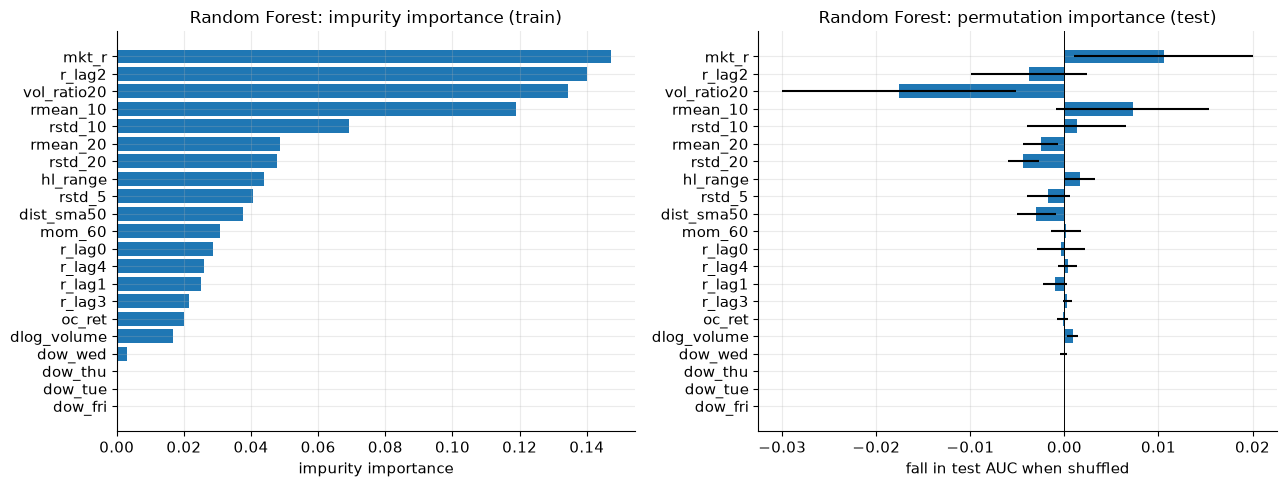

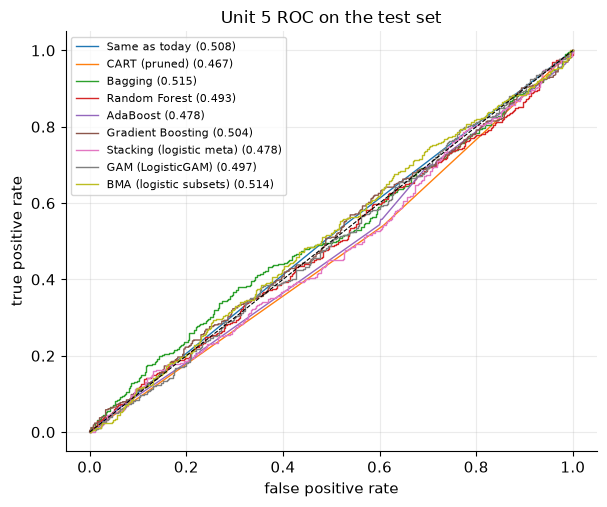

In [41]:
lb = pd.DataFrame(L5).T.drop(columns="key"); display(lb.sort_values("auc", ascending=False))
_mod = lb[lb.group != "baseline"]
n_above = int((_mod.accuracy.astype(float) > mr5).sum()); n_sig = int((_mod.p_vs_majority.astype(float) < .05).sum()); n_outside = int((_mod.auc_in_chance_band == False).sum()); best_auc_k = _mod.auc.astype(float).idxmax(); best_acc_k = _mod.accuracy.astype(float).idxmax()
_ll_better = int((_mod.log_loss.astype(float) < L5["majority"]["log_loss"]).sum())
print(f"Models above the majority rate: {n_above} of {len(_mod)}; significant at 5%: {n_sig}; AUC outside chance band: {n_outside}; log-loss better than a constant: {_ll_better}. Best AUC {best_auc_k}, best accuracy {best_acc_k}. Bonferroni threshold for {len(_mod)} models: {0.05/len(_mod):.5f}")
perm = {}
for name, mdl in [("random_forest", rf), ("gradient_boosting", gb)]:
    pi_ = permutation_importance(mdl, Xrte, y5te, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=1)
    perm[name] = dict(mean=pi_.importances_mean, std=pi_.importances_std)
imp = pd.DataFrame(dict(rf_impurity=rf.feature_importances_, gb_impurity=gb.feature_importances_, rf_perm=perm["random_forest"]["mean"], rf_perm_sd=perm["random_forest"]["std"], gb_perm=perm["gradient_boosting"]["mean"], gb_perm_sd=perm["gradient_boosting"]["std"]), index=ENG).sort_values("rf_impurity", ascending=False)
display(imp.round(5))
_clear = imp[imp.rf_perm - 2 * imp.rf_perm_sd > 0]
_rank_rho = stats.spearmanr(imp.rf_impurity, imp.rf_perm)[0]
print(f"Permutation importance clearly above 0 (mean − 2 sd > 0) for Random Forest: {list(_clear.index)}; largest {imp.rf_perm.max():.4f} ({imp.rf_perm.idxmax()}); Spearman(impurity, permutation) = {_rank_rho:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(13, 5)); _o = imp.sort_values("rf_impurity")
ax[0].barh(_o.index, _o.rf_impurity); ax[0].set_xlabel("impurity importance"); ax[0].set_title("Random Forest: impurity importance (train)")
ax[1].barh(_o.index, _o.rf_perm, xerr=_o.rf_perm_sd); ax[1].axvline(0, color="k", lw=.7); ax[1].set_xlabel("fall in test AUC when shuffled"); ax[1].set_title("Random Forest: permutation importance (test)")
plt.tight_layout(); savefig("u5_importance"); plt.show()
fig, ax = plt.subplots(figsize=(6.2, 5.2))
for k, v in ROC5.items(): ax.plot(v["fpr"], v["tpr"], lw=1, label=f"{L5[k]['model']} ({L5[k]['auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.set_title("Unit 5 ROC on the test set"); ax.legend(fontsize=8); plt.tight_layout(); savefig("u5_roc"); plt.show()

### Robustness check: TCS, HDFCBANK, INFY

Same hyperparameters as chosen on RELIANCE, with no re-tuning.

In [42]:
rob5 = []
for tk in ["TCS", "HDFCBANK", "INFY"]:
    F_, RAW_, T_ = build_features(panel, tk)
    D_ = pd.concat([F_, RAW_, T_], axis=1).dropna(subset=ENG + RAWC + ["close_next", "r_next"]); tr_, te_ = D_[D_.index < TEST_START], D_[D_.index >= TEST_START]
    Xa, Xb, ya, yb = tr_[ENG].values, te_[ENG].values, tr_.y_dir.values.astype(int), te_.y_dir.values.astype(int)
    sc_ = StandardScaler().fit(Xa); mr_ = float(np.mean(yb == int(ya.mean() > .5)))
    row = dict(ticker=tk, n_train=len(ya), n_test=len(yb), majority=mr_)
    ps_ = {k: mk().fit(Xa, ya).predict_proba(Xb)[:, 1] for k, mk in base_makers.items()}
    ps_["bagging"] = BaggingClassifier(DecisionTreeClassifier(random_state=SEED, min_samples_leaf=gs_bag.best_params_["estimator__min_samples_leaf"]), n_estimators=150, max_samples=gs_bag.best_params_["max_samples"], random_state=SEED).fit(Xa, ya).predict_proba(Xb)[:, 1]
    ps_["gam"] = make_gam(LAM).fit(Xa, ya).predict_proba(Xb)
    ps_["bma"] = run_bma(sc_.transform(Xa), ya, sc_.transform(Xb))["p"]
    for k, p_ in ps_.items():
        yh_ = (p_ > .5).astype(int); row[k + "_acc"] = float(np.mean(yh_ == yb)); row[k + "_auc"] = roc_auc_score(yb, p_) if len(np.unique(p_)) > 1 else None
        row[k + "_p"] = stats.binomtest(int((yh_ == yb).sum()), len(yb), mr_, alternative="greater").pvalue
    rob5.append(row)
rob5d = pd.DataFrame(rob5).set_index("ticker"); display(rob5d.T.round(4))
_pcols = [c for c in rob5d.columns if c.endswith("_p")]; _min_p = rob5d[_pcols].min().min(); _acols = [c for c in rob5d.columns if c.endswith("_auc")]
_n_rob_sig = int((rob5d[_pcols] < .05).sum().sum()); _n_rob_tests = int(rob5d[_pcols].size)
print(f"Robustness: {_n_rob_sig} of {_n_rob_tests} model-stock accuracy tests have p < 0.05 (expected by chance about {0.05*_n_rob_tests:.2f}); smallest p {_min_p:.4f}; AUC range {rob5d[_acols].astype(float).min().min():.3f} to {rob5d[_acols].astype(float).max().max():.3f}")

R["u5"] = dict(leaderboard=list(L5.values()), majority_rate=mr5, p_up_train=y5.mean(), auc_low=.5 - half5, auc_high=.5 + half5, n_models=len(_mod), n_above=n_above, n_sig=n_sig, n_auc_outside=n_outside, n_ll_better=_ll_better, best_auc=best_auc_k, best_auc_label=L5[best_auc_k]["model"], best_auc_value=L5[best_auc_k]["auc"], best_acc=best_acc_k, best_acc_label=L5[best_acc_k]["model"], best_acc_value=L5[best_acc_k]["accuracy"], best_acc_p=L5[best_acc_k]["p_vs_majority"], bonferroni=0.05 / len(_mod), cart=_ct, tuning=TUNE, stacking=dict(coef=stack_coef, n_oof=int(_ok.sum()), n_train=len(y5), oof_auc=stack_oof_auc),
    gam=dict(lam=LAM, at_edge=gam_edge, diverged=gam_diverged, cv={f"{k:g}": v for k, v in cv_gam.items()}, edof=gam_edof, explained_deviance=gam_pseudo, n_flat_curves=sum(d["zero_in_band"] for d in _pd), n_curves=len(_pd), top=[d["feature"] for d in _pd[:6]], top_ranges={d["feature"]: d["range"] for d in _pd[:6]}),
    bma=dict(n_models=bma["n_models"], n_kept=bma["n_kept"], kept_mass=bma["kept_mass"], top=_top, size_mass=_size_mass, inclusion=_incl.to_dict(), effective_models=1 / np.sum(bma["wts"] ** 2), top_weight=bma["wts"][bma["order"][0]]),
    importance=dict(top_impurity_perm=imp.rf_perm.iloc[0], clear_rf=list(_clear.index), rf_perm_max=imp.rf_perm.max(), rf_perm_max_feature=imp.rf_perm.idxmax(), spearman=_rank_rho, top_impurity=imp.index[0], rf_impurity_top=imp.rf_impurity.iloc[0]), staged=dict(train_first=_tr_ll[0], train_last=_tr_ll[-1], test_first=_te_ll[0], test_last=_te_ll[-1]),
    robust=rob5, robust_n_sig=_n_rob_sig, robust_n_tests=_n_rob_tests, robust_min_p=_min_p, robust_expected=0.05 * _n_rob_tests, robust_auc_min=rob5d[_acols].astype(float).min().min(), robust_auc_max=rob5d[_acols].astype(float).max().max())
save_results()
chart("u5_tree", dict(nodes=tree_json(cart), n_leaves=int(cart.get_n_leaves()), depth=int(cart.get_depth()), prune=dict(alpha=rnd(_cand, 7), leaves=[int(v) for v in _leaves], train_acc=rnd(_tr_acc, 4), cv_auc=rnd(_cv_c.mean_test_score.values, 4), chosen=float(cart.ccp_alpha))))
chart("u5_roc", dict(curves={k: dict(label=L5[k]["model"], auc=L5[k]["auc"], **ROC5[k]) for k in ROC5}, auc_low=.5 - half5, auc_high=.5 + half5))
chart("u5_importance", dict(features=list(imp.index), rf_impurity=rnd(imp.rf_impurity, 5), gb_impurity=rnd(imp.gb_impurity, 5), rf_perm=rnd(imp.rf_perm, 5), rf_perm_sd=rnd(imp.rf_perm_sd, 5), gb_perm=rnd(imp.gb_perm, 5), gb_perm_sd=rnd(imp.gb_perm_sd, 5)))
chart("u5_gam", dict(curves=_pd, lam=LAM))
chart("u5_bma", dict(top=_top, size_mass=_size_mass, inclusion=_incl.round(5).to_dict()))
chart("u5_staged", dict(rounds=[int(i) for i in _stages[:len(_tr_ll)]], train_ll=rnd(_tr_ll, 5), test_ll=rnd(_te_ll, 5), test_auc=rnd(_te_auc, 4), constant_ll=L5["majority"]["log_loss"]))
_b = L5[best_acc_k]
assert n_sig == 0 and n_outside == 0
_edge_notes = {k: v["at_edge"] for k, v in TUNE.items() if v["at_edge"]}
print("Hyperparameters still at a grid edge:", _edge_notes)
obs(f"No model beats the baseline. The majority rate is {mr5:.4f}; {n_above} of {len(_mod)} models have higher accuracy and **{n_sig} are significant** at 5%, and the best accuracy is {_b['accuracy']:.4f} ({_b['model']}, p = {_b['p_vs_majority']:.3f}), from a model that predicts up on {100*_b['share_up']:.1f}% of days, which makes it the majority rule in practice. {n_outside} AUCs fall outside the chance band [{.5-half5:.3f}, {.5+half5:.3f}], and the best AUC is {L5[best_auc_k]['auc']:.3f} ({L5[best_auc_k]['model']}). "
    f"An illustrative boosting run (learning rate 0.05, depth 2) shows the adaptive-basis trade-off: as trees are added, train log-loss falls from {_tr_ll[0]:.4f} to {_tr_ll[-1]:.4f}, while test log-loss moves from {_te_ll[0]:.4f} to {_te_ll[-1]:.4f} against {L5['majority']['log_loss']:.4f} for a constant prediction. "
    f"**Tuning:** several hyperparameters stay at a grid edge ({', '.join(f'{k}: {list(v)}' for k, v in _edge_notes.items()) or 'none'}). Bagging's max_samples = 1.0 is a natural upper limit. The others point the same way: CV favours weak, heavily restricted learners, because extra flexibility mostly fits noise, and CV AUC moves very little between settings. The GAM's λ = {LAM:g} is at the edge of the range where its fit converges (it diverges at {gam_diverged[0] if gam_diverged else 'no tested value'}), so its curves should be read as rough shapes. "
    f"**GAM:** for {sum(d['zero_in_band'] for d in _pd)} of {len(_pd)} features a flat line stays inside the 95% band, so those effects cannot be told apart from no effect, and explained deviance is {gam_pseudo:.4f}. "
    f"**BMA:** the top model has weight {bma['wts'][bma['order'][0]]:.3f} ({', '.join(_top[0]['features'])}), and subsets of size 4 hold only {100*_size_mass[4]:.2f}% of the mass, so the size limit hardly matters. BMA accuracy is {L5['bma']['accuracy']:.4f}. "
    f"**Importance:** impurity ranks {imp.index[0]} first, but permutation on test is never large (max {imp.rf_perm.max():.4f}), and {'no feature is' if len(_clear) == 0 else str(len(_clear)) + ' feature(s) are'} clearly above 0. Shuffling {imp.index[0]}, the feature the forest used most, {'lowers' if imp.rf_perm.iloc[0] > 0 else 'raises'} test AUC by only {abs(imp.rf_perm.iloc[0]):.4f} (sd {imp.rf_perm_sd.iloc[0]:.4f}), which is within shuffle noise. The rank correlation between the two measures is {_rank_rho:.2f}. "
    f"**Robustness:** {_n_rob_sig} of {_n_rob_tests} model-stock tests have p < 0.05, against about {0.05*_n_rob_tests:.1f} expected by chance.")

ticker,TCS,HDFCBANK,INFY
n_train,3244.0000,4417.0000,4399.0000
n_test,816.0000,816.0000,816.0000
majority,0.5245,0.5061,0.5478
cart_acc,0.5245,0.5012,0.5613
cart_auc,NaN,0.5103,0.5305
cart_p,0.5142,0.6237,0.2303
random_forest_acc,0.5147,0.5233,0.5490
random_forest_auc,0.5259,0.5228,0.5155
random_forest_p,0.7245,0.1723,0.4864
adaboost_acc,0.5147,0.5025,0.5380


Robustness: 0 of 21 model-stock accuracy tests have p < 0.05 (expected by chance about 1.05); smallest p 0.0860; AUC range 0.502 to 0.535
Hyperparameters still at a grid edge: {'bagging': {'max_samples': 1.0}, 'random_forest': {'max_depth': 2, 'max_features': 0.5}, 'gradient_boosting': {'learning_rate': 0.001}}


**Observations.** No model beats the baseline. The majority rate is 0.5195; 0 of 8 models have higher accuracy and **0 are significant** at 5%, and the best accuracy is 0.5195 (Gradient Boosting, p = 0.514), from a model that predicts up on 100.0% of days, which makes it the majority rule in practice. 0 AUCs fall outside the chance band [0.460, 0.540], and the best AUC is 0.515 (Bagging). An illustrative boosting run (learning rate 0.05, depth 2) shows the adaptive-basis trade-off: as trees are added, train log-loss falls from 0.6922 to 0.5747, while test log-loss moves from 0.6928 to 0.7051 against 0.6924 for a constant prediction. **Tuning:** several hyperparameters stay at a grid edge (bagging: ['max_samples'], random_forest: ['max_depth', 'max_features'], gradient_boosting: ['learning_rate']). Bagging's max_samples = 1.0 is a natural upper limit. The others point the same way: CV favours weak, heavily restricted learners, because extra flexibility mostly fits noise, and CV AUC moves very little between settings. The GAM's λ = 0.01 is at the edge of the range where its fit converges (it diverges at 0.001), so its curves should be read as rough shapes. **GAM:** for 17 of 17 features a flat line stays inside the 95% band, so those effects cannot be told apart from no effect, and explained deviance is 0.0195. **BMA:** the top model has weight 0.343 (r_lag2), and subsets of size 4 hold only 0.56% of the mass, so the size limit hardly matters. BMA accuracy is 0.5134. **Importance:** impurity ranks mkt_r first, but permutation on test is never large (max 0.0105), and no feature is clearly above 0. Shuffling mkt_r, the feature the forest used most, lowers test AUC by only 0.0105 (sd 0.0095), which is within shuffle noise. The rank correlation between the two measures is -0.08. **Robustness:** 0 of 21 model-stock tests have p < 0.05, against about 1.1 expected by chance.

# Conclusions and limitations

The summary below is generated from the results above.

In [43]:
_u2 = R["u2_reg"]; _c2 = R["u2_clf"]; _u3 = R["u3"]; _p3 = R["u3_pca"]; _u4 = R["u4"]; _u5 = R["u5"]; _d = R["u1_dist"]; _b1 = R["u1_bayes"]
R["headlines"] = dict(
    u1=dict(kurt=_d["pooled"]["ex_kurt"], tail=_d["reliance"]["tail4"]["ratio"], gauss_var99=_d["reliance"]["gauss_var99"], hist_var99=_d["reliance"]["hist_var99"], V=_b1["V"], chi2_p=_b1["chi2_p"]),
    u2=dict(n_sig_reg=_u2["n_sig_better"], n_sig_clf=_c2["n_beat_sig"], maj=_c2["maj_rate"], pers_rmse=_u2["table"][0]["rmse"]),
    u3=dict(k=_u3["k_chosen"], sil=_u3["sil_chosen"], pc1=_p3["pc1"], pc1_corr=_p3["pc1_corr"], ari=_u3["ari"]["km_6d"], ari_corr=_u3["ari"]["corr_ward"]),
    u4=dict(K=_u4["ew"]["K"], covid=_u4["ew"]["checks"]["covid"]["bear_share"], acc=_u4["forecast"]["ew"]["filtered"]["accuracy"], maj=_u4["forecast"]["ew"]["majority_rate"], gain=_u4["kalman"]["gain"]),
    u5=dict(n_sig=_u5["n_sig"], best_acc=_u5["best_acc_value"], best_label=_u5["best_acc_label"], maj=_u5["majority_rate"], n_models=_u5["n_models"]))
obs(f"**Unit 1.** Returns have a near-zero mean and fat tails (pooled excess kurtosis {_d['pooled']['ex_kurt']:.2f}), so Gaussian VaR understates 99% risk. Direction today is close to independent of direction yesterday (Cramér's V = {_b1['V']:.4f}). "
    f"**Unit 2.** {_u2['n_sig_better']} of {_u2['n_models']} regression models beat persistence significantly, and {_c2['n_beat_sig']} of {_c2['n_models']} classifiers beat the majority rate. "
    f"**Unit 3.** Stocks form a continuum (silhouette {_u3['sil_chosen']:.3f}), with one strong market factor (PC1 {100*_p3['pc1']:.1f}%). "
    f"**Unit 4.** {_u4['ew']['K']} regimes are found, and they differ mainly in volatility; they catch crises but do not forecast direction. "
    f"**Unit 5.** {_u5['n_sig']} of {_u5['n_models']} tree, ensemble, GAM and BMA models beat the majority rate. "
    "Taken together, this is consistent with weak-form market efficiency at the daily horizon: risk is predictable to a degree, but direction is not, at least with these features and models.")
display(Markdown("""**Limitations.**

- Survivorship bias: the universe is the 2021 NIFTY-50 list, so companies that dropped out are missing.
- Corporate actions are found by a rule, not from an official list, so a small action could be missed. One real daily move is lost on each flagged day.
- Dividends are not included, so returns are price returns only.
- Prediction results use one focus stock with a three-stock check, and one chronological split whose test window includes the COVID crash.
- Same-day observations across stocks are correlated, so pooled p-values are optimistic.
- No transaction costs are modelled. They would only make any trading rule look worse.
- With 49 stocks, the clustering results are descriptive."""))

**Observations.** **Unit 1.** Returns have a near-zero mean and fat tails (pooled excess kurtosis 7.40), so Gaussian VaR understates 99% risk. Direction today is close to independent of direction yesterday (Cramér's V = 0.0032). **Unit 2.** 0 of 10 regression models beat persistence significantly, and 0 of 6 classifiers beat the majority rate. **Unit 3.** Stocks form a continuum (silhouette 0.264), with one strong market factor (PC1 30.2%). **Unit 4.** 3 regimes are found, and they differ mainly in volatility; they catch crises but do not forecast direction. **Unit 5.** 0 of 8 tree, ensemble, GAM and BMA models beat the majority rate. Taken together, this is consistent with weak-form market efficiency at the daily horizon: risk is predictable to a degree, but direction is not, at least with these features and models.

**Limitations.**

- Survivorship bias: the universe is the 2021 NIFTY-50 list, so companies that dropped out are missing.
- Corporate actions are found by a rule, not from an official list, so a small action could be missed. One real daily move is lost on each flagged day.
- Dividends are not included, so returns are price returns only.
- Prediction results use one focus stock with a three-stock check, and one chronological split whose test window includes the COVID crash.
- Same-day observations across stocks are correlated, so pooled p-values are optimistic.
- No transaction costs are modelled. They would only make any trading rule look worse.
- With 49 stocks, the clustering results are descriptive.

# Export

All results and chart data are written out here for the results explorer. Daily chart series are reduced to about 1,500 points or fewer, keeping each bucket's minimum and maximum, so crash extremes survive.

In [44]:
save_results()
with open(os.path.join(WEB_DATA, "results.json"), "w") as f:
    json.dump(_clean(R), f, separators=(",", ":"), sort_keys=True, ensure_ascii=False)
for name, obj in CHARTS.items():
    with open(os.path.join(WEB_DATA, name + ".json"), "w") as f:
        json.dump(_clean(obj), f, separators=(",", ":"), sort_keys=True, ensure_ascii=False)
_sizes = {n: os.path.getsize(os.path.join(WEB_DATA, n + ".json")) // 1024 for n in sorted(CHARTS)}
print("results.json KB:", os.path.getsize(os.path.join(WEB_DATA, "results.json")) // 1024)
print("chart files (KB):", _sizes)
print("figures:", sorted(os.listdir(FIG_DIR)))

results.json KB: 53
chart files (KB): {'adjust_before_after': 30, 'leakage': 1, 'u1_distributions': 364, 'u1_heatmaps': 16, 'u1_per_stock_bayes': 7, 'u1_poly': 59, 'u1_stock_table': 15, 'u2_pred': 74, 'u2_ridge': 9, 'u2_roc': 34, 'u3_clusters': 14, 'u3_contingency': 0, 'u3_dendrogram': 22, 'u3_gmm': 8, 'u3_pc1_series': 21, 'u3_pca': 8, 'u4_forecast': 74, 'u4_kalman': 83, 'u4_lookahead': 13, 'u4_regimes': 59, 'u5_bma': 1, 'u5_gam': 33, 'u5_importance': 1, 'u5_roc': 35, 'u5_staged': 1, 'u5_tree': 2}
figures: ['p0_adjustment.png', 'u1_bayes_per_stock.png', 'u1_distributions.png', 'u1_heatmaps.png', 'u1_polynomial.png', 'u2_blr_band.png', 'u2_ridge_path.png', 'u2_roc.png', 'u3_dendrograms.png', 'u3_gmm_em.png', 'u3_kmeans_k.png', 'u3_pca.png', 'u4_kalman.png', 'u4_regimes.png', 'u5_cart.png', 'u5_gam.png', 'u5_importance.png', 'u5_roc.png']
